# Análisis de Skim Matrices (TTC y DIST) con filtro de pares imposibles (filtro 2)

Mismo análisis que `skims_analisis_filtro.ipynb`, ahora con la base de skims del 27/10/26 (`skim_matrices/skims_271026`).

- **TTC:** tiempo de viaje (min)
- **DIST:** recorrido de zona a zona (km)
- Análisis de transporte privado (Auto + Heavy Freight + Light Freight) en 4 periodos

| Periodo | Nombre | Horario |
|---|---|---|
| AP | AM Peak | 04:00 a 08:59 |
| LM | Late Morning | 09:00 a 11:59 |
| EA | Early Afternoon | 12:00 a 17:59 |
| PP | PM Peak | 18:00 a 20:59 |

In [1]:
%matplotlib inline

import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import folium
from folium.plugins import PolyLineTextPath
from branca.colormap import LinearColormap
from shapely.geometry import LineString
from IPython.display import display

In [2]:
# Entradas: skims nuevas (27/10/26); demanda y zonas son las mismas de la versión original
BASE = r"C:\proyectos\red-vial-guadalajara"
SKIM_MATRICES = os.path.join(BASE, "skim_matrices")
SKIMS = os.path.join(SKIM_MATRICES, "skims_271026")
DEMANDA = os.path.join(BASE, "demanda_pf", "Demanda x PF")
ZONAS_DIR = os.path.join(SKIM_MATRICES, "zonas_2105")
SHAPE = os.path.join(ZONAS_DIR, "zonas_2105.shp")

# Salidas: carpeta propia y sufijo en cada archivo para no confundirlos con los del filtro 1
SUFIJO = "_filtro_2"
RESULTADOS = os.path.join(SKIM_MATRICES, "resultados_filtro_2")
R_TABLAS = os.path.join(RESULTADOS, "tablas")
R_EXCEL = os.path.join(RESULTADOS, "excel")
R_MAPAS = os.path.join(RESULTADOS, "mapas_html")
for carpeta in [R_TABLAS, R_EXCEL, R_MAPAS]:
    os.makedirs(carpeta, exist_ok=True)

In [3]:
PERIODOS = ["AP", "LM", "EA", "PP"]
TIPOS = ["TTC", "DIST"]
MODOS = ["VP", "HEAVY_FREIGHT", "LIGHT_FREIGHT"]
NOMBRES_MODO = {"VP": "Autos (VP)", "HEAVY_FREIGHT": "Carga pesada", "LIGHT_FREIGHT": "Carga ligera"}
N_ZONAS = 2105

# Reglas de pares (se describen en la sección "Definición de pares válidos e imposibles")
SIN_RUTA = 999999                                       # TTC o DIST mayor o igual a este valor: par sin ruta
TTC_MIN = 0.5                                           # min; entre zonas distintas, menos de 30 s es imposible
VEL_MIN = 5                                             # km/h; velocidad menor a este valor es imposible
VEL_MAX_POR_DIST = [(2, 60), (10, 80), (np.inf, 110)]   # (DIST hasta km, velocidad máxima en km/h)
FACTOR_RECTA_MIN = 0.5                                  # DIST menor a 0.5 veces la línea recta es imposible
FACTOR_RODEO = 3                                        # sospecha: DIST mayor a 3 veces la línea recta
RECTA_MIN_RODEO = 1                                     # km; el rodeo solo se revisa con línea recta mayor a 1 km
FACTOR_ASIMETRIA = 3                                    # sospecha: TTC de ida mayor a 3 veces el de regreso
TTC_MIN_ASIMETRIA = 1                                   # min; la asimetría solo se revisa si ida y regreso pasan de 1 min
VEL_LENTO = 20                                          # km/h; los pares válidos de VEL_MIN a VEL_LENTO se analizan como lentos
VEL_TOPE = VEL_MAX_POR_DIST[-1][1]                      # velocidad máxima en cualquier distancia

# Análisis y gráficas
UMBRALES = {"TTC": 75, "DIST": 60}      # umbrales fijos de pares llamativos
TOP = 200                               # pares con más viajes en los mapas
TOP_MODO = 50                           # pares con más viajes por tipo de vehículo
MIN_VIAJES = 100                        # zonas con al menos 100 viajes de salida en las tablas
VEL_MIN_COLOR, VEL_MAX_COLOR = 10, 60   # escala de color de velocidad en los mapas

BINS_HIST = {
    "TTC":  (list(range(0, 185, 5)) + [np.inf], [f"{i}-{i+5}" for i in range(0, 180, 5)] + ["180+"], "min"),
    "DIST": (list(range(0, 105, 5)) + [np.inf], [f"{i}-{i+5}" for i in range(0, 100, 5)] + ["100+"], "km"),
}
BINS_VEL = [0, VEL_MIN, VEL_LENTO, 40, 60, 80, 110, 120, np.inf]
LABELS_VEL = ["<5 caminar", "5-20 congestión", "20-40 urbano", "40-60 avenida",
              "60-80 Periférico", "80-110 carretera", "110-120 límite autopista", ">120"]

In [4]:
# Zonas de Visum: la fila i de la skim corresponde a la zona zonas[i] (id_visum ordenados de menor a mayor)
zonas_geo = gpd.read_file(SHAPE)
zonas = sorted(zonas_geo["id_visum"].tolist())
posicion = {z: i for i, z in enumerate(zonas)}
municipio = zonas_geo.set_index("id_visum")["nombre_mun"]
centros = zonas_geo.set_index("id_visum").geometry.centroid
centro_x = centros.reindex(zonas).x.to_numpy()   # por fila de la skim, en metros
centro_y = centros.reindex(zonas).y.to_numpy()
xmin, ymin, xmax, ymax = zonas_geo[zonas_geo["id_visum"] < 10000].total_bounds

# Zonas para los mapas HTML: geometría simplificada a 10 m para reducir el tamaño de los archivos
zonas_4326 = zonas_geo[["id_visum", "nombre_mun"]].set_geometry(zonas_geo.geometry.simplify(10)).to_crs(4326)

In [5]:
def guardar_csv(df, nombre, index=False):
    ruta = os.path.join(R_TABLAS, f"{nombre}{SUFIJO}.csv")
    df.to_csv(ruta, index=index)
    print("Guardado en", ruta)


def lineas_de(c, col_origen="Origin_zona", col_destino="Destination_zona"):
    geometria = [LineString([centros[o], centros[d]]) for o, d in zip(c[col_origen], c[col_destino])]
    return gpd.GeoDataFrame(c, geometry=geometria, crs=zonas_geo.crs)

## Definición de pares válidos e imposibles
Se revisan los pares fuera de la diagonal y con ruta (TTC y DIST menores a 999999). Un par es imposible si cumple alguna de estas reglas:
- TTC igual a 0 con DIST mayor a 0
- TTC menor a 30 s
- velocidad menor a 5 km/h
- velocidad mayor al tope según la distancia: 60 km/h hasta 2 km, 80 km/h de 2 a 10 km y 110 km/h en más de 10 km
- DIST menor a la mitad de la línea recta entre centroides

Sospechosos (se reportan pero no se quitan): DIST mayor a 3 veces la línea recta (rodeo) y TTC de ida 3 veces mayor o menor que el de regreso (asimetría).

Los umbrales están en la celda de constantes del inicio.

In [6]:
REGLAS_IMPOSIBLE = ["ttc_cero", "ttc_minimo", "vel_baja", "vel_alta", "ruta_corta"]
REGLAS_SOSPECHA = ["rodeo", "asimetria"]
CATEGORIAS = ["diagonal", "sin_ruta", "imposible", "valido"]

texto_vel_max = ", ".join(f"{vel} km/h hasta {dist} km" if np.isfinite(dist) else f"{vel} km/h en más distancia"
                          for dist, vel in VEL_MAX_POR_DIST)
REGLAS = pd.DataFrame([
    {"Regla": "diagonal", "Tipo": "categoría", "Condición": "Origen igual a destino"},
    {"Regla": "sin_ruta", "Tipo": "categoría", "Condición": f"TTC o DIST mayor o igual a {SIN_RUTA}, o sin valor en la skim"},
    {"Regla": "ttc_cero", "Tipo": "imposible", "Condición": "TTC igual a 0 y DIST mayor a 0"},
    {"Regla": "ttc_minimo", "Tipo": "imposible", "Condición": f"TTC mayor a 0 y menor a {TTC_MIN} min"},
    {"Regla": "vel_baja", "Tipo": "imposible", "Condición": f"Velocidad menor a {VEL_MIN} km/h"},
    {"Regla": "vel_alta", "Tipo": "imposible", "Condición": f"Velocidad mayor al máximo por distancia: {texto_vel_max}"},
    {"Regla": "ruta_corta", "Tipo": "imposible", "Condición": f"DIST menor a {FACTOR_RECTA_MIN} veces la línea recta entre centroides"},
    {"Regla": "rodeo", "Tipo": "sospecha",
     "Condición": f"DIST mayor a {FACTOR_RODEO} veces la línea recta, con línea recta mayor a {RECTA_MIN_RODEO} km"},
    {"Regla": "asimetria", "Tipo": "sospecha",
     "Condición": f"TTC de ida mayor a {FACTOR_ASIMETRIA} veces el de regreso o al revés, ambos mayores a {TTC_MIN_ASIMETRIA} min"},
    {"Regla": "valido", "Tipo": "categoría", "Condición": "Par revisado sin ninguna regla de imposibilidad"},
])
REGLAS

,Regla,Tipo,Condición
0,diagonal,categoría,Origen igual a destino
1,sin_ruta,categoría,"TTC o DIST mayor o igual a 999999, o sin valor..."
2,ttc_cero,imposible,TTC igual a 0 y DIST mayor a 0
3,ttc_minimo,imposible,TTC mayor a 0 y menor a 0.5 min
4,vel_baja,imposible,Velocidad menor a 5 km/h
5,vel_alta,imposible,Velocidad mayor al máximo por distancia: 60 km...
6,ruta_corta,imposible,DIST menor a 0.5 veces la línea recta entre ce...
7,rodeo,sospecha,"DIST mayor a 3 veces la línea recta, con línea..."
8,asimetria,sospecha,TTC de ida mayor a 3 veces el de regreso o al ...
9,valido,categoría,Par revisado sin ninguna regla de imposibilidad


In [7]:
UMBRALES_IMPOSIBLE = {"ttc_min": TTC_MIN, "vel_min": VEL_MIN, "vel_max_por_dist": VEL_MAX_POR_DIST,
                      "factor_recta_min": FACTOR_RECTA_MIN}
matrices_ttc = {}   # TTC por periodo como matriz (fila origen, columna destino), para la asimetría


def vel_maxima(dist, bandas):
    return np.select([dist <= hasta for hasta, _ in bandas], [vel for _, vel in bandas], default=bandas[-1][1])


def reglas_imposible(df, **cambios):
    """Una serie booleana por regla de imposibilidad; cambios permite probar otros umbrales."""
    u = {**UMBRALES_IMPOSIBLE, **cambios}
    rev, ttc, dist, vel = df["revisado"], df["TTC"], df["DIST"], df["VEL_kmh"]
    return {
        "ttc_cero": rev & (ttc == 0) & (dist > 0),
        "ttc_minimo": rev & (ttc > 0) & (ttc < u["ttc_min"]),
        "vel_baja": rev & (vel < u["vel_min"]),
        "vel_alta": rev & (vel > vel_maxima(dist, u["vel_max_por_dist"])),
        "ruta_corta": rev & (dist < u["factor_recta_min"] * df["RECTA_km"]),
    }


def clasificar_pares(df, p):
    """Clasifica cada par de df (Origin, Destination, TTC y DIST del periodo p) con las reglas de pares."""
    o, d = df["Origin"].to_numpy(), df["Destination"].to_numpy()
    diagonal = df["Origin"] == df["Destination"]
    sin_ruta = ~diagonal & ((df["TTC"] >= SIN_RUTA) | (df["DIST"] >= SIN_RUTA) | df["TTC"].isna() | df["DIST"].isna())
    df["diagonal"] = diagonal
    df["sin_ruta"] = sin_ruta
    df["revisado"] = ~diagonal & ~sin_ruta
    df["VEL_kmh"] = (df["DIST"] / (df["TTC"] / 60)).where(df["revisado"] & (df["TTC"] > 0))
    df["RECTA_km"] = (np.hypot(centro_x[o] - centro_x[d], centro_y[o] - centro_y[d]) / 1000).astype("float32")
    ttc_regreso = pd.Series(matrices_ttc[p][d, o], index=df.index)

    for regla, marca in reglas_imposible(df).items():
        df[regla] = marca
    df["imposible"] = df[REGLAS_IMPOSIBLE].any(axis=1)
    df["valido"] = df["revisado"] & ~df["imposible"]

    rev = df["revisado"]
    ida_regreso = df["TTC"] / ttc_regreso
    df["rodeo"] = rev & (df["RECTA_km"] > RECTA_MIN_RODEO) & (df["DIST"] > FACTOR_RODEO * df["RECTA_km"])
    df["asimetria"] = (rev & (df["TTC"] > TTC_MIN_ASIMETRIA) & (ttc_regreso > TTC_MIN_ASIMETRIA)
                       & (ttc_regreso < SIN_RUTA)
                       & ((ida_regreso > FACTOR_ASIMETRIA) | (ida_regreso < 1 / FACTOR_ASIMETRIA)))
    df["sospechoso"] = df[REGLAS_SOSPECHA].any(axis=1)

    codigos = np.select([diagonal, sin_ruta, df["imposible"]], [0, 1, 2], 3).astype("int8")
    df["Categoria"] = pd.Categorical.from_codes(codigos, categories=CATEGORIAS)
    return df

## Bases de datos

In [8]:
# Ejemplo de cómo se ven las skims, en este caso tiempo de zona a zona en am peak
pd.read_csv(os.path.join(SKIMS, "TTC_AP.csv"), nrows=10, usecols=range(11))

,Unnamed: 0,0,1,2,3,4,5,6,7,8,9
0,0,0.0,999999.0,999999.0,999999.0,999999.0,999999.0,999999.0,999999.000000,999999.0,999999.0
1,1,999999.0,0.0,999999.0,999999.0,999999.0,999999.0,999999.0,999999.000000,999999.0,999999.0
2,2,999999.0,999999.0,0.0,999999.0,999999.0,999999.0,999999.0,999999.000000,999999.0,999999.0
3,3,999999.0,999999.0,999999.0,0.0,999999.0,999999.0,999999.0,999999.000000,999999.0,999999.0
4,4,999999.0,999999.0,999999.0,999999.0,0.0,999999.0,999999.0,999999.000000,999999.0,999999.0
5,5,999999.0,999999.0,999999.0,999999.0,999999.0,0.0,999999.0,2.687634,999999.0,999999.0
6,6,999999.0,999999.0,999999.0,999999.0,999999.0,999999.0,0.0,999999.000000,999999.0,999999.0
7,7,999999.0,999999.0,999999.0,999999.0,999999.0,999999.0,999999.0,0.000000,999999.0,999999.0
8,8,999999.0,999999.0,999999.0,999999.0,999999.0,999999.0,999999.0,999999.000000,0.0,999999.0
9,9,999999.0,999999.0,999999.0,999999.0,999999.0,999999.0,999999.0,999999.000000,999999.0,0.0


In [9]:
# Demanda autos (ejemplo AP)
pd.read_csv(os.path.join(DEMANDA, "matriz_VP_AP.csv")).head(10)

,Hora_inicio,Grupo modal del viaje,Modo,Origen,Destino,Ponderador,Origen_ageb,Destino_ageb,Periodo,Peak Factor,Ponderador_x_PF
0,4,2.- Transporte particular,Transporte Privado,140440011,1404400010100,27,1900,1005,AP,0.367659,9.926788
1,4,2.- Transporte particular,Transporte Privado,140440011,140970005034A,27,1900,5036,AP,0.367659,9.926788
2,4,2.- Transporte particular,Transporte Privado,141011963,999990005,18,7901,10005,AP,0.367659,6.617859
3,4,2.- Transporte particular,Transporte Privado,141011963,1410100010950,144,7901,7053,AP,0.367659,52.942869
4,4,2.- Transporte particular,Transporte Privado,141240029,141240029,9,9901,9901,AP,0.367659,3.308929
5,4,2.- Transporte particular,Transporte Privado,999990004,1412000010369,137,10004,8008,AP,0.367659,50.369257
6,4,2.- Transporte particular,Transporte Privado,999990004,141200758080A,59,10004,8524,AP,0.367659,21.691870
7,4,2.- Transporte particular,Transporte Privado,999990005,140440002012A,7,10005,1015,AP,0.367659,2.573612
8,4,2.- Transporte particular,Transporte Privado,1403900010026,1412000013325,178,1,8173,AP,0.367659,65.443268
9,4,2.- Transporte particular,Transporte Privado,1403900010204,1403900010223,226,11,12,AP,0.367659,83.090891


In [10]:
# Demanda carga pesada y ligera (ejemplo AP)
display(pd.read_csv(os.path.join(DEMANDA, "matriz_HEAVY_FREIGHT_AP.csv")).head(10))
display(pd.read_csv(os.path.join(DEMANDA, "matriz_LIGHT_FREIGHT_AP.csv")).head(10))

,Modo,Hora,Origen,Destino,Origen_ageb,Destino_ageb,Ponderador,hora_inicio,Periodo,Peak Factor,Ponderador_x_PF
0,HEAVY_FREIGHT,06:00-06:59,141200265,EXT_CHAPALA,8005,10005,16.825,6,AP,0.367659,6.185859
1,HEAVY_FREIGHT,06:00-06:59,EXT_ZAPOTLANEJO_CUOTA,EXT_ZAPOTLANEJO_CUOTA,10004,10004,15.436,6,AP,0.367659,5.675181
2,HEAVY_FREIGHT,06:00-06:59,140392569,EXT_ZAPOTLANEJO_CUOTA,210,10004,11.241,6,AP,0.367659,4.132853
3,HEAVY_FREIGHT,06:00-06:59,EXT_ZAPOTLANEJO_CUOTA,140395366,10004,412,9.610,6,AP,0.367659,3.533201
4,HEAVY_FREIGHT,06:00-06:59,EXT_COLIMA,EXT_ZAPOTLANEJO_CUOTA,10006,10004,9.268,6,AP,0.367659,3.407462
5,HEAVY_FREIGHT,06:00-06:59,EXT_ZAPOTLANEJO_CUOTA,140972505,10004,5164,7.357,6,AP,0.367659,2.704866
6,HEAVY_FREIGHT,06:00-06:59,EXT_ZAPOTLANEJO_CUOTA,140981059,10004,6036,7.357,6,AP,0.367659,2.704866
7,HEAVY_FREIGHT,06:00-06:59,EXT_ZAPOTLANEJO_CUOTA,EXT_TEPIC,10004,10001,7.357,6,AP,0.367659,2.704866
8,HEAVY_FREIGHT,06:00-06:59,EXT_ZAPOTLANEJO_CUOTA,EXT_TEPIC,10004,10001,7.357,6,AP,0.367659,2.704866
9,HEAVY_FREIGHT,06:00-06:59,140393707,EXT_ZAPOTLANEJO_CUOTA,260,10004,7.071,6,AP,0.367659,2.599715


,Modo,Hora,Origen,Destino,Origen_ageb,Destino_ageb,Ponderador,hora_inicio,Periodo,Peak Factor,Ponderador_x_PF
0,LIGHT_FREIGHT,06:00-06:59,EXT_ZAPOTLANEJO_CUOTA,EXT_TEPIC,10004,10001,15.012,6,AP,0.367659,5.519294
1,LIGHT_FREIGHT,06:00-06:59,EXT_COLIMA,EXT_CHAPALA,10006,10005,9.611,6,AP,0.367659,3.533569
2,LIGHT_FREIGHT,06:00-06:59,14120002A,140390308,8901,18,9.536,6,AP,0.367659,3.505994
3,LIGHT_FREIGHT,06:00-06:59,140395366,EXT_TEPIC,412,10001,8.561,6,AP,0.367659,3.147527
4,LIGHT_FREIGHT,06:00-06:59,14039261A,EXT_ZAPOTLANEJO_CUOTA,215,10004,8.481,6,AP,0.367659,3.118114
5,LIGHT_FREIGHT,06:00-06:59,140392605,EXT_COLIMA,214,10006,8.121,6,AP,0.367659,2.985757
6,LIGHT_FREIGHT,06:00-06:59,EXT_ZAPOTLANEJO_CUOTA,140394584,10004,339,7.606,6,AP,0.367659,2.796413
7,LIGHT_FREIGHT,06:00-06:59,140980718,140982428,6023,6131,6.863,6,AP,0.367659,2.523242
8,LIGHT_FREIGHT,06:00-06:59,EXT_TEPIC,141202384,10001,8091,6.224,6,AP,0.367659,2.288308
9,LIGHT_FREIGHT,06:00-06:59,EXT_TEPIC,EXT_TEPIC,10001,10001,6.224,6,AP,0.367659,2.288308


In [11]:
# Zonas de Visum
print(zonas_geo.shape)
zonas_geo.head(10)

(2105, 20)


,fid,clave_ageb,clave_enti,clave_muni,clave_loca,ageb,nombre_mun,tipo_ageb,poblacion_,area_m2,area_km2,establecim,empleados_,densidad_p,densidad_e,densidad_1,distancia_,consecutiv,id_visum,geometry
0,2207.0,999990001,NaN,0,NaN,TEPIC,Acceso_Vallarta,acceso_carretero,NaN,8.831629e+05,0.883163,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10001,"POLYGON ((2322972.333 977220.634, 2322945.043 ..."
1,2208.0,999990002,NaN,0,NaN,COLOTÁN,Acceso_Colotlan,acceso_carretero,NaN,8.815265e+05,0.881527,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10002,"POLYGON ((2353431.681 1000208.322, 2353404.683..."
2,2209.0,999990003,NaN,0,NaN,SALTILLO,Acceso_Saltillo,acceso_carretero,NaN,8.825597e+05,0.882560,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10003,"POLYGON ((2366603.688 980406.855, 2366576.776 ..."
3,2210.0,999990004,NaN,0,NaN,ZAPO CUOTA,Acceso_Zapotlanejo_Cuota,acceso_carretero,NaN,8.841967e+05,0.884197,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10004,"POLYGON ((2406732.663 970394.079, 2406705.908 ..."
4,2212.0,999990005,NaN,0,NaN,CHAPALA,Acceso_Chapala,acceso_carretero,NaN,8.857317e+05,0.885732,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10005,"POLYGON ((2376622.799 921163.05, 2376596.042 9..."
5,2206.0,999990006,NaN,0,NaN,COLIMA,Acceso_Lopez_Mateos,acceso_carretero,NaN,8.855748e+05,0.885575,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10006,"POLYGON ((2337406.174 932746.039, 2337378.89 9..."
6,2211.0,999990007,NaN,0,NaN,ZAPO LIBRE,Acceso_Zapotlanejo_Libre,acceso_carretero,NaN,8.844008e+05,0.884401,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10007,"POLYGON ((2406070.875 940531.603, 2406044.128 ..."
7,2205.0,999990008,NaN,0,NaN,OCOTLAN,Acceso_Ocotlan,acceso_carretero,NaN,8.857317e+05,0.885732,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10008,"POLYGON ((2397004.785 932025.82, 2396978.029 9..."
8,2204.0,99999000A,NaN,0,NaN,AERO,Tlajomulco de Zúñiga,aeropuerto,NaN,4.770549e+06,4.770549,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10009,"POLYGON ((2363654.887 946588.466, 2361994.858 ..."
9,2.0,1403900010026,14.0,39,1.0,0026,Guadalajara,urbano,1433.0,4.719139e+05,0.471914,67.0,1529.814941,3036.571136,141.975064,3241.724978,5.583186,1.0,1,"POLYGON ((2356822.264 967782.506, 2356822.889 ..."


## Formato largo
Una tabla por periodo con TTC, DIST y la clasificación de cada par.

In [12]:
def matrix_wide_to_long(df, value_name):
    origin_col = df.columns[0]
    long = df.melt(id_vars=origin_col, var_name="Destination", value_name=value_name)
    long = long.rename(columns={origin_col: "Origin"})
    long["Origin"] = pd.to_numeric(long["Origin"], errors="coerce")
    long["Destination"] = pd.to_numeric(long["Destination"], errors="coerce")
    long[value_name] = pd.to_numeric(long[value_name], errors="coerce")
    return long.dropna(subset=["Origin", "Destination", value_name])

In [13]:
skims_od = {}
filas_formato = []
for p in PERIODOS:
    largos = {}
    for tipo in TIPOS:
        ancho = pd.read_csv(os.path.join(SKIMS, f"{tipo}_{p}.csv"))
        ids_fila = ancho.iloc[:, 0].astype(str).tolist()
        largos[tipo] = matrix_wide_to_long(ancho, tipo)
        filas_formato.append({
            "Matriz": f"{tipo}_{p}",
            "Filas": ancho.shape[0],
            "Columnas": ancho.shape[1],
            "Filas == columnas": ids_fila == list(ancho.columns[1:]),
            "Pares en formato largo": len(largos[tipo]),
            "Pares esperados": N_ZONAS**2,
        })
    od = largos["TTC"].merge(largos["DIST"], on=["Origin", "Destination"]).astype({"Origin": "int32", "Destination": "int32"})
    matriz = np.full((N_ZONAS, N_ZONAS), np.nan)
    matriz[od["Origin"], od["Destination"]] = od["TTC"]
    matrices_ttc[p] = matriz
    skims_od[p] = clasificar_pares(od, p)
del ancho, largos, od, matriz

formato_largo = pd.DataFrame(filas_formato)
formato_largo

,Matriz,Filas,Columnas,Filas == columnas,Pares en formato largo,Pares esperados
0,TTC_AP,2105,2106,True,4431025,4431025
1,DIST_AP,2105,2106,True,4431025,4431025
2,TTC_LM,2105,2106,True,4431025,4431025
3,DIST_LM,2105,2106,True,4431025,4431025
4,TTC_EA,2105,2106,True,4431025,4431025
5,DIST_EA,2105,2106,True,4431025,4431025
6,TTC_PP,2105,2106,True,4431025,4431025
7,DIST_PP,2105,2106,True,4431025,4431025


Se valida que todas sean matrices cuadradas y estén alineadas origen y destino. Esperado: 2105 x 2105 = 4,431,025 pares por matriz.

In [14]:
# Exportar formato largo: solo pares con ruta (fuera de la diagonal y menores a 999999); los demás valen 999999
skims_largo = pd.concat([
    skims_od[p].loc[skims_od[p]["revisado"], ["Origin", "Destination", "TTC", "DIST", "VEL_kmh", "RECTA_km", "Categoria"]
                    + REGLAS_SOSPECHA].assign(Periodo=p)
    for p in PERIODOS
]).rename(columns={"Origin": "Fila_origen", "Destination": "Fila_destino"})
skims_largo.insert(2, "Zona_origen", [zonas[f] for f in skims_largo["Fila_origen"]])
skims_largo.insert(3, "Zona_destino", [zonas[f] for f in skims_largo["Fila_destino"]])
skims_largo = skims_largo[["Periodo"] + [c for c in skims_largo.columns if c != "Periodo"]]
guardar_csv(skims_largo, "skims_formato_largo")
skims_largo.groupby("Periodo").size().reindex(PERIODOS).rename("Pares con ruta").to_frame()

Guardado en C:\proyectos\red-vial-guadalajara\skim_matrices\resultados_filtro_2\tablas\skims_formato_largo_filtro_2.csv


,Pares con ruta
Periodo,
AP,8405
LM,4209
EA,12264
PP,5663


## 5. Clasificación de pares
- **Diagonal:** origen igual a destino
- **Sin ruta:** valor mayor o igual a 999999
- **Cero fuera de diagonal:** zonas distintas con 0 (su trayectoria y tiempo de traslado es 0, sospechoso)
- **Con valor:** fuera de diagonal, con TTC y DIST mayores a 0 (en la versión original se llamaban válidos)

Con esta base solo tienen ruta los pares con demanda: de 4,209 (LM) a 12,264 (EA) pares por periodo, 0.09 a 0.28 % de la skim. Todos los demás valen 999999. Por eso cientos de zonas salen sin ruta en la celda siguiente: son zonas sin viajes en ese periodo.

In [15]:
filas_pares = []
for tipo in TIPOS:
    for p in PERIODOS:
        od = skims_od[p]
        sin_ruta = od[tipo] >= SIN_RUTA
        od[f"con_valor_{tipo}"] = ~od["diagonal"] & ~sin_ruta & (od[tipo] > 0)
        filas_pares.append({
            "Matriz": f"{tipo}_{p}",
            "Pares": len(od),
            "Diagonal": od["diagonal"].sum(),
            "Cero fuera diag": ((od[tipo] == 0) & ~od["diagonal"]).sum(),
            "Sin ruta": sin_ruta.sum(),
            "Con valor": od[f"con_valor_{tipo}"].sum(),
            "% con valor": round(od[f"con_valor_{tipo}"].mean() * 100, 2),
        })

resumen_pares = pd.DataFrame(filas_pares)
resumen_pares

,Matriz,Pares,Diagonal,Cero fuera diag,Sin ruta,Con valor,% con valor
0,TTC_AP,4431025,2105,0,4420515,8405,0.19
1,TTC_LM,4431025,2105,0,4424711,4209,0.09
2,TTC_EA,4431025,2105,0,4416656,12264,0.28
3,TTC_PP,4431025,2105,0,4423257,5663,0.13
4,DIST_AP,4431025,2105,0,4420515,8405,0.19
5,DIST_LM,4431025,2105,0,4424711,4209,0.09
6,DIST_EA,4431025,2105,0,4416656,12264,0.28
7,DIST_PP,4431025,2105,0,4423257,5663,0.13


## Zonas sin ruta

In [16]:
todas_inalcanzables = set()
todas_aisladas = set()

for tipo in TIPOS:
    for p in PERIODOS:
        od = skims_od[p]
        sr = od[(od[tipo] >= SIN_RUTA) & ~od["diagonal"]]

        no_llegadas = sr.groupby("Destination").size()
        no_salidas = sr.groupby("Origin").size()

        inalcanzables = no_llegadas[no_llegadas == N_ZONAS - 1].index.tolist()
        aisladas = no_salidas[no_salidas == N_ZONAS - 1].index.tolist()

        print(f"{tipo}_{p}", "| inalcanzables:", len(inalcanzables), "| aisladas:", len(aisladas),
              "| zonas de Visum distintas:", len({zonas[f] for f in inalcanzables + aisladas}))

        todas_inalcanzables.update(inalcanzables)
        todas_aisladas.update(aisladas)

TTC_AP | inalcanzables: 840 | aisladas: 929 | zonas de Visum distintas: 1165
TTC_LM | inalcanzables: 992 | aisladas: 982 | zonas de Visum distintas: 1185
TTC_EA | inalcanzables: 670 | aisladas: 648 | zonas de Visum distintas: 734
TTC_PP | inalcanzables: 959 | aisladas: 902 | zonas de Visum distintas: 1190
DIST_AP | inalcanzables: 840 | aisladas: 929 | zonas de Visum distintas: 1165
DIST_LM | inalcanzables: 992 | aisladas: 982 | zonas de Visum distintas: 1185
DIST_EA | inalcanzables: 670 | aisladas: 648 | zonas de Visum distintas: 734
DIST_PP | inalcanzables: 959 | aisladas: 902 | zonas de Visum distintas: 1190


## 6. Estadísticos (pares con valor)

In [17]:
estadisticos = pd.DataFrame({
    f"{tipo}_{p}": skims_od[p].loc[skims_od[p][f"con_valor_{tipo}"], tipo].describe(percentiles=[.25, .5, .75, .9, .95, .99])
    for tipo in TIPOS for p in PERIODOS
}).T.round(2)

estadisticos

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
TTC_AP,8405.0,24.60,19.85,1.39,11.48,20.24,32.46,46.43,55.81,82.40,222.64
TTC_LM,4209.0,16.81,11.70,1.63,8.20,13.71,22.19,32.45,39.42,55.97,109.98
TTC_EA,12264.0,19.66,12.55,1.59,10.03,16.88,26.23,37.17,43.79,59.35,97.44
TTC_PP,5663.0,21.17,14.47,1.63,10.19,17.93,28.07,40.57,48.94,70.33,105.40
DIST_AP,8405.0,13.17,11.78,0.39,4.75,10.00,17.89,27.77,36.07,57.95,98.00
DIST_LM,4209.0,11.15,11.25,0.37,3.42,7.52,14.83,25.40,33.20,53.03,98.15
DIST_EA,12264.0,12.21,10.87,0.37,4.35,9.17,16.59,26.17,33.79,51.13,95.00
DIST_PP,5663.0,12.69,11.62,0.38,4.33,9.41,17.20,27.29,35.65,55.04,97.79


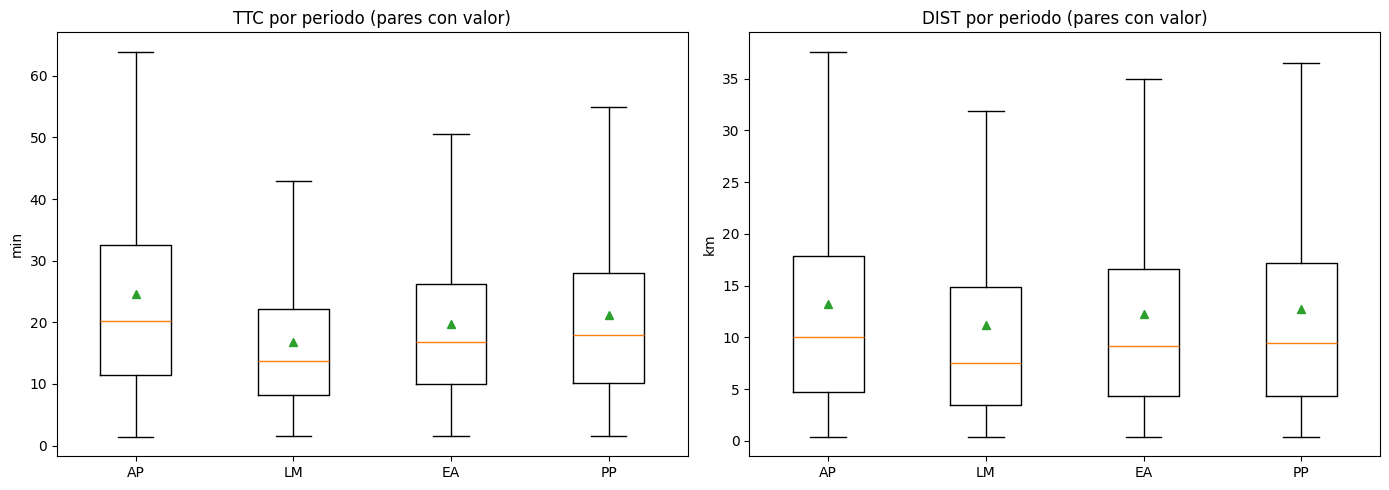

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, tipo, unidad in zip(axes, TIPOS, ["min", "km"]):
    datos = [skims_od[p].loc[skims_od[p][f"con_valor_{tipo}"], tipo] for p in PERIODOS]
    ax.boxplot(datos, tick_labels=PERIODOS, showfliers=False, showmeans=True)
    ax.set_title(f"{tipo} por periodo (pares con valor)")
    ax.set_ylabel(unidad)
plt.tight_layout()
plt.show()

TTC: AP está más arriba y LM más abajo, igual que en la base anterior.

DIST: las cajas ya no son idénticas porque cada periodo tiene pares distintos (solo los que tienen demanda).

## 7. Pares llamativos

In [19]:
filas_umbral = []
for tipo in TIPOS:
    for p in PERIODOS:
        v = skims_od[p].loc[skims_od[p][f"con_valor_{tipo}"], tipo]

        p25 = v.quantile(0.25)
        p75 = v.quantile(0.75)
        limite_tukey = p75 + 1.5 * (p75 - p25)

        filas_umbral.append({
            "Matriz": f"{tipo}_{p}",
            "Umbral fijo": UMBRALES[tipo],
            "> umbral fijo": (v > UMBRALES[tipo]).sum(),
            "Límite Tukey": round(limite_tukey, 2),
            "> Tukey": (v > limite_tukey).sum(),
            "% > Tukey": round((v > limite_tukey).mean() * 100, 2),
            "P99": round(v.quantile(0.99), 2),
        })

pares_umbral = pd.DataFrame(filas_umbral)
pares_umbral

,Matriz,Umbral fijo,> umbral fijo,Límite Tukey,> Tukey,% > Tukey,P99
0,TTC_AP,75,118,63.95,223,2.65,82.40
1,TTC_LM,75,9,43.17,134,3.18,55.97
2,TTC_EA,75,22,50.53,299,2.44,59.35
3,TTC_PP,75,38,54.89,171,3.02,70.33
4,DIST_AP,60,72,37.61,376,4.47,57.95
5,DIST_LM,60,26,31.95,229,5.44,53.03
6,DIST_EA,60,54,34.96,551,4.49,51.13
7,DIST_PP,60,36,36.51,267,4.71,55.04


In [20]:
# Velocidad de los pares con valor en TTC y DIST (sin filtrar pares imposibles)
vel_con_valor = {p: skims_od[p].loc[skims_od[p]["con_valor_TTC"] & skims_od[p]["con_valor_DIST"], "VEL_kmh"]
                 for p in PERIODOS}

filas_vel = []
for p, vel in vel_con_valor.items():
    p25 = vel.quantile(0.25)
    p75 = vel.quantile(0.75)
    tukey_inf = p25 - 1.5 * (p75 - p25)
    tukey_sup = p75 + 1.5 * (p75 - p25)

    filas_vel.append({
        "Periodo": p,
        "Vel. mediana (km/h)": round(vel.median(), 1),
        "Tukey inferior": round(tukey_inf, 1),
        "Tukey superior": round(tukey_sup, 1),
        "< Tukey inf": (vel < tukey_inf).sum(),
        "> Tukey sup": (vel > tukey_sup).sum(),
        f"< {VEL_MIN} km/h": (vel < VEL_MIN).sum(),
        f"> {VEL_TOPE} km/h": (vel > VEL_TOPE).sum(),
    })

velocidades = pd.DataFrame(filas_vel)
velocidades

,Periodo,Vel. mediana (km/h),Tukey inferior,Tukey superior,< Tukey inf,> Tukey sup,< 5 km/h,> 110 km/h
0,AP,28.4,2.9,54.7,0,209,0,0
1,LM,32.8,-3.0,68.4,0,49,0,0
2,EA,32.1,3.3,60.8,0,218,0,0
3,PP,31.1,1.8,60.6,0,86,0,0


In [21]:
rangos_vel = pd.DataFrame({
    p: pd.cut(vel, bins=BINS_VEL, labels=LABELS_VEL, right=False).value_counts(sort=False)
    for p, vel in vel_con_valor.items()
})
rangos_vel_pct = (rangos_vel / rangos_vel.sum() * 100).round(2)

print("Número de pares por rango de velocidad")
display(rangos_vel)
print("% de pares por rango de velocidad")
display(rangos_vel_pct)

Número de pares por rango de velocidad


,AP,LM,EA,PP
VEL_kmh,,,,
<5 caminar,0,0,0,0
5-20 congestión,1406,692,1615,838
20-40 urbano,5792,2275,7781,3584
40-60 avenida,1105,1054,2609,1145
60-80 Periférico,95,183,246,93
80-110 carretera,7,5,13,3
110-120 límite autopista,0,0,0,0
>120,0,0,0,0


% de pares por rango de velocidad


,AP,LM,EA,PP
VEL_kmh,,,,
<5 caminar,0.00,0.00,0.00,0.00
5-20 congestión,16.73,16.44,13.17,14.80
20-40 urbano,68.91,54.05,63.45,63.29
40-60 avenida,13.15,25.04,21.27,20.22
60-80 Periférico,1.13,4.35,2.01,1.64
80-110 carretera,0.08,0.12,0.11,0.05
110-120 límite autopista,0.00,0.00,0.00,0.00
>120,0.00,0.00,0.00,0.00


- La mayoría de los pares está entre 20 y 40 km/h: 68.9 % en AP, 54.1 % en LM, 63.5 % en EA y 63.3 % en PP.
- AP sigue siendo el periodo más lento y LM el más fluido (25.0 % entre 40 y 60 km/h, contra 13.2 % en AP).
- Ahora hay muchos más pares de 5 a 20 km/h: de 13 a 17 % (692 en LM a 1,615 en EA). Son pares cortos dentro de la ciudad.
- No hay pares de menos de 5 km/h ni de más de 110 km/h; solo 3 a 13 pares por periodo pasan de 80 km/h.

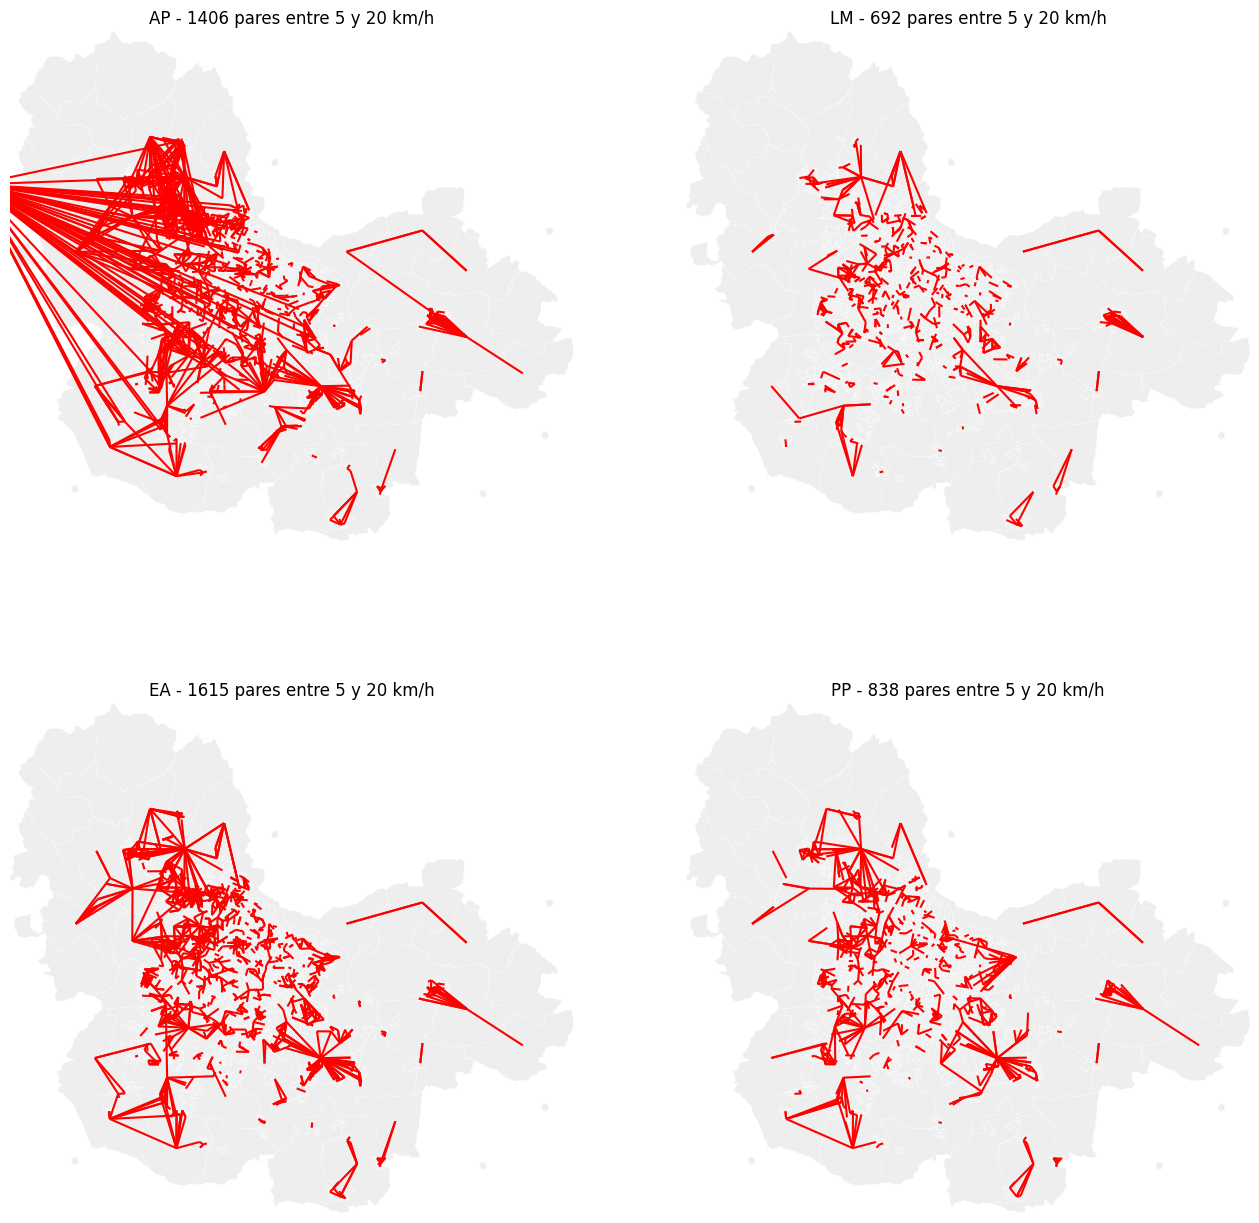

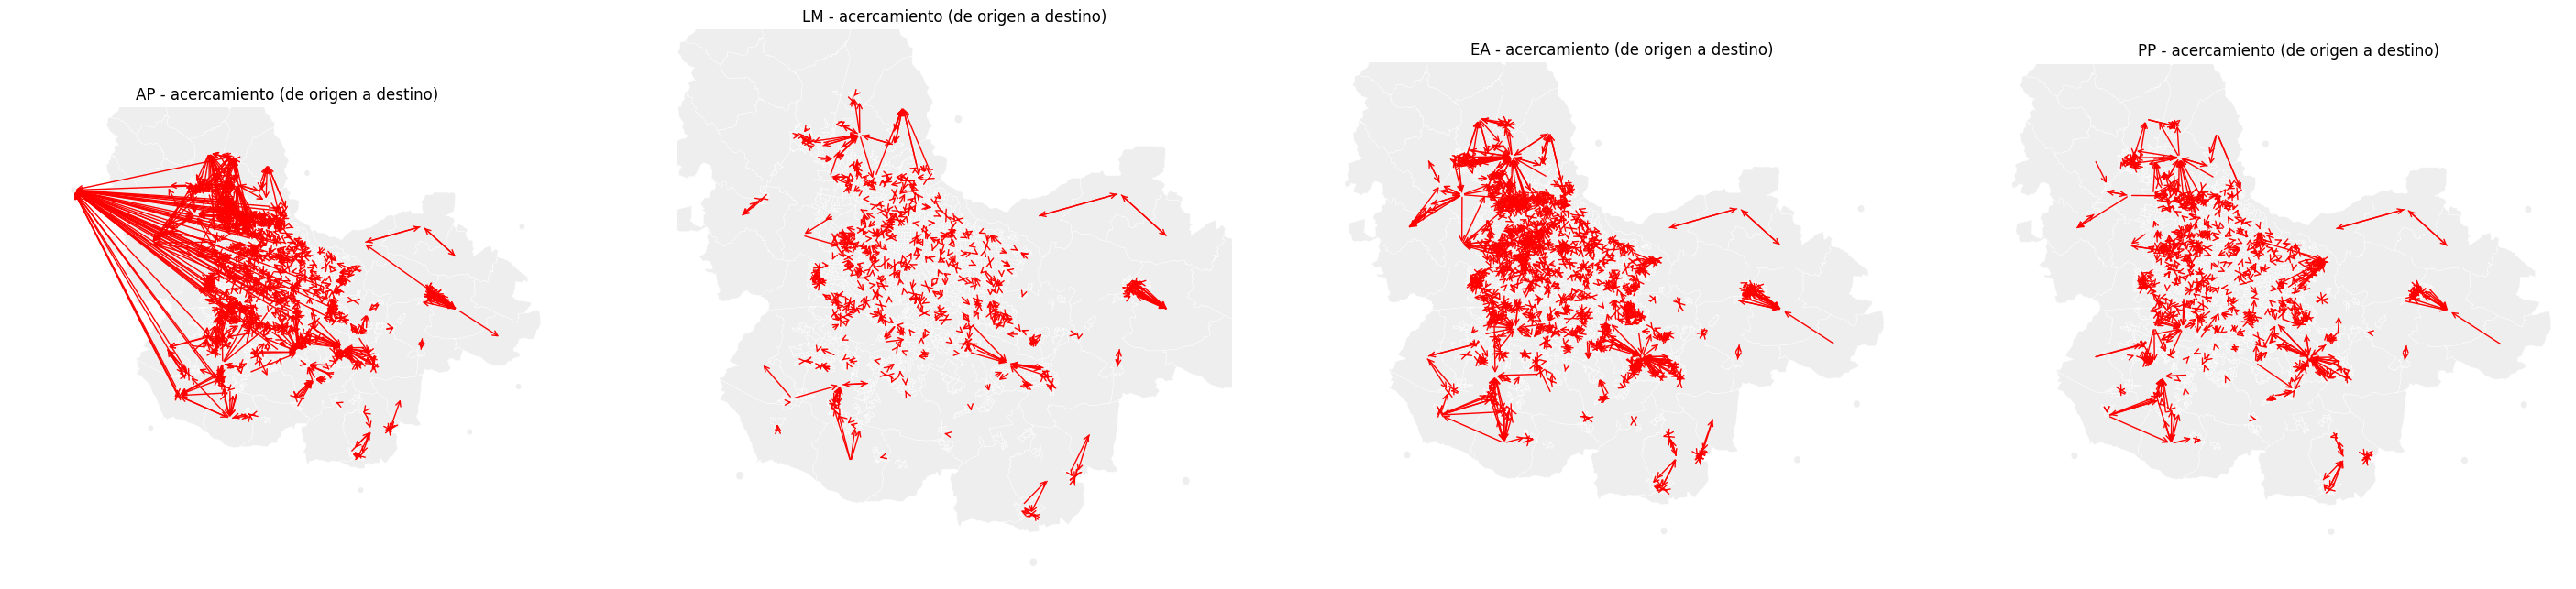

In [22]:
lentos = pd.concat([
    skims_od[p].loc[skims_od[p]["valido"] & skims_od[p]["VEL_kmh"].between(VEL_MIN, VEL_LENTO, inclusive="left")].assign(Periodo=p)
    for p in PERIODOS
])
lentos["Zona_origen"] = [zonas[f] for f in lentos["Origin"]]
lentos["Zona_destino"] = [zonas[f] for f in lentos["Destination"]]
lentos = lentos[["Periodo", "Zona_origen", "Zona_destino", "TTC", "DIST", "VEL_kmh"]].round(2)


def lineas_lentas(p):
    return lineas_de(lentos[lentos["Periodo"] == p], "Zona_origen", "Zona_destino")


# Mapas 1 a 4: toda la ciudad, los 4 periodos
fig, axes = plt.subplots(2, 2, figsize=(16, 16))
for ax, p in zip(axes.flat, PERIODOS):
    lineas = lineas_lentas(p)
    zonas_geo.plot(ax=ax, color="#eeeeee", edgecolor="white", linewidth=0.2)
    if len(lineas) > 0:
        lineas.plot(ax=ax, color="red", linewidth=1.5)
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_title(f"{p} - {len(lineas)} pares entre {VEL_MIN} y {VEL_LENTO} km/h")
    ax.set_axis_off()
plt.show()

# Mapas 5 y 6: acercamiento con flechas de origen a destino
con_pares = [p for p in PERIODOS if (lentos["Periodo"] == p).any()]
fig, axes = plt.subplots(1, len(con_pares), figsize=(9 * len(con_pares), 9))
axes = np.atleast_1d(axes)
for ax, p in zip(axes, con_pares):
    l = lentos[lentos["Periodo"] == p]
    zonas_geo.plot(ax=ax, color="#eeeeee", edgecolor="white", linewidth=0.3)

    x0, y0, x1, y1 = lineas_lentas(p).total_bounds
    margen_x, margen_y = (x1 - x0) * 0.15, (y1 - y0) * 0.15
    ax.set_xlim(x0 - margen_x, x1 + margen_x)
    ax.set_ylim(y0 - margen_y, y1 + margen_y)

    for o, d in zip(l["Zona_origen"], l["Zona_destino"]):
        ax.annotate("", xy=(centros[d].x, centros[d].y), xytext=(centros[o].x, centros[o].y),
                    arrowprops=dict(arrowstyle="->", color="red", lw=1))

    ax.set_title(f"{p} - acercamiento (de origen a destino)")
    ax.set_axis_off()
plt.show()

### Pares entre 5 y 20 km/h

- Los 4 periodos tienen pares en este rango (de 692 en LM a 1,615 en EA).
- Están más repartidos por la ciudad que en la base anterior, aunque se repiten algunas zonas como 3903 (El Salto) y 8909 (Zapopan).

AP: top 5 orígenes


,Pares lentos,Municipio
Zona_origen,,
8909,21,Zapopan
8905,15,Zapopan
9904,11,Zapotlanejo
5909,10,Tlajomulco de Zúñiga
5374,9,Tlajomulco de Zúñiga


AP: top 5 destinos


,Pares lentos,Municipio
Zona_destino,,
10001,49,Acceso_Vallarta
3903,29,El Salto
10009,22,Tlajomulco de Zúñiga
8027,17,Zapopan
8916,15,Zapopan


LM: top 5 orígenes


,Pares lentos,Municipio
Zona_origen,,
8909,8,Zapopan
9904,7,Zapotlanejo
2,6,Guadalajara
64,6,Guadalajara
8038,6,Zapopan


... (6 outputs left out)

PP: top 5 orígenes


,Pares lentos,Municipio
Zona_origen,,
3903,17,El Salto
8038,10,Zapopan
8372,9,Zapopan
8909,9,Zapopan
9031,7,Zapotlanejo


PP: top 5 destinos


,Pares lentos,Municipio
Zona_destino,,
3903,11,El Salto
8909,10,Zapopan
5374,7,Tlajomulco de Zúñiga
6900,7,San Pedro Tlaquepaque
5909,6,Tlajomulco de Zúñiga


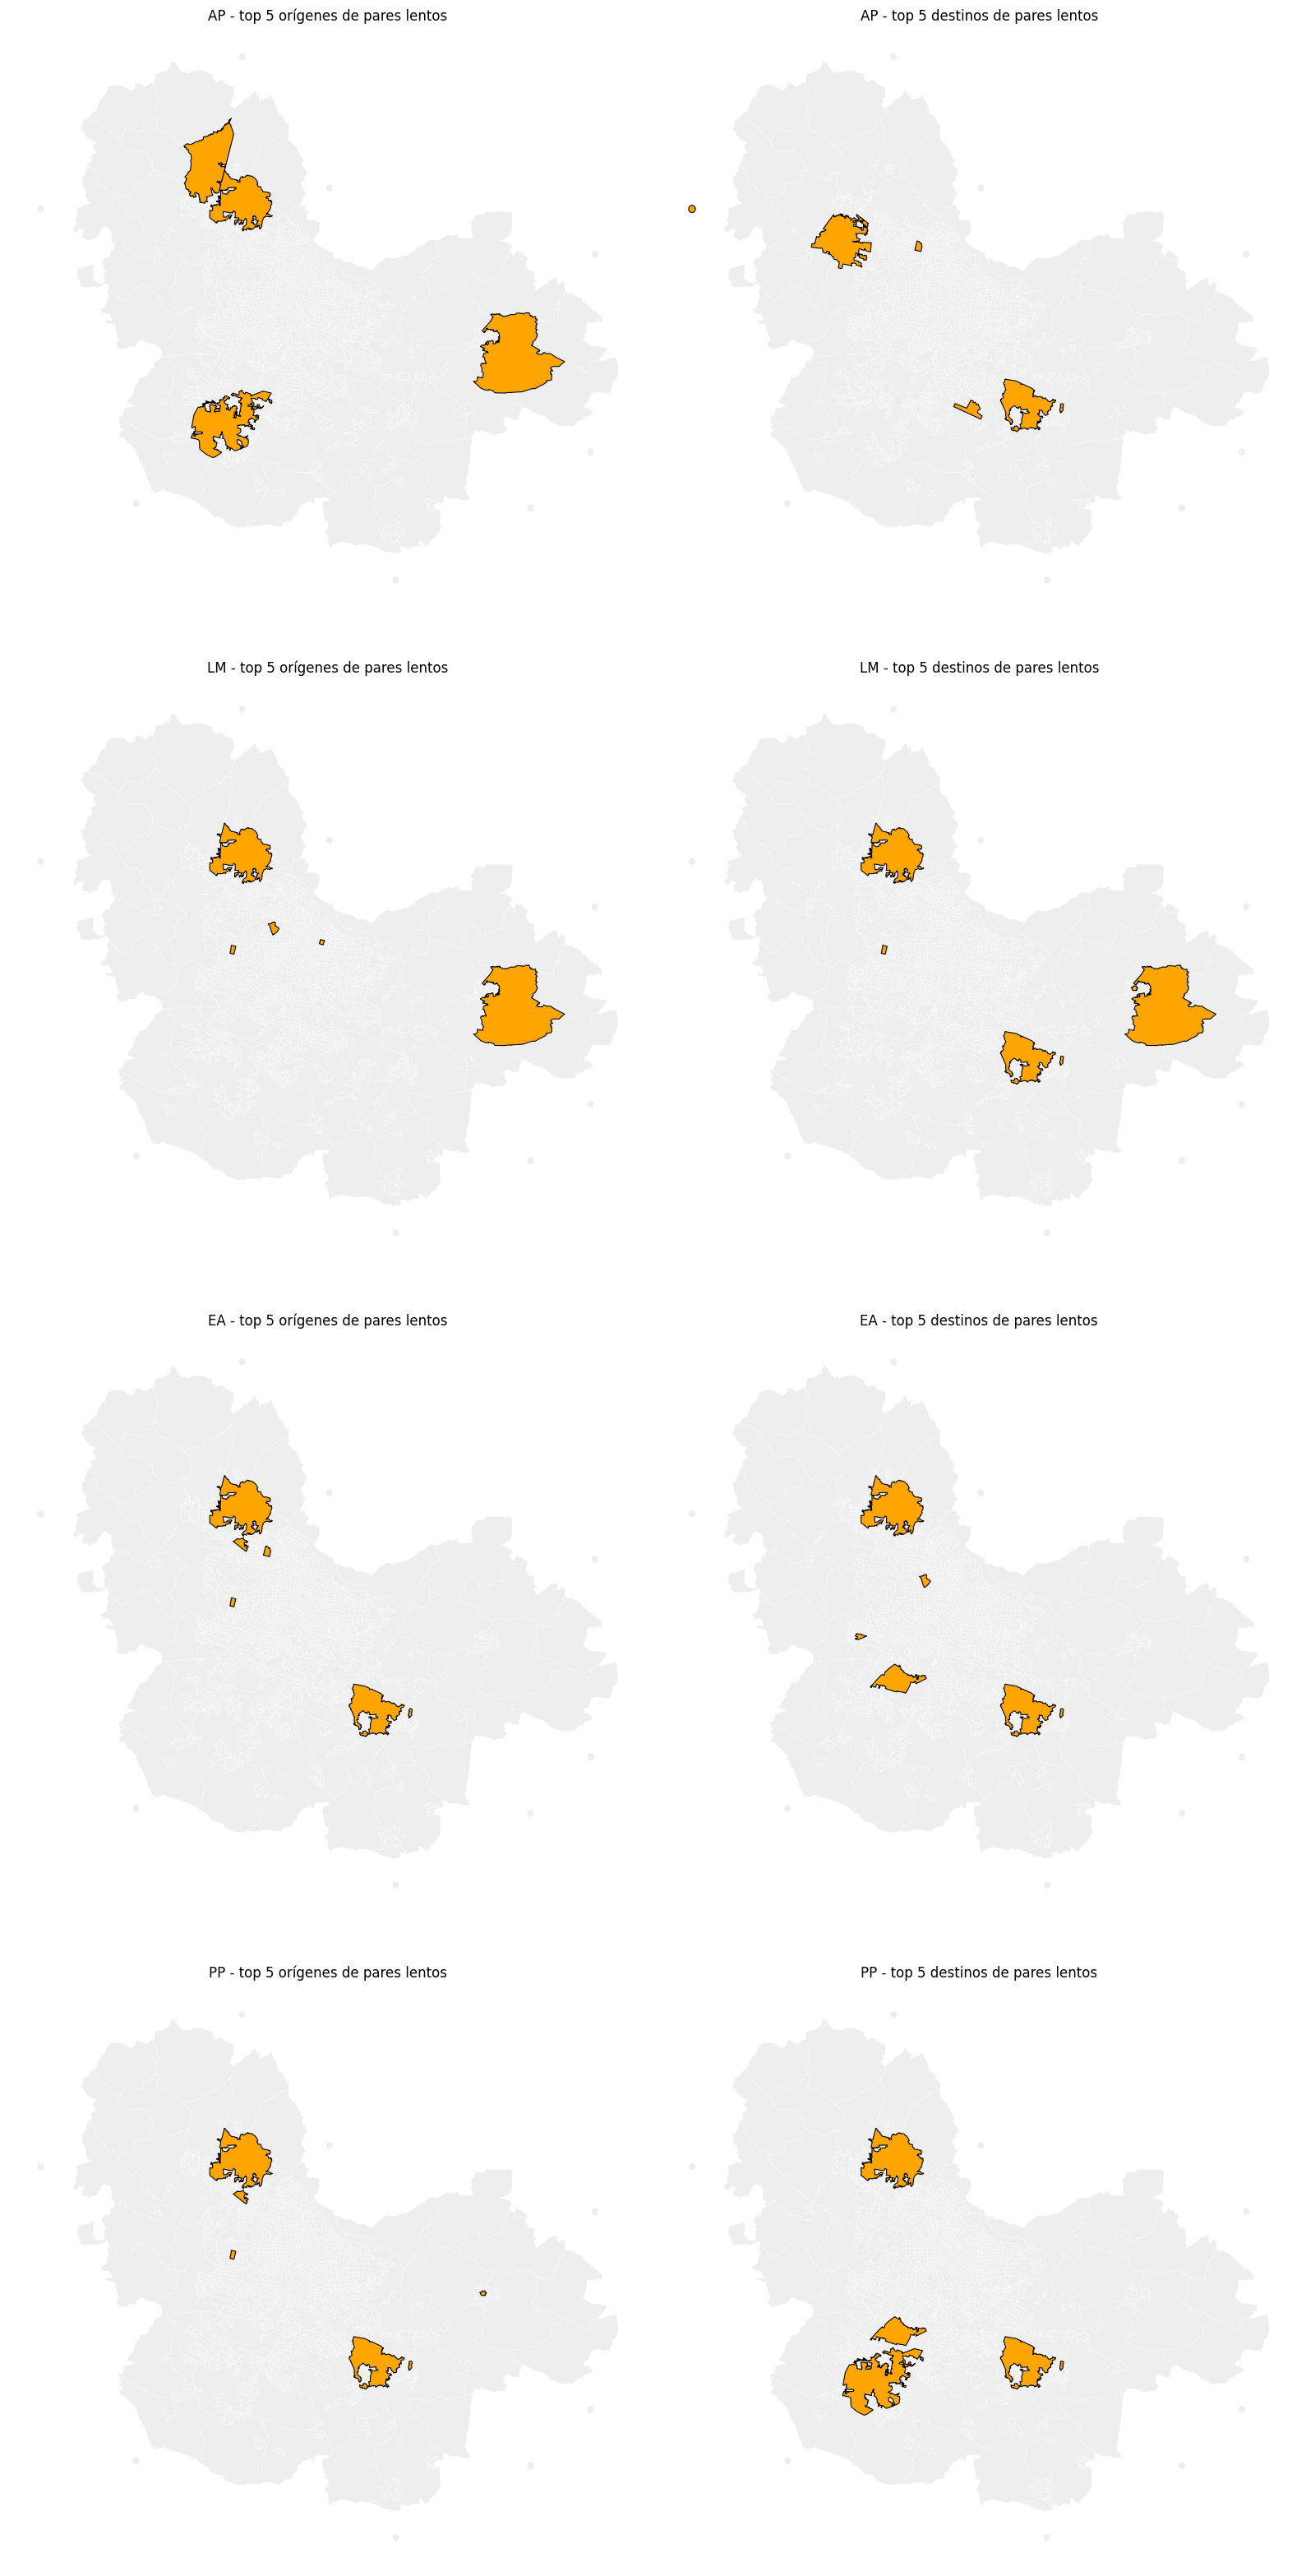

In [23]:
fig, axes = plt.subplots(len(con_pares), 2, figsize=(16, 8 * len(con_pares)))
axes = np.atleast_2d(axes)

for fila, p in enumerate(con_pares):
    l = lentos[lentos["Periodo"] == p]
    for col, (columna, nombre) in enumerate([("Zona_origen", "orígenes"), ("Zona_destino", "destinos")]):
        conteo = l[columna].astype(int).value_counts().head(5)
        zonas_top = zonas_geo[zonas_geo["id_visum"].isin(conteo.index)]

        ax = axes[fila, col]
        zonas_geo.plot(ax=ax, color="#eeeeee", edgecolor="white", linewidth=0.2)
        zonas_top.plot(ax=ax, color="orange", edgecolor="black", linewidth=0.8)
        ax.set_title(f"{p} - top 5 {nombre} de pares lentos")
        ax.set_axis_off()

        tabla = conteo.rename("Pares lentos").to_frame()
        tabla["Municipio"] = municipio.reindex(tabla.index).values
        print(f"{p}: top 5 {nombre}")
        display(tabla)

plt.tight_layout()
plt.show()

- En AP el destino más repetido es el acceso Vallarta (10001, 49 pares), seguido de 3903 (El Salto) y del acceso 10009 de Tlajomulco.
- En LM, EA y PP las zonas 3903 (El Salto), 8909 y 8038 (Zapopan) y 9904 (Zapotlanejo) aparecen como origen y como destino.
- La zona 3903 sale en los 4 periodos; vale la pena revisar sus conectores.

### Pares con mayor TTC y DIST

In [24]:
for tipo in TIPOS:
    for p in PERIODOS:
        od = skims_od[p]
        print(f"{tipo}_{p}")
        display(od.loc[od[f"con_valor_{tipo}"]].nlargest(10, tipo)[["Origin", "Destination", tipo]])

TTC_AP


,Origin,Destination,TTC
4414169,2089,2096,222.642099
4413093,1013,2096,205.706287
4412725,645,2096,203.703387
4412723,643,2096,203.677453
4412577,497,2096,200.582925
4412647,567,2096,195.435916
4412917,837,2096,194.836649
4412870,790,2096,194.375204
4412918,838,2096,194.247721
4413289,1209,2096,193.708689


TTC_LM


,Origin,Destination,TTC
4414168,2088,2096,109.982295
3940543,2088,1871,94.225007
4399432,2087,2089,84.976352
4231045,2100,2009,79.578867
4424694,2089,2101,78.327643
4397327,2087,2088,77.996776
4422460,1960,2100,77.602566
4395223,2088,2087,77.255646
4395350,110,2088,77.117652
4397334,2094,2088,74.089177


TTC_EA


,Origin,Destination,TTC
4399441,2096,2089,97.438540
4422536,2036,2100,93.926832
4414169,2089,2096,91.790592
1014476,1971,481,88.169613
4395224,2089,2087,86.170663
4399432,2087,2089,84.967654
4127900,2100,1960,84.745995
4245779,2099,2016,84.568370
4120499,1014,1957,83.616206
4420398,2003,2099,83.170384


... (6 outputs left out)

DIST_EA


,Origin,Destination,DIST
4414169,2089,2096,95.004527
4399441,2096,2089,94.305936
4419233,838,2099,93.686558
4418389,2099,2098,90.588288
4245779,2099,2016,84.865743
4420398,2003,2099,82.721785
4420397,2002,2099,81.707785
4216309,2099,2002,79.464258
2132360,2100,1012,77.813137
4218414,2099,2003,77.799342


DIST_PP


,Origin,Destination,DIST
4397341,2101,2088,97.788398
4399446,2101,2089,94.642232
3877405,2100,1841,86.065402
4127900,2100,1960,79.600683
4127899,2099,1960,77.222073
679910,2100,322,76.675268
1046181,2101,496,76.471323
4397111,1871,2088,76.413729
4287880,2100,2036,75.492770
4092114,2099,1943,72.657439


## 8. Histogramas por pares
Bins de 5 min y 5 km.

In [25]:
def graficar(tablas, columna, etiqueta_y, titulo):
    """tablas: {versión: {"TTC_AP": tabla, ...}}. Con más de una versión, las barras se dibujan lado a lado."""
    n = len(tablas)
    ancho = 0.8 / n
    for p in PERIODOS:
        for tipo in TIPOS:
            fig, ax = plt.subplots(figsize=(14, 4))
            for k, (version, por_matriz) in enumerate(tablas.items()):
                t = por_matriz[f"{tipo}_{p}"]
                x = np.arange(len(t)) + (k - (n - 1) / 2) * ancho
                barras = ax.bar(x, t[columna], width=ancho, label=version)
                ax.bar_label(barras, fmt="%.1f", fontsize=7 if n == 1 else 5, rotation=0 if n == 1 else 90)
            ax.set_xticks(np.arange(len(t)), t.index.astype(str))
            ax.set_title(f"{tipo} {p} - {titulo}")
            ax.set_xlabel(f"Intervalo ({BINS_HIST[tipo][2]})")
            ax.set_ylabel(etiqueta_y)
            ax.tick_params(axis="x", rotation=90, labelsize=8)
            if n > 1:
                ax.legend()
            plt.tight_layout()
            plt.show()

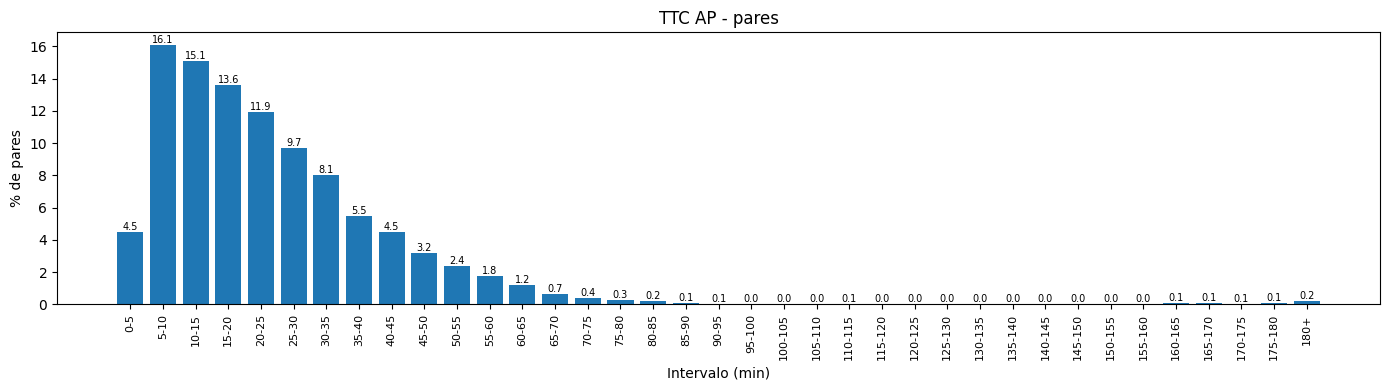

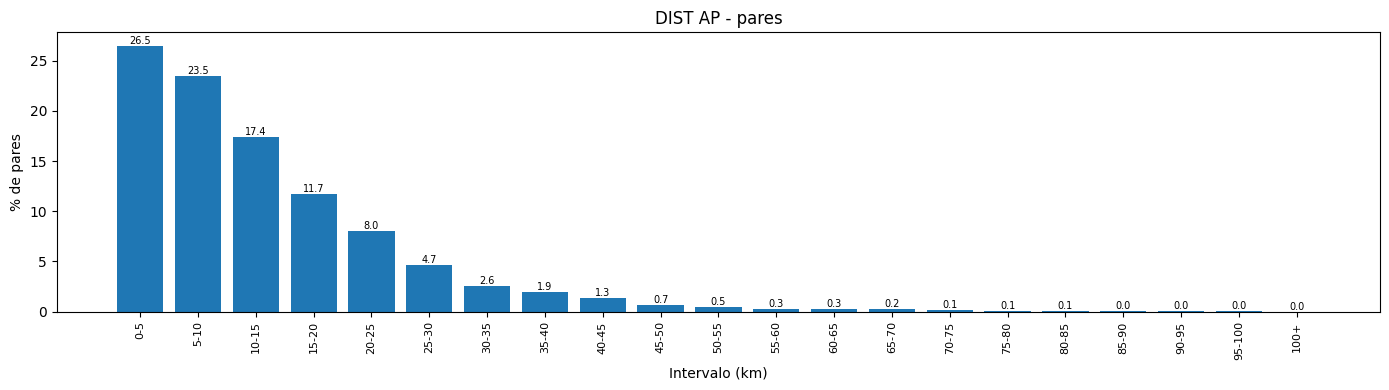

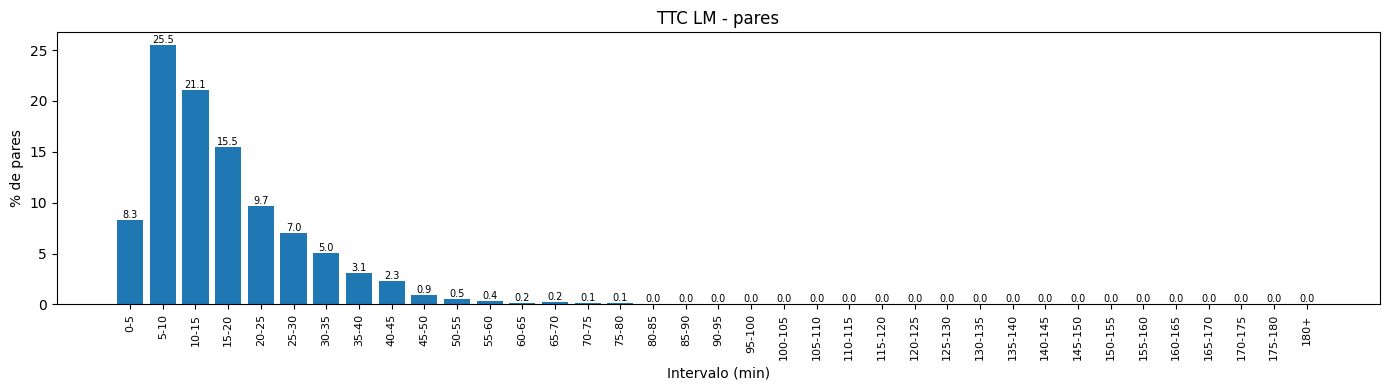

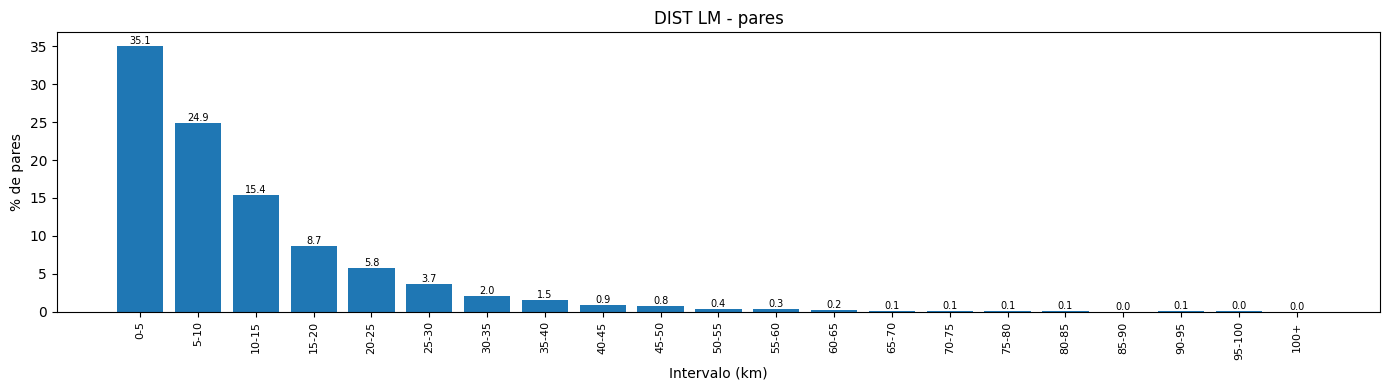

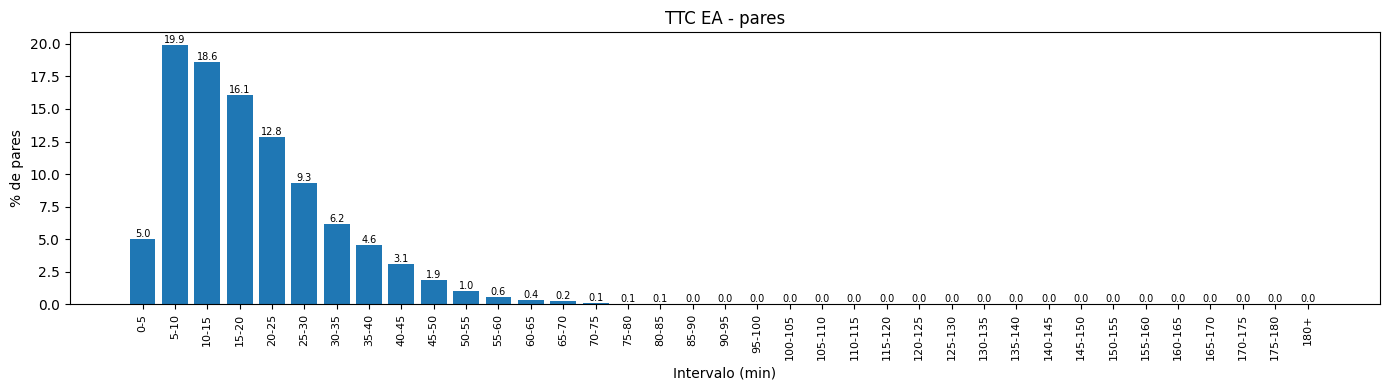

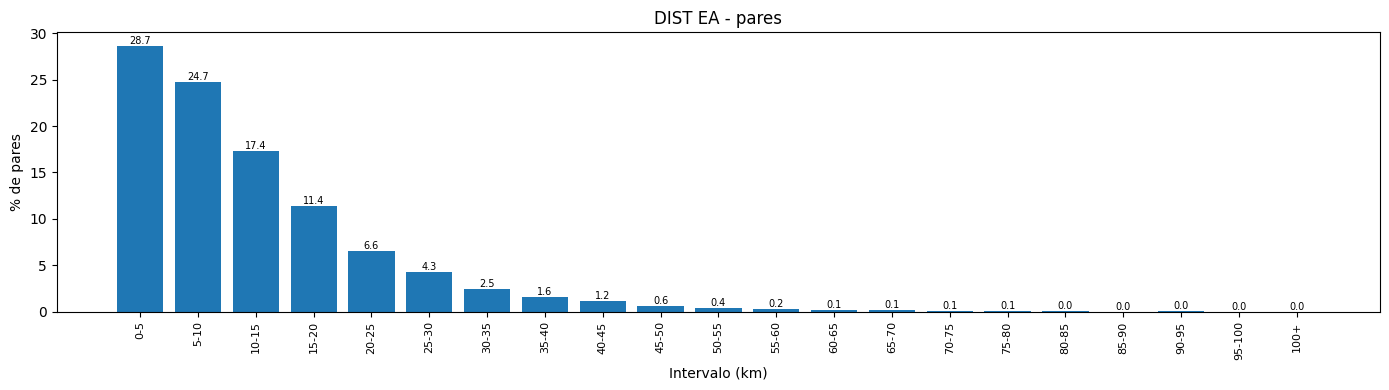

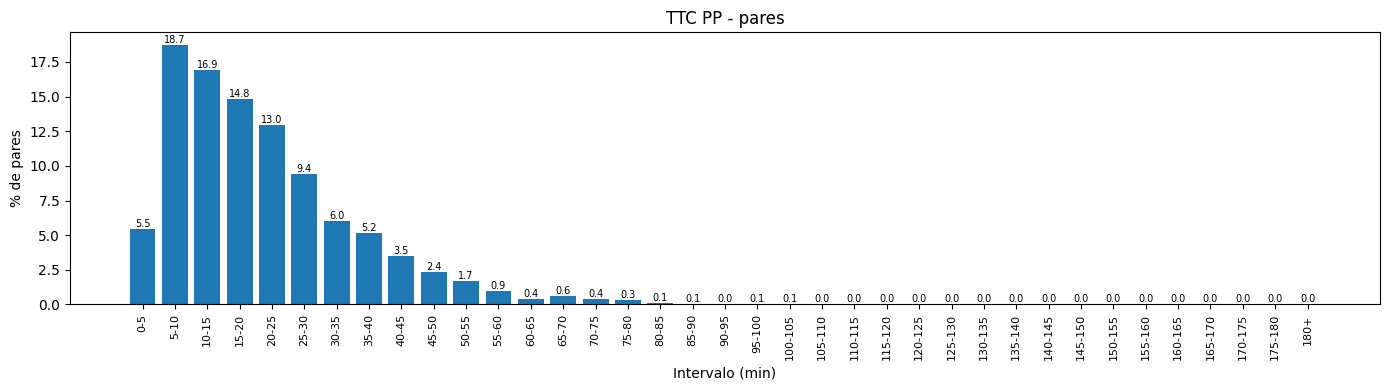

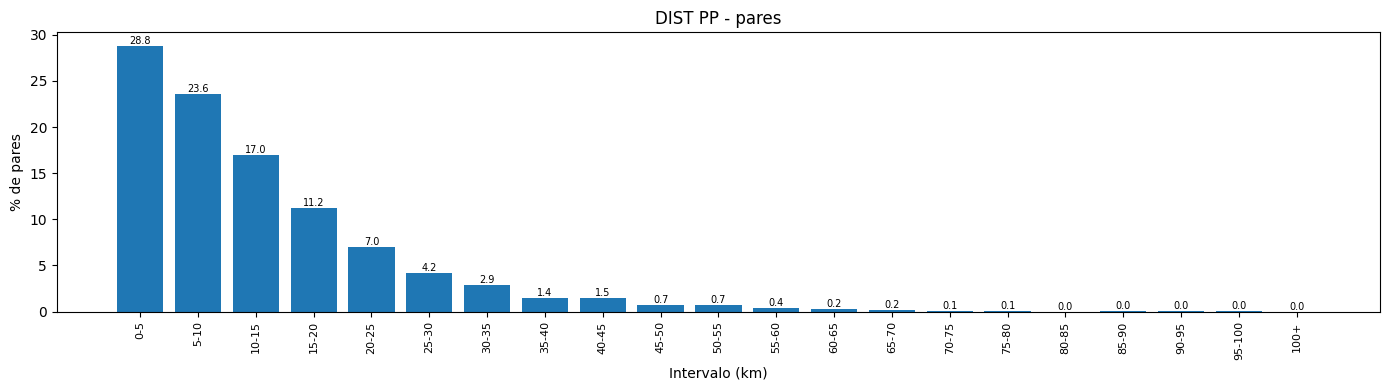

In [26]:
hist_pares = {}
for p in PERIODOS:
    for tipo in TIPOS:
        bins, labels, _ = BINS_HIST[tipo]
        od = skims_od[p]
        intervalos = pd.cut(od.loc[od[f"con_valor_{tipo}"], tipo], bins=bins, labels=labels, right=False)
        t = intervalos.value_counts(sort=False).rename("Pares").to_frame()
        t["% pares"] = (t["Pares"] / t["Pares"].sum() * 100).round(2)
        hist_pares[f"{tipo}_{p}"] = t

graficar({"Pares con valor": hist_pares}, "% pares", "% de pares", "pares")

**Tiempo (TTC)**
- En los 4 periodos el intervalo más frecuente es de 5 a 10 min (16.1 % en AP, 25.5 % en LM, 19.9 % en EA y 18.7 % en PP).
- Tardan menos de 30 min 70.9 % de los pares en AP, 87.0 % en LM, 81.7 % en EA y 78.3 % en PP.
- Los pares de más de 60 min son 3.7 % en AP, 2.0 % en PP, 1.0 % en EA y 0.7 % en LM.

**Distancia (DIST)**
- El intervalo más frecuente es de 0 a 5 km (de 26.5 % en AP a 35.1 % en LM).
- Solo de 1.1 a 1.7 % de los pares está a más de 50 km.
- Los pares son más cortos que en la base anterior porque ahora solo hay pares con demanda, y la demanda se concentra en viajes cortos.

## Demanda por periodo y tipo de vehículo

In [27]:
def cargar_demanda(path):
    d = pd.read_csv(path)
    d = d.groupby(["Origen_ageb", "Destino_ageb"], as_index=False)["Ponderador_x_PF"].sum()
    d.columns = ["Origin_zona", "Destination_zona", "Trips"]
    return d


demanda_modo = {(p, modo): cargar_demanda(os.path.join(DEMANDA, f"matriz_{modo}_{p}.csv"))
                for p in PERIODOS for modo in MODOS}
viajes_modo = pd.DataFrame([
    {"Periodo": p, "Modo": modo, "Pares": len(d), "Viajes": round(d["Trips"].sum(), 1)}
    for (p, modo), d in demanda_modo.items()
])
viajes_modo

,Periodo,Modo,Pares,Viajes
0,AP,VP,8733,364851.0
1,AP,HEAVY_FREIGHT,261,555.1
2,AP,LIGHT_FREIGHT,329,715.3
3,LM,VP,4395,173472.0
4,LM,HEAVY_FREIGHT,577,1365.2
5,LM,LIGHT_FREIGHT,744,1671.5
6,EA,VP,12573,297556.0
7,EA,HEAVY_FREIGHT,887,1332.7
8,EA,LIGHT_FREIGHT,1147,1551.9
9,PP,VP,5922,298480.0


In [28]:
totales = viajes_modo.pivot(index="Periodo", columns="Modo", values="Viajes")
totales = totales.loc[PERIODOS, MODOS]
totales["Total"] = totales.sum(axis=1)
totales.loc["Total"] = totales.sum()
totales.round(1)

Modo,VP,HEAVY_FREIGHT,LIGHT_FREIGHT,Total
Periodo,,,,
AP,364851.0,555.1,715.3,366121.4
LM,173472.0,1365.2,1671.5,176508.7
EA,297556.0,1332.7,1551.9,300440.6
PP,298480.0,717.3,829.9,300027.2
Total,1134359.0,3970.3,4768.6,1143097.9


Total de viajes en la base, no de todo el día porque faltan dos horarios

### Cruce demanda y skims
Se suman los viajes de los tres tipos por par de zonas y se pegan TTC y DIST de la skim.

In [29]:
cruces_todos = {}
cruces = {}
cruces_validos = {}
filas_cruce = []
for p in PERIODOS:
    d = pd.concat([demanda_modo[(p, m)].assign(Modo=m) for m in MODOS])
    d = d.pivot_table(index=["Origin_zona", "Destination_zona"], columns="Modo", values="Trips",
                      aggfunc="sum", fill_value=0)
    d = d.reindex(columns=MODOS, fill_value=0).reset_index().rename_axis(columns=None)
    d["Trips"] = d[MODOS].sum(axis=1)
    d["Origin"] = d["Origin_zona"].map(posicion)
    d["Destination"] = d["Destination_zona"].map(posicion)
    sin_mapeo = d["Origin"].isna() | d["Destination"].isna()
    d = d[~sin_mapeo].astype({"Origin": "int32", "Destination": "int32"})

    c = d.merge(skims_od[p][["Origin", "Destination", "TTC", "DIST"]], on=["Origin", "Destination"],
                how="left", indicator=True)
    sin_par_skim = (c["_merge"] == "left_only").sum()
    c = clasificar_pares(c.drop(columns="_merge"), p)

    cruces_todos[p] = c
    cruces[p] = c[c["revisado"]]
    cruces_validos[p] = c[c["valido"]]

    filas_cruce.append({
        "Periodo": p,
        "Pares con viajes": len(c),
        "Pares sin mapeo": sin_mapeo.sum(),
        "Pares sin par en la skim": sin_par_skim,
        "Viajes": round(c["Trips"].sum(), 1),
        "Viajes intrazonales": round(c.loc[c["diagonal"], "Trips"].sum(), 1),
        "Viajes sin ruta": round(c.loc[c["sin_ruta"], "Trips"].sum(), 1),
        "Viajes en pares imposibles": round(c.loc[c["imposible"], "Trips"].sum(), 1),
        "Viajes en pares válidos": round(c.loc[c["valido"], "Trips"].sum(), 1),
    })

versiones_cruce = {"Todos": cruces, "Sin imposibles": cruces_validos}
cruce_resumen = pd.DataFrame(filas_cruce)
cruce_resumen

,Periodo,Pares con viajes,Pares sin mapeo,Pares sin par en la skim,Viajes,Viajes intrazonales,Viajes sin ruta,Viajes en pares imposibles,Viajes en pares válidos
0,AP,9241,0,0,366121.4,19168.5,1116.2,0.0,345836.7
1,LM,5521,0,0,176508.7,10647.3,2668.7,0.0,163192.7
2,EA,14239,0,0,300440.6,12472.6,2437.5,0.0,285530.6
3,PP,6492,0,0,300027.1,18003.6,1340.8,0.0,280682.8


## Estadísticas de pares y viajes imposibles

In [30]:
filas_imp = []
for p in PERIODOS:
    od, c = skims_od[p], cruces_todos[p]
    imp_c = c[c["imposible"]]
    fila = {"Periodo": p, "Pares revisados": od["revisado"].sum()}
    for regla in REGLAS_IMPOSIBLE:
        fila[f"Pares {regla}"] = od[regla].sum()
    fila.update({
        "Pares imposibles": od["imposible"].sum(),
        "% de pares revisados": round(od["imposible"].sum() / od["revisado"].sum() * 100, 3),
        "Pares imposibles con viajes": len(imp_c),
        "Viajes afectados": round(imp_c["Trips"].sum(), 1),
        "Viajes totales": round(c["Trips"].sum(), 1),
        "% de viajes": round(imp_c["Trips"].sum() / c["Trips"].sum() * 100, 2),
    })
    for regla in REGLAS_IMPOSIBLE:
        fila[f"Viajes {regla}"] = round(c.loc[c[regla], "Trips"].sum(), 1)
    filas_imp.append(fila)

imp_resumen_periodo = pd.DataFrame(filas_imp)
imp_resumen_periodo

,Periodo,Pares revisados,Pares ttc_cero,Pares ttc_minimo,Pares vel_baja,Pares vel_alta,Pares ruta_corta,Pares imposibles,% de pares revisados,Pares imposibles con viajes,Viajes afectados,Viajes totales,% de viajes,Viajes ttc_cero,Viajes ttc_minimo,Viajes vel_baja,Viajes vel_alta,Viajes ruta_corta
0,AP,8405,0,0,0,0,0,0,0.0,0,0.0,366121.4,0.0,0.0,0.0,0.0,0.0,0.0
1,LM,4209,0,0,0,0,0,0,0.0,0,0.0,176508.7,0.0,0.0,0.0,0.0,0.0,0.0
2,EA,12264,0,0,0,0,0,0,0.0,0,0.0,300440.6,0.0,0.0,0.0,0.0,0.0,0.0
3,PP,5663,0,0,0,0,0,0,0.0,0,0.0,300027.1,0.0,0.0,0.0,0.0,0.0,0.0


In [31]:
filas_tipo = []
for p in PERIODOS:
    c = cruces_todos[p]
    for modo in MODOS:
        filas_tipo.append({
            "Periodo": p,
            "Tipo": NOMBRES_MODO[modo],
            "Viajes": c[modo].sum(),
            "Viajes afectados": c.loc[c["imposible"], modo].sum(),
        })

imp_resumen_tipo = pd.DataFrame(filas_tipo)
imp_resumen_tipo = pd.concat([
    imp_resumen_tipo,
    imp_resumen_tipo.groupby("Tipo", as_index=False, sort=False)[["Viajes", "Viajes afectados"]].sum().assign(Periodo="Total"),
], ignore_index=True)
imp_resumen_tipo["% afectados"] = (imp_resumen_tipo["Viajes afectados"] / imp_resumen_tipo["Viajes"] * 100).round(2)
imp_resumen_tipo[["Viajes", "Viajes afectados"]] = imp_resumen_tipo[["Viajes", "Viajes afectados"]].round(1)

imp_resumen_tipo.pivot(index="Periodo", columns="Tipo", values=["Viajes afectados", "% afectados"]) \
    .reindex(PERIODOS + ["Total"])

Viajes afectados                           % afectados               \
Tipo          Autos (VP) Carga ligera Carga pesada  Autos (VP) Carga ligera   
Periodo                                                                       
AP                   0.0          0.0          0.0         0.0          0.0   
LM                   0.0          0.0          0.0         0.0          0.0   
EA                   0.0          0.0          0.0         0.0          0.0   
PP                   0.0          0.0          0.0         0.0          0.0   
Total                0.0          0.0          0.0         0.0          0.0   

                      
Tipo    Carga pesada  
Periodo               
AP               0.0  
LM               0.0  
EA               0.0  
PP               0.0  
Total            0.0

### Viajes antes y después de quitar los tramos imposibles
Por tipo de vehículo y por municipio de origen. Se usan los viajes entre zonas distintas (sin intrazonales).

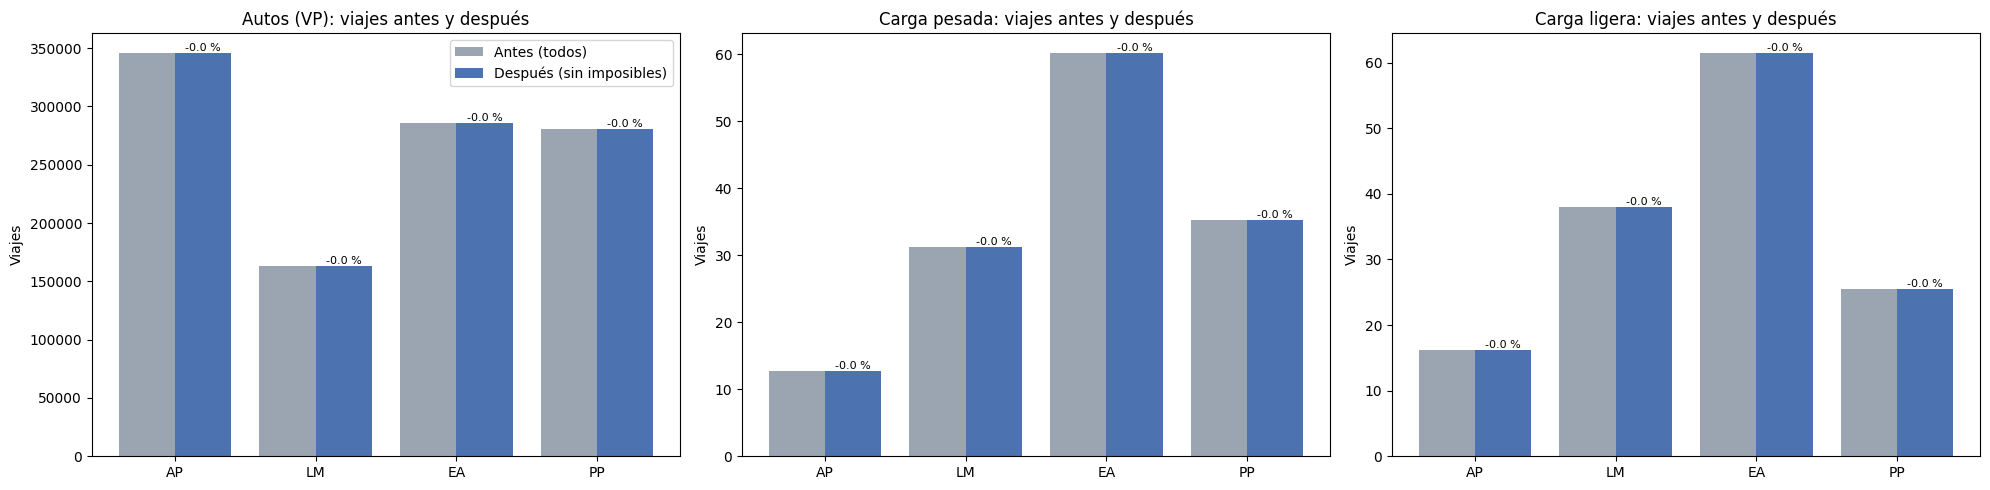

Antes                                 Después            \
Periodo             AP        LM        EA        PP        AP        LM   
Tipo                                                                       
Autos (VP)    345807.7  163123.5  285409.0  280622.0  345807.7  163123.5   
Carga ligera      16.2      38.0      61.5      25.5      16.2      38.0   
Carga pesada      12.7      31.3      60.2      35.3      12.7      31.3   

                                 % quitado                 
Periodo             EA        PP        AP   LM   EA   PP  
Tipo                                                       
Autos (VP)    285409.0  280622.0       0.0  0.0  0.0  0.0  
Carga ligera      61.5      25.5       0.0  0.0  0.0  0.0  
Carga pesada      60.2      35.3       0.0  0.0  0.0  0.0

In [32]:
antes_despues = pd.DataFrame([
    {"Periodo": p, "Tipo": NOMBRES_MODO[modo], "Antes": cruces[p][modo].sum(), "Después": cruces_validos[p][modo].sum()}
    for p in PERIODOS for modo in MODOS
])
antes_despues["Quitados"] = antes_despues["Antes"] - antes_despues["Después"]
antes_despues["% quitado"] = (antes_despues["Quitados"] / antes_despues["Antes"] * 100).round(1)

fig, axes = plt.subplots(1, len(MODOS), figsize=(20, 5))
for ax, tipo in zip(axes, NOMBRES_MODO.values()):
    t = antes_despues[antes_despues["Tipo"] == tipo].set_index("Periodo").reindex(PERIODOS)
    x = np.arange(len(PERIODOS))
    ax.bar(x - 0.2, t["Antes"], width=0.4, label="Antes (todos)", color="#9aa5b1")
    barras = ax.bar(x + 0.2, t["Después"], width=0.4, label="Después (sin imposibles)", color="#4c72b0")
    ax.bar_label(barras, labels=[f"-{v:.1f} %" for v in t["% quitado"]], fontsize=8)
    ax.set_xticks(x, PERIODOS)
    ax.set_title(f"{tipo}: viajes antes y después")
    ax.set_ylabel("Viajes")
axes[0].legend()
plt.tight_layout()
plt.show()

antes_despues.pivot(index="Tipo", columns="Periodo", values=["Antes", "Después", "% quitado"]) \
    .reindex(columns=PERIODOS, level=1).round(1)

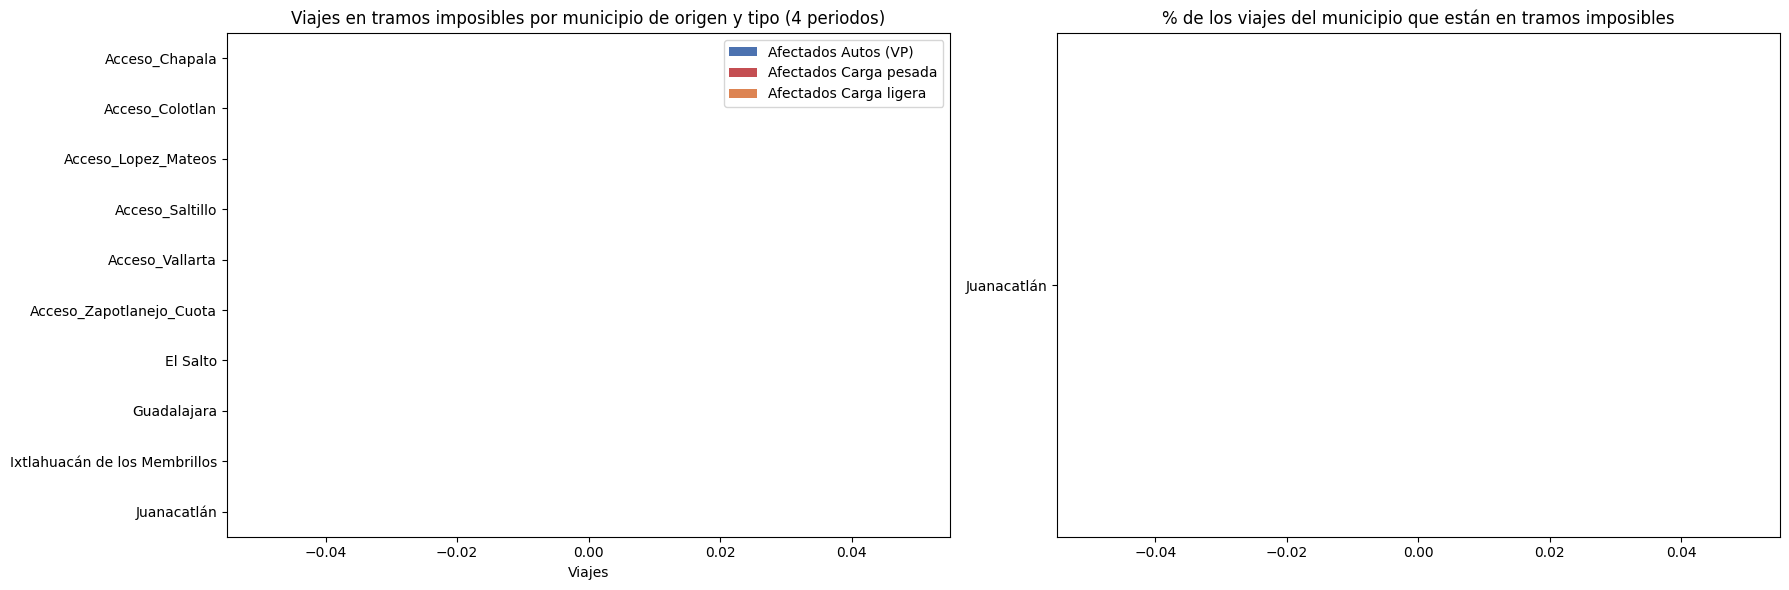

,Viajes del municipio,Viajes afectados,Afectados Autos (VP),Afectados Carga pesada,Afectados Carga ligera,% afectado,Zonas con tramos imposibles
Municipio,,,,,,,
Acceso_Chapala,4411.6,NaN,NaN,NaN,NaN,NaN,NaN
Acceso_Colotlan,120.2,NaN,NaN,NaN,NaN,NaN,NaN
Acceso_Lopez_Mateos,2282.5,NaN,NaN,NaN,NaN,NaN,NaN
Acceso_Saltillo,475.2,NaN,NaN,NaN,NaN,NaN,NaN
Acceso_Vallarta,2879.3,NaN,NaN,NaN,NaN,NaN,NaN
Acceso_Zapotlanejo_Cuota,1524.9,NaN,NaN,NaN,NaN,NaN,NaN
El Salto,32058.1,NaN,NaN,NaN,NaN,NaN,NaN
Guadalajara,323290.4,NaN,NaN,NaN,NaN,NaN,NaN
Ixtlahuacán de los Membrillos,7179.6,NaN,NaN,NaN,NaN,NaN,NaN


In [33]:
# Municipio de origen de los tramos imposibles: viajes afectados por tipo y % sobre los viajes del municipio (4 periodos)
viajes_mun = pd.concat([c.assign(Municipio=c["Origin_zona"].map(municipio)) for c in cruces.values()])
imp_mun = viajes_mun[viajes_mun["imposible"]].groupby("Municipio")[["Trips"] + MODOS].sum()
imp_mun.columns = ["Viajes afectados"] + [f"Afectados {NOMBRES_MODO[m]}" for m in MODOS]
imp_mun.insert(0, "Viajes del municipio", viajes_mun.groupby("Municipio")["Trips"].sum())
imp_mun["% afectado"] = (imp_mun["Viajes afectados"] / imp_mun["Viajes del municipio"] * 100).round(1)
imp_mun["Zonas con tramos imposibles"] = viajes_mun[viajes_mun["imposible"]].groupby("Municipio")["Origin_zona"].nunique()
imp_mun = imp_mun.sort_values("Viajes afectados", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
t = imp_mun.head(10).iloc[::-1]
t[[f"Afectados {NOMBRES_MODO[m]}" for m in MODOS]].plot.barh(stacked=True, ax=axes[0], color=["#4c72b0", "#c44e52", "#dd8452"])
axes[0].set_title("Viajes en tramos imposibles por municipio de origen y tipo (4 periodos)")
axes[0].set_xlabel("Viajes")
axes[0].set_ylabel("")
barras = axes[1].barh(t.index, t["% afectado"], color="#c44e52")
axes[1].bar_label(barras, fmt="%.1f %%", fontsize=8)
axes[1].set_title("% de los viajes del municipio que están en tramos imposibles")
plt.tight_layout()
plt.show()

imp_mun.round(1)

In [34]:
viajes_par = pd.concat([
    cruces_todos[p][["Origin", "Destination", "Trips"] + MODOS].assign(Periodo=p) for p in PERIODOS
])


def pares_con_zonas(marca):
    """Pares de la skim marcados en la columna 'marca', con zonas de Visum, municipios y viajes (0 si no tiene)."""
    t = pd.concat([
        skims_od[p].loc[skims_od[p][marca], ["Origin", "Destination", "TTC", "DIST", "RECTA_km", "VEL_kmh"]
                        + REGLAS_IMPOSIBLE + REGLAS_SOSPECHA]
        .assign(Periodo=p, TTC_regreso=lambda x, p=p: matrices_ttc[p][x["Destination"], x["Origin"]])
        for p in PERIODOS
    ])
    reglas = pd.Series("", index=t.index)
    for r in REGLAS_IMPOSIBLE + REGLAS_SOSPECHA:
        reglas = reglas + np.where(t[r], r + ", ", "")
    t["Reglas"] = reglas.str.rstrip(", ")
    t = t.merge(viajes_par, on=["Periodo", "Origin", "Destination"], how="left")
    t[["Trips"] + MODOS] = t[["Trips"] + MODOS].fillna(0)
    t["Zona_origen"] = [zonas[f] for f in t["Origin"]]
    t["Zona_destino"] = [zonas[f] for f in t["Destination"]]
    t["Mun_origen"] = t["Zona_origen"].map(municipio)
    t["Mun_destino"] = t["Zona_destino"].map(municipio)
    t["TTC_seg"] = t["TTC"] * 60
    return t.rename(columns={"Origin": "Fila_origen", "Destination": "Fila_destino"})[[
        "Periodo", "Fila_origen", "Fila_destino", "Zona_origen", "Mun_origen", "Zona_destino", "Mun_destino",
        "Reglas", "TTC", "TTC_seg", "TTC_regreso", "DIST", "RECTA_km", "VEL_kmh", "Trips"] + MODOS
        + REGLAS_IMPOSIBLE + REGLAS_SOSPECHA
    ].reset_index(drop=True)


pares_imposibles = pares_con_zonas("imposible")
pares_imposibles_con_viajes = pares_imposibles[pares_imposibles["Trips"] > 0] \
    .sort_values("Trips", ascending=False).reset_index(drop=True)


print("Pares imposibles por periodo y regla (un par puede cumplir varias)")
display(pares_imposibles.groupby("Periodo")[REGLAS_IMPOSIBLE].sum().reindex(PERIODOS)
        .assign(Total=pares_imposibles.groupby("Periodo").size()))
print("10 pares imposibles con más viajes")
pares_imposibles_con_viajes.drop(columns=REGLAS_IMPOSIBLE + REGLAS_SOSPECHA).head(10).round(2)

Pares imposibles por periodo y regla (un par puede cumplir varias)


,ttc_cero,ttc_minimo,vel_baja,vel_alta,ruta_corta,Total
Periodo,,,,,,
AP,NaN,NaN,NaN,NaN,NaN,NaN
LM,NaN,NaN,NaN,NaN,NaN,NaN
EA,NaN,NaN,NaN,NaN,NaN,NaN
PP,NaN,NaN,NaN,NaN,NaN,NaN


10 pares imposibles con más viajes


,Periodo,Fila_origen,Fila_destino,Zona_origen,Mun_origen,Zona_destino,Mun_destino,Reglas,TTC,TTC_seg,TTC_regreso,DIST,RECTA_km,VEL_kmh,Trips,VP,HEAVY_FREIGHT,LIGHT_FREIGHT


In [35]:
# Mínimo, mediana y máximo de TTC, DIST, línea recta y velocidad de los pares imposibles, por regla
mascaras_regla = {**{r: pares_imposibles[r] for r in REGLAS_IMPOSIBLE}, "todas": pares_imposibles["Periodo"].notna()}
imp_estadisticas = pd.concat(
    {regla: pares_imposibles[m].groupby("Periodo")[["TTC", "DIST", "RECTA_km", "VEL_kmh"]].agg(["min", "median", "max"])
     for regla, m in mascaras_regla.items()},
    names=["Regla"],
).swaplevel().reindex(pd.MultiIndex.from_product([PERIODOS, list(mascaras_regla)], names=["Periodo", "Regla"])) \
    .dropna(how="all").round(3)

imp_estadisticas

Empty DataFrame
Columns: [(TTC, min), (TTC, median), (TTC, max), (DIST, min), (DIST, median), (DIST, max), (RECTA_km, min), (RECTA_km, median), (RECTA_km, max), (VEL_kmh, min), (VEL_kmh, median), (VEL_kmh, max)]
Index: []

In [36]:
# Pares sospechosos: se reportan, pero siguen dentro de los resultados "Sin imposibles"
filas_sosp = []
for p in PERIODOS:
    od, c = skims_od[p], cruces_todos[p]
    fila = {"Periodo": p}
    for regla in REGLAS_SOSPECHA + ["sospechoso"]:
        fila[f"Pares {regla}"] = od[regla].sum()
        fila[f"Pares {regla} con viajes"] = c[regla].sum()
        fila[f"Viajes {regla}"] = round(c.loc[c[regla], "Trips"].sum(), 1)
        fila[f"% viajes {regla}"] = round(c.loc[c[regla], "Trips"].sum() / c["Trips"].sum() * 100, 2)
    fila["Viajes sospechosos en pares válidos"] = round(c.loc[c["sospechoso"] & c["valido"], "Trips"].sum(), 1)
    filas_sosp.append(fila)

sospechosos_resumen = pd.DataFrame(filas_sosp)
pares_sospechosos = pares_con_zonas("sospechoso")
pares_sospechosos_con_viajes = pares_sospechosos[pares_sospechosos["Trips"] > 0] \
    .sort_values("Trips", ascending=False).reset_index(drop=True)

display(sospechosos_resumen.set_index("Periodo").T)
print("10 pares sospechosos con más viajes")
pares_sospechosos_con_viajes.drop(columns=REGLAS_IMPOSIBLE + REGLAS_SOSPECHA).head(10).round(2)

Periodo,AP,LM,EA,PP
Pares rodeo,83.00,60.00,133.00,70.00
Pares rodeo con viajes,83.00,60.00,133.00,70.00
Viajes rodeo,2934.00,1473.50,2442.30,2432.00
% viajes rodeo,0.80,0.83,0.81,0.81
Pares asimetria,10.00,0.00,0.00,0.00
Pares asimetria con viajes,10.00,0.00,0.00,0.00
Viajes asimetria,451.00,0.00,0.00,0.00
% viajes asimetria,0.12,0.00,0.00,0.00
Pares sospechoso,93.00,60.00,133.00,70.00
Pares sospechoso con viajes,93.00,60.00,133.00,70.00


10 pares sospechosos con más viajes


,Periodo,Fila_origen,Fila_destino,Zona_origen,Mun_origen,Zona_destino,Mun_destino,Reglas,TTC,TTC_seg,TTC_regreso,DIST,RECTA_km,VEL_kmh,Trips,VP,HEAVY_FREIGHT,LIGHT_FREIGHT
0,AP,2004,2034,8509,Zapopan,8909,Zapopan,rodeo,44.31,2658.36,41.84,10.10,3.31,13.67,485.31,485.31,0.0,0.0
1,AP,1008,976,5374,Tlajomulco de Zúñiga,5342,Tlajomulco de Zúñiga,asimetria,18.04,1082.44,5.16,2.11,1.41,7.03,305.89,305.89,0.0,0.0
2,EA,2034,2004,8909,Zapopan,8509,Zapopan,rodeo,38.03,2281.78,37.81,10.43,3.31,16.45,255.83,255.83,0.0,0.0
3,PP,1123,1177,6099,San Pedro Tlaquepaque,6153,San Pedro Tlaquepaque,rodeo,14.35,861.25,7.25,8.62,1.84,36.05,217.22,217.22,0.0,0.0
4,AP,275,2098,276,Guadalajara,10003,Acceso_Saltillo,rodeo,34.80,2088.13,999999.00,36.79,9.94,63.43,166.18,166.18,0.0,0.0
5,PP,685,996,5051,Tlajomulco de Zúñiga,5362,Tlajomulco de Zúñiga,rodeo,33.35,2000.82,14.73,10.15,2.98,18.27,151.92,151.92,0.0,0.0
6,PP,632,573,3903,El Salto,3072,El Salto,rodeo,27.08,1624.68,999999.00,8.48,1.09,18.79,131.04,131.04,0.0,0.0
7,EA,1123,1177,6099,San Pedro Tlaquepaque,6153,San Pedro Tlaquepaque,rodeo,13.17,790.00,7.63,8.62,1.84,39.30,126.36,126.36,0.0,0.0
8,PP,1672,1539,8177,Zapopan,8044,Zapopan,rodeo,14.94,896.67,999999.00,7.11,1.97,28.55,118.60,118.60,0.0,0.0
9,PP,1530,1631,8035,Zapopan,8136,Zapopan,rodeo,10.94,656.12,999999.00,5.30,1.35,29.07,117.27,117.27,0.0,0.0


### Gráficas de imposibles y sospechosos

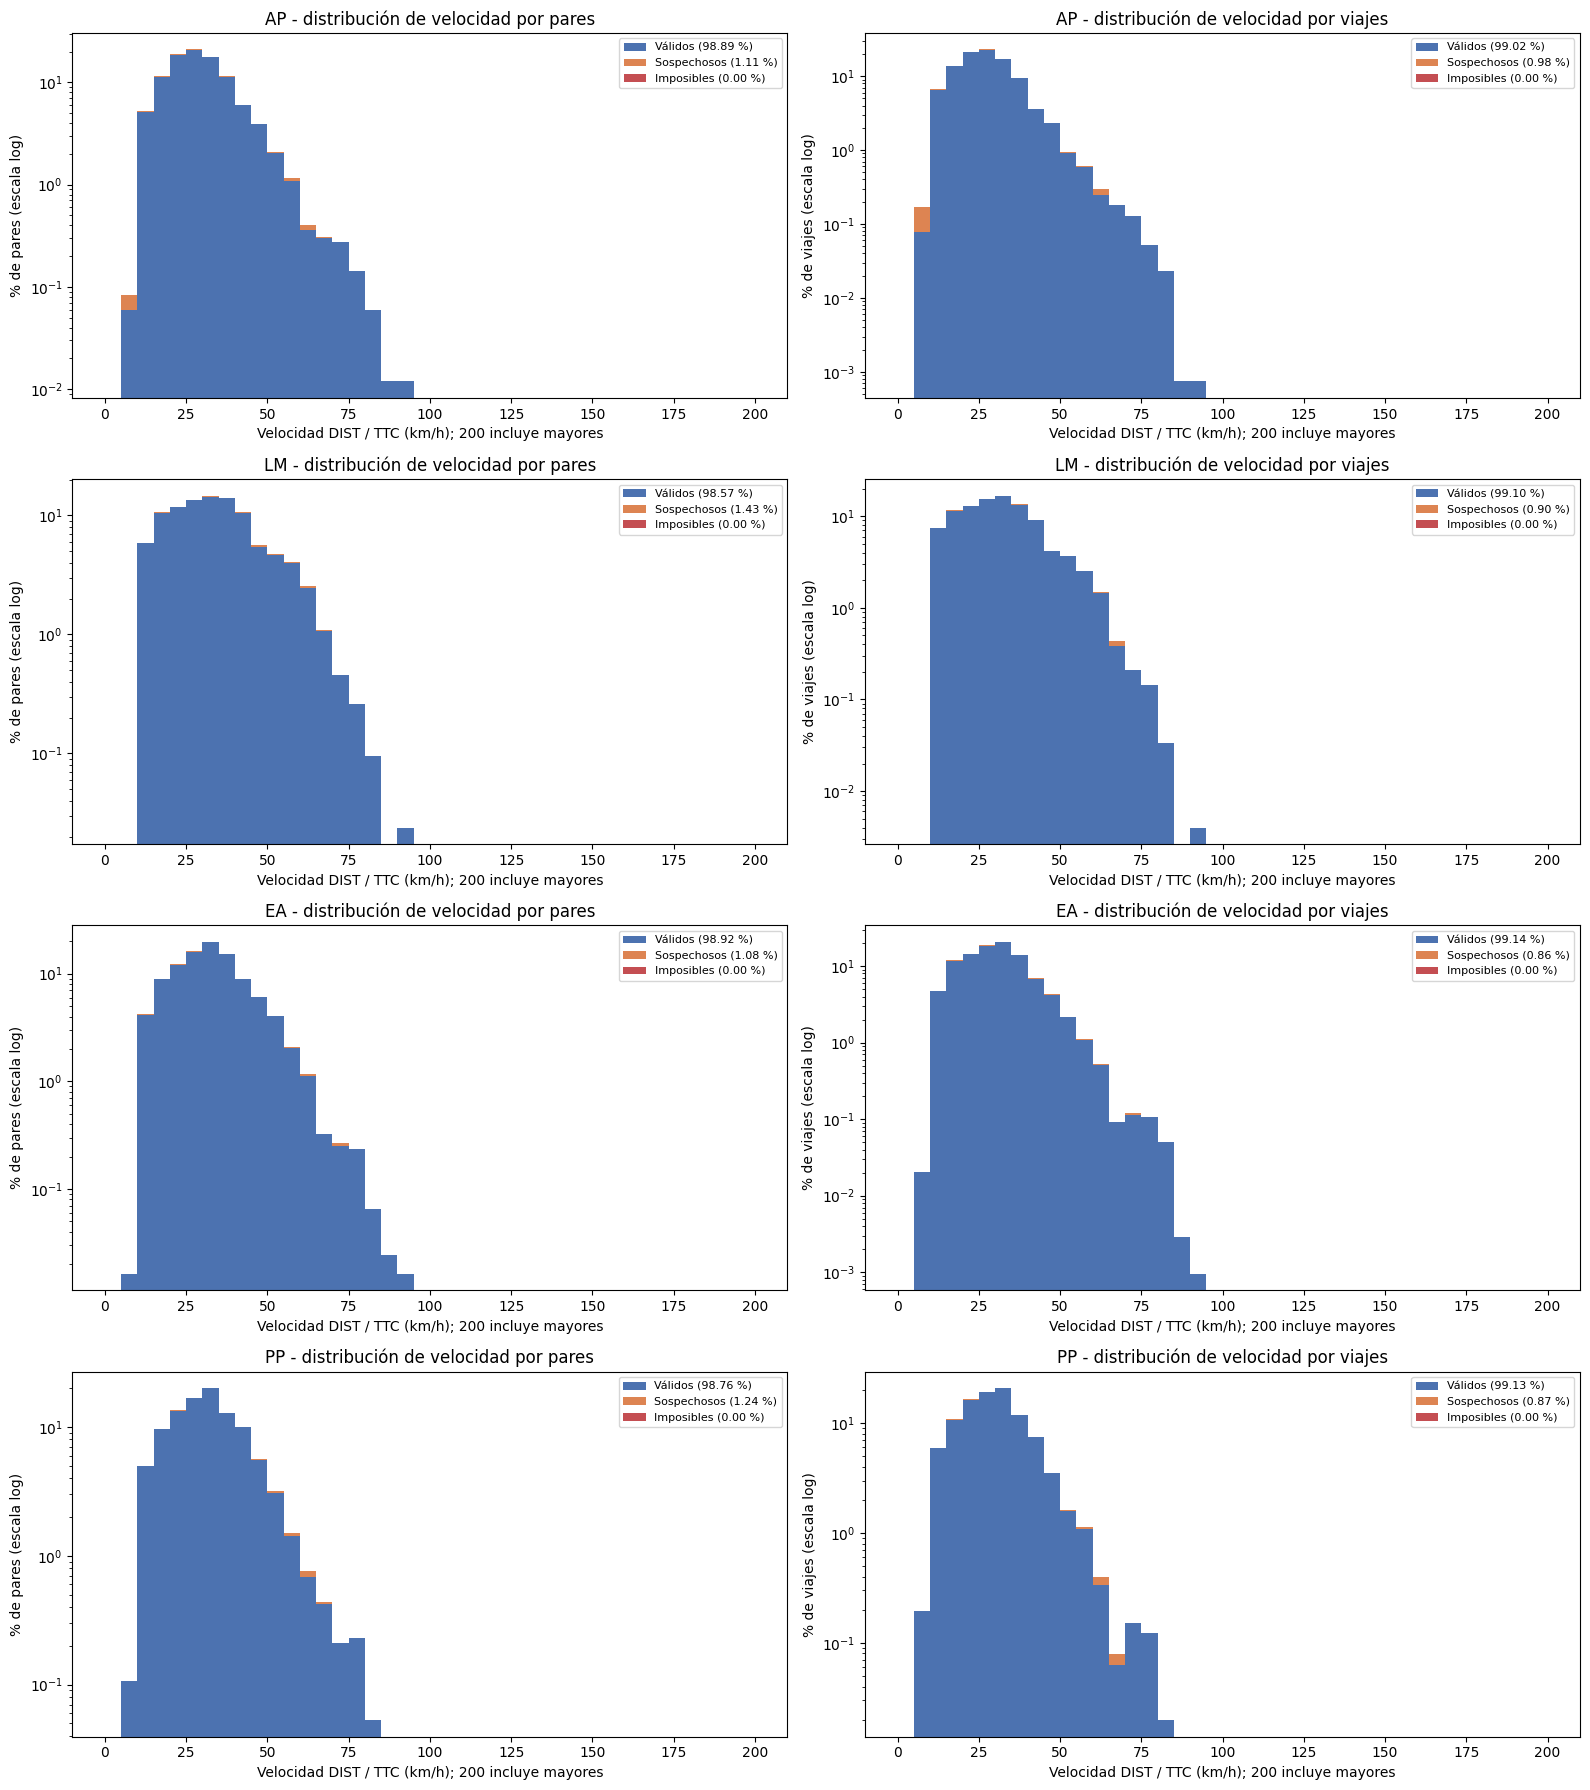

In [37]:
COLORES_CAT = {"Válidos": "#4c72b0", "Sospechosos": "#dd8452", "Imposibles": "#c44e52"}
BINS_VEL_GRAF = np.arange(0, 205, 5)   # km/h; las velocidades mayores a 200 se acumulan en el último intervalo


def mascaras_categoria(t):
    return {"Válidos": t["valido"] & ~t["sospechoso"], "Sospechosos": t["valido"] & t["sospechoso"],
            "Imposibles": t["imposible"]}


fig, axes = plt.subplots(len(PERIODOS), 2, figsize=(16, 4.5 * len(PERIODOS)))
for fila, p in enumerate(PERIODOS):
    od = skims_od[p]
    for col, (t, unidad) in enumerate([(od[od["revisado"]], "pares"), (cruces[p], "viajes")]):
        peso = pd.Series(1.0, index=t.index) if unidad == "pares" else t["Trips"]
        total = peso.sum()
        vel = t["VEL_kmh"].clip(upper=199.9)
        datos, pesos, etiquetas = [], [], []
        for etiqueta, m in mascaras_categoria(t).items():
            m = m & vel.notna()
            datos.append(vel[m])
            pesos.append(peso[m] / total * 100)
            etiquetas.append(f"{etiqueta} ({peso[m].sum() / total * 100:.2f} %)")
        ax = axes[fila, col]
        ax.hist(datos, bins=BINS_VEL_GRAF, weights=pesos, stacked=True, label=etiquetas,
                color=list(COLORES_CAT.values()))
        ax.set_yscale("log")
        ax.set_title(f"{p} - distribución de velocidad por {unidad}")
        ax.set_xlabel("Velocidad DIST / TTC (km/h); 200 incluye mayores")
        ax.set_ylabel(f"% de {unidad} (escala log)")
        ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

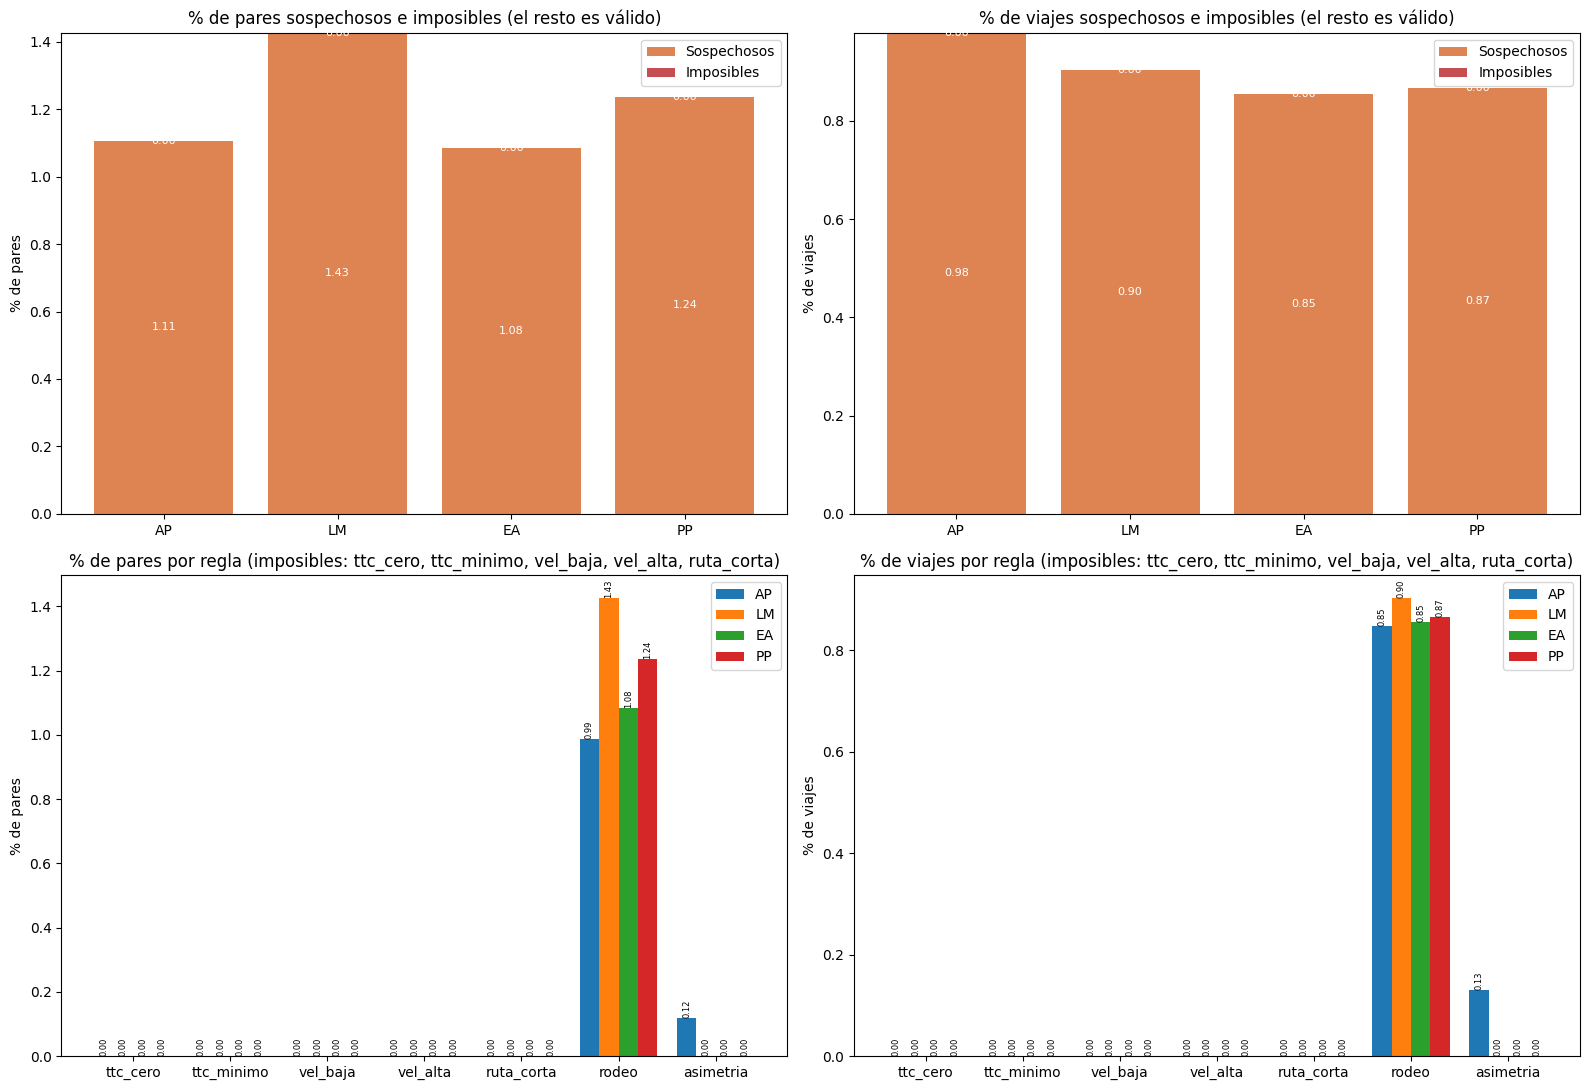

In [38]:
filas_cat = []
for p in PERIODOS:
    od, c = skims_od[p], cruces[p]
    for unidad, t, peso in [("Pares", od[od["revisado"]], None), ("Viajes", c, "Trips")]:
        total = len(t) if peso is None else t[peso].sum()
        fila = {"Periodo": p, "Unidad": unidad}
        for etiqueta, m in mascaras_categoria(t).items():
            fila[etiqueta] = (m.sum() if peso is None else t.loc[m, peso].sum()) / total * 100
        for regla in REGLAS_IMPOSIBLE + REGLAS_SOSPECHA:
            fila[regla] = (t[regla].sum() if peso is None else t.loc[t[regla], peso].sum()) / total * 100
        filas_cat.append(fila)
peso_categorias = pd.DataFrame(filas_cat).round(3)

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for col, unidad in enumerate(["Pares", "Viajes"]):
    t = peso_categorias[peso_categorias["Unidad"] == unidad].set_index("Periodo").reindex(PERIODOS)
    ax = axes[0, col]
    abajo = np.zeros(len(PERIODOS))
    for etiqueta in ["Sospechosos", "Imposibles"]:
        barras = ax.bar(PERIODOS, t[etiqueta], bottom=abajo, color=COLORES_CAT[etiqueta], label=etiqueta)
        ax.bar_label(barras, fmt="%.2f", label_type="center", fontsize=8, color="white")
        abajo += t[etiqueta].to_numpy()
    ax.set_title(f"% de {unidad.lower()} sospechosos e imposibles (el resto es válido)")
    ax.set_ylabel(f"% de {unidad.lower()}")
    ax.legend()

    ax = axes[1, col]
    reglas = REGLAS_IMPOSIBLE + REGLAS_SOSPECHA
    ancho = 0.8 / len(PERIODOS)
    for k, per in enumerate(PERIODOS):
        barras = ax.bar(np.arange(len(reglas)) + (k - 1.5) * ancho, t.loc[per, reglas], width=ancho, label=per)
        ax.bar_label(barras, fmt="%.2f", fontsize=6, rotation=90)
    ax.set_xticks(np.arange(len(reglas)), reglas)
    ax.set_title(f"% de {unidad.lower()} por regla (imposibles: {', '.join(REGLAS_IMPOSIBLE)})")
    ax.set_ylabel(f"% de {unidad.lower()}")
    ax.legend()
plt.tight_layout()
plt.show()

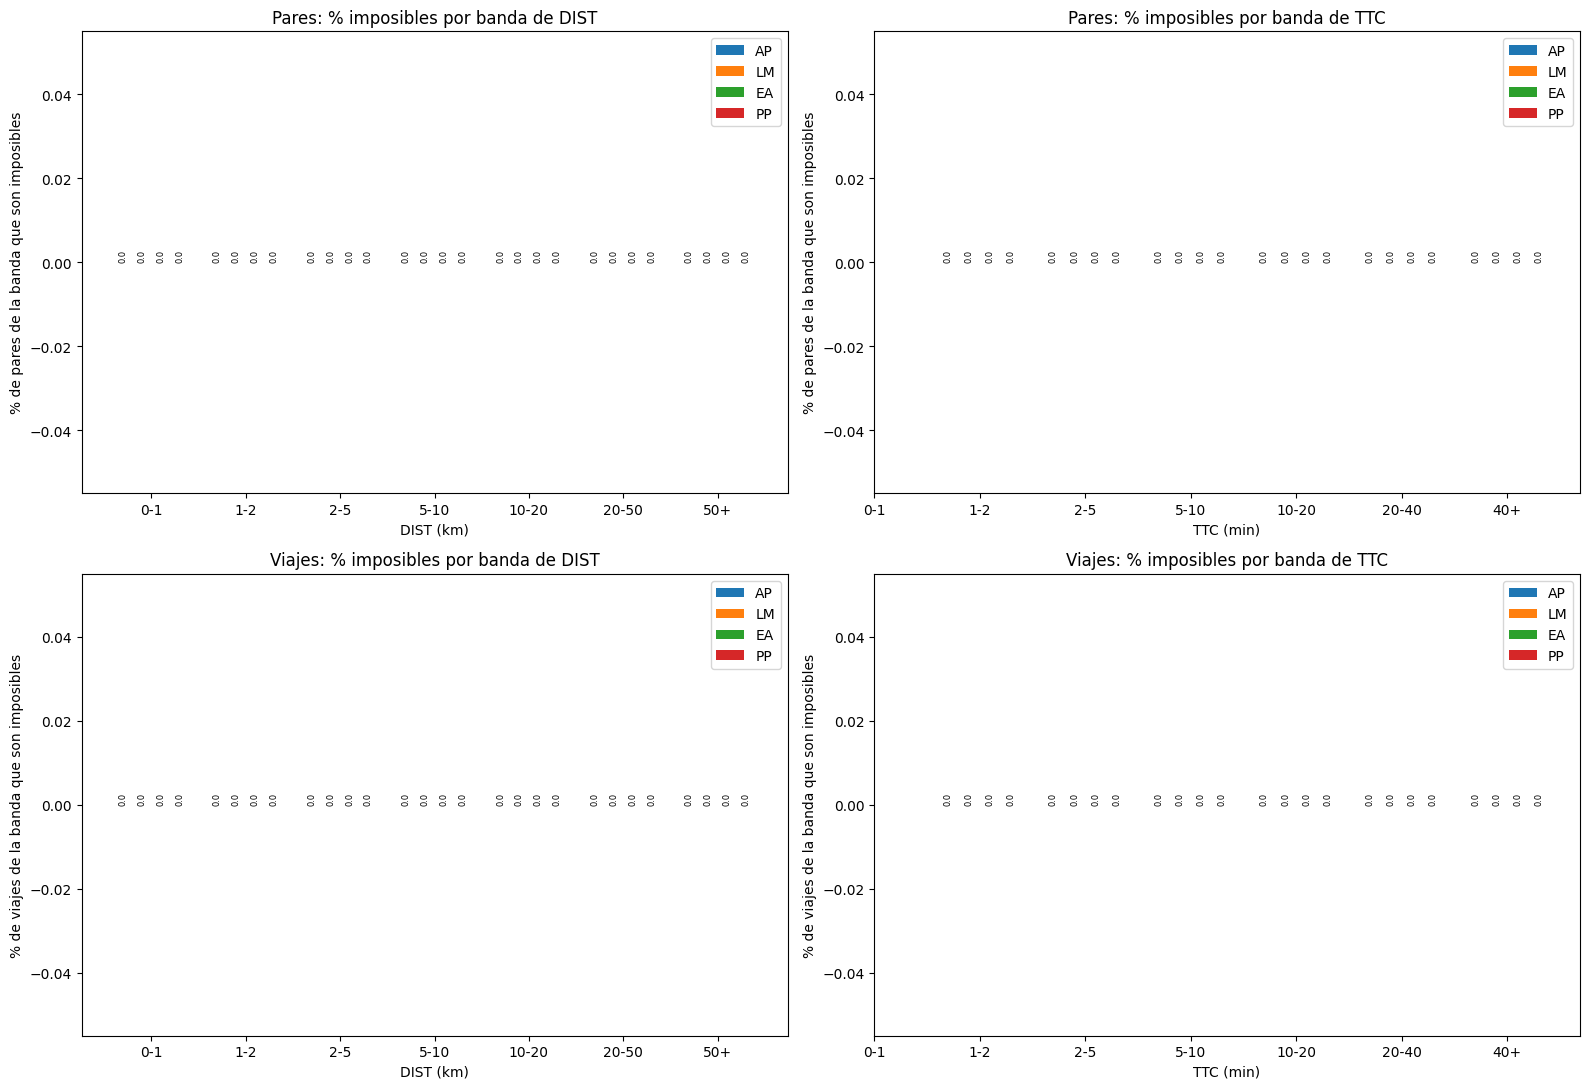

In [39]:
BANDAS = {
    "DIST": ([0, 1, 2, 5, 10, 20, 50, np.inf], ["0-1", "1-2", "2-5", "5-10", "10-20", "20-50", "50+"], "km"),
    "TTC": ([0, 1, 2, 5, 10, 20, 40, np.inf], ["0-1", "1-2", "2-5", "5-10", "10-20", "20-40", "40+"], "min"),
}

filas_banda = []
for p in PERIODOS:
    od, c = skims_od[p], cruces[p]
    for unidad, t, peso in [("Pares", od[od["revisado"]], None), ("Viajes", c, "Trips")]:
        w = pd.Series(1.0, index=t.index) if peso is None else t[peso]
        for col, (bins, labels, _) in BANDAS.items():
            banda = pd.cut(t[col], bins=bins, labels=labels, right=False)
            g = pd.DataFrame({"total": w, "imposible": w.where(t["imposible"], 0),
                              "sospechoso": w.where(t["sospechoso"], 0), "banda": banda}) \
                .groupby("banda", observed=False).sum()
            for b, fila in g.iterrows():
                filas_banda.append({
                    "Periodo": p, "Unidad": unidad, "Variable": col, "Banda": b,
                    "Total": fila["total"], "Imposibles": fila["imposible"], "Sospechosos": fila["sospechoso"],
                    "% imposibles en la banda": fila["imposible"] / fila["total"] * 100 if fila["total"] else np.nan,
                    "% de todos los imposibles": fila["imposible"] / g["imposible"].sum() * 100 if g["imposible"].sum() else np.nan,
                    "% del total": fila["total"] / g["total"].sum() * 100,
                })
imposibles_por_banda = pd.DataFrame(filas_banda).round(3)

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for fila_ax, unidad in enumerate(["Pares", "Viajes"]):
    for col_ax, col in enumerate(BANDAS):
        ax = axes[fila_ax, col_ax]
        labels, unidad_col = BANDAS[col][1], BANDAS[col][2]
        ancho = 0.8 / len(PERIODOS)
        for k, per in enumerate(PERIODOS):
            t = imposibles_por_banda[(imposibles_por_banda["Periodo"] == per) & (imposibles_por_banda["Unidad"] == unidad)
                                     & (imposibles_por_banda["Variable"] == col)]
            barras = ax.bar(np.arange(len(labels)) + (k - 1.5) * ancho, t["% imposibles en la banda"], width=ancho, label=per)
            ax.bar_label(barras, fmt="%.1f", fontsize=6, rotation=90)
        ax.set_xticks(np.arange(len(labels)), labels)
        ax.set_xlabel(f"{col} ({unidad_col})")
        ax.set_ylabel(f"% de {unidad.lower()} de la banda que son imposibles")
        ax.set_title(f"{unidad}: % imposibles por banda de {col}")
        ax.legend()
plt.tight_layout()
plt.show()

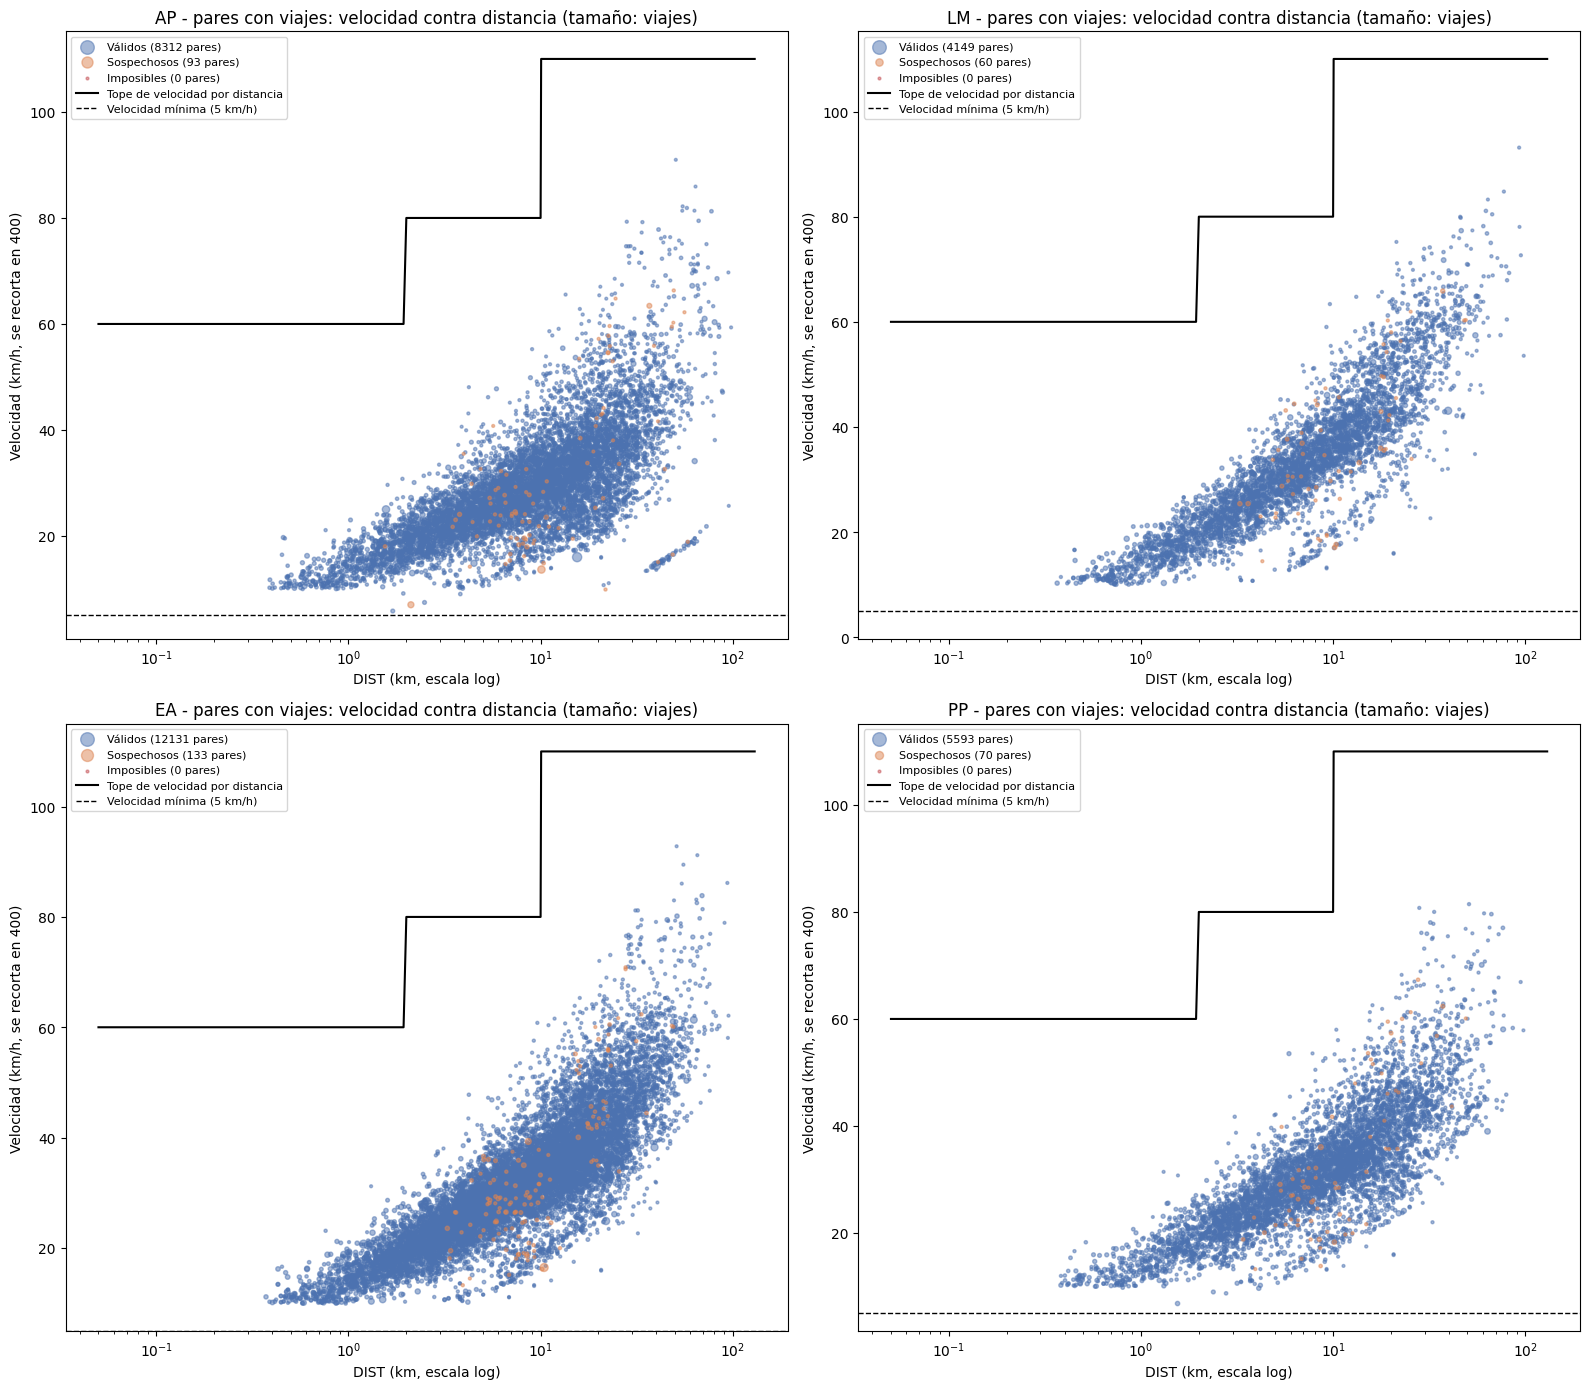

In [40]:
dist_linea = np.linspace(0.05, 130, 2000)
fig, axes = plt.subplots(2, 2, figsize=(16, 14))
for ax, p in zip(axes.flat, PERIODOS):
    c = cruces[p][cruces[p]["VEL_kmh"].notna()]
    for etiqueta, m in mascaras_categoria(c).items():
        ax.scatter(c.loc[m, "DIST"], c.loc[m, "VEL_kmh"].clip(upper=400), s=4 + 40 * c.loc[m, "Trips"] / c["Trips"].max(),
                   alpha=0.5, color=COLORES_CAT[etiqueta], label=f"{etiqueta} ({int(m.sum())} pares)")
    ax.plot(dist_linea, vel_maxima(dist_linea, VEL_MAX_POR_DIST), color="black", lw=1.5, label="Tope de velocidad por distancia")
    ax.axhline(VEL_MIN, color="black", lw=1, ls="--", label=f"Velocidad mínima ({VEL_MIN} km/h)")
    ax.set_xscale("log")
    ax.set_xlabel("DIST (km, escala log)")
    ax.set_ylabel("Velocidad (km/h, se recorta en 400)")
    ax.set_title(f"{p} - pares con viajes: velocidad contra distancia (tamaño: viajes)")
    ax.legend(fontsize=8, markerscale=2)
plt.tight_layout()
plt.show()

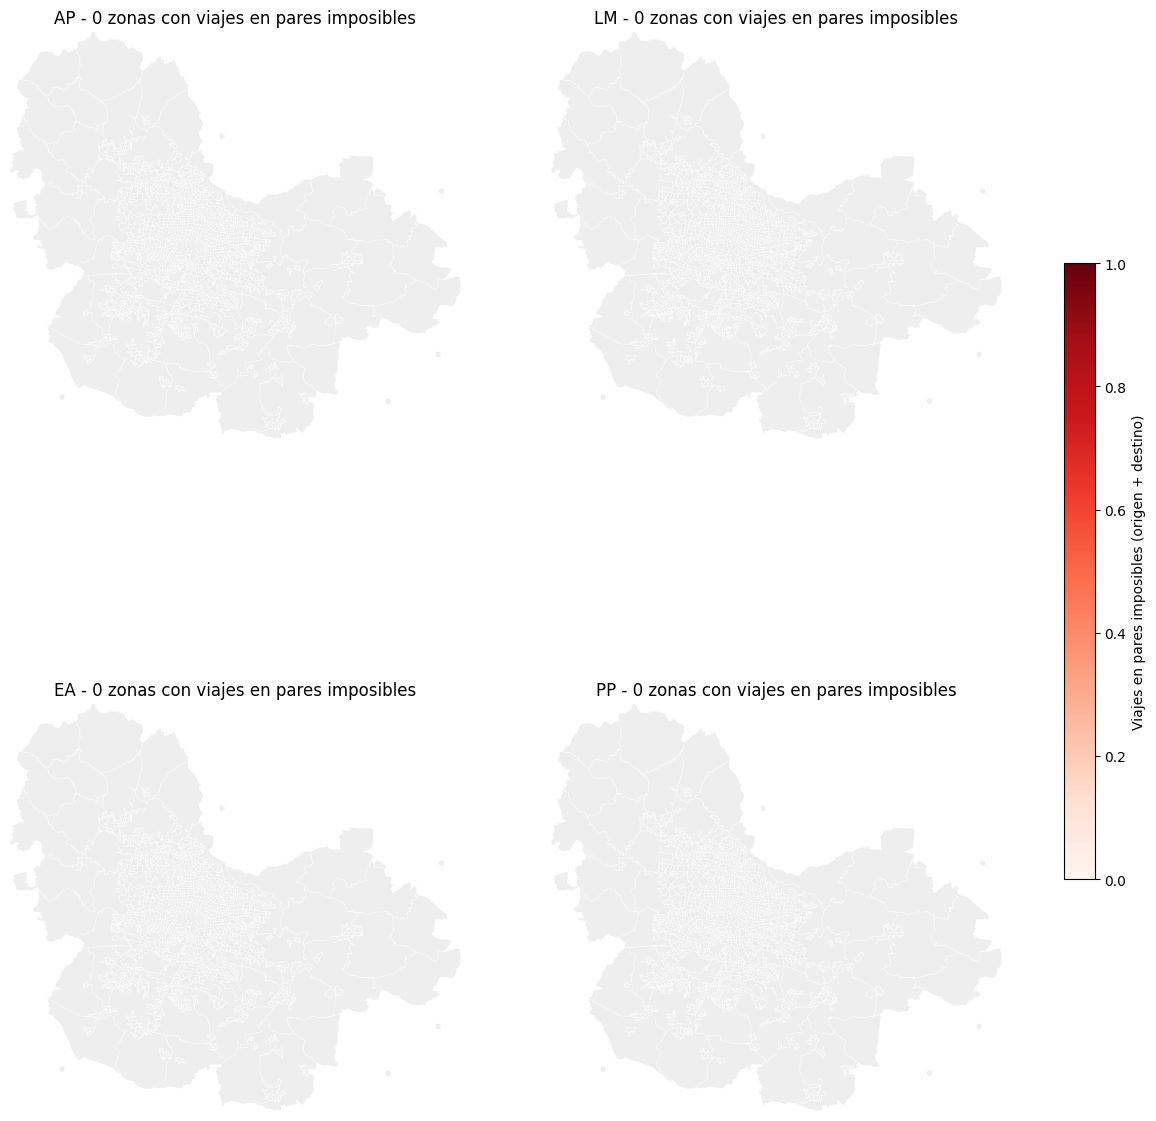

Zonas con viajes afectados por periodo: {'AP': 0, 'LM': 0, 'EA': 0, 'PP': 0} | en total: 0
10 zonas con más viajes afectados (suma de los 4 periodos)


,Municipio,Viajes afectados como origen,Viajes afectados como destino,Viajes afectados (origen + destino),Periodos,Viajes afectados AP,Viajes afectados LM,Viajes afectados EA,Viajes afectados PP
Zona_visum,,,,,,,,,


In [41]:
extremos_imp = pd.concat([
    pares_imposibles_con_viajes[["Periodo", "Zona_origen", "Trips"]].rename(columns={"Zona_origen": "Zona"}).assign(Rol="origen"),
    pares_imposibles_con_viajes[["Periodo", "Zona_destino", "Trips"]].rename(columns={"Zona_destino": "Zona"}).assign(Rol="destino"),
])
viajes_zona_imp = extremos_imp.groupby(["Periodo", "Zona"])["Trips"].sum()

zonas_afectadas = pd.DataFrame({
    "Viajes afectados como origen": extremos_imp[extremos_imp["Rol"] == "origen"].groupby("Zona")["Trips"].sum(),
    "Viajes afectados como destino": extremos_imp[extremos_imp["Rol"] == "destino"].groupby("Zona")["Trips"].sum(),
}).fillna(0)
zonas_afectadas["Viajes afectados (origen + destino)"] = zonas_afectadas.sum(axis=1)
zonas_afectadas["Periodos"] = extremos_imp.groupby("Zona")["Periodo"].nunique()
zonas_afectadas = zonas_afectadas.join(viajes_zona_imp.unstack("Periodo").reindex(columns=PERIODOS).fillna(0)
                                       .add_prefix("Viajes afectados "))
zonas_afectadas.insert(0, "Municipio", zonas_afectadas.index.map(municipio))
zonas_afectadas.index.name = "Zona_visum"
zonas_afectadas = zonas_afectadas.sort_values("Viajes afectados (origen + destino)", ascending=False).round(1)

vmax_err = viajes_zona_imp.quantile(0.95) if len(viajes_zona_imp) else 1   # con la base nueva puede no haber imposibles
periodos_imp = viajes_zona_imp.index.get_level_values("Periodo")
fig, axes = plt.subplots(2, 2, figsize=(16, 16))
for ax, p in zip(axes.flat, PERIODOS):
    v = viajes_zona_imp.loc[p] if p in periodos_imp else pd.Series(dtype=float)
    afectadas = zonas_geo.assign(Viajes_err=zonas_geo["id_visum"].map(v)).dropna(subset=["Viajes_err"])
    zonas_geo.plot(ax=ax, color="#eeeeee", edgecolor="white", linewidth=0.2)
    if len(afectadas):
        afectadas.plot(ax=ax, column="Viajes_err", cmap="Reds", vmin=0, vmax=vmax_err, edgecolor="black", linewidth=0.3)
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_title(f"{p} - {len(v)} zonas con viajes en pares imposibles")
    ax.set_axis_off()

fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(0, vmax_err), cmap="Reds"),
             ax=axes, shrink=0.5, label="Viajes en pares imposibles (origen + destino)")
plt.show()

print("Zonas con viajes afectados por periodo:", {p: int((periodos_imp == p).sum()) for p in PERIODOS},
      "| en total:", len(zonas_afectadas))
print("10 zonas con más viajes afectados (suma de los 4 periodos)")
zonas_afectadas.head(10)

In [42]:
# Sensibilidad: se cambia un umbral a la vez y se cuentan los pares y viajes que quedarían como imposibles
ESCENARIOS = {
    "Vigente": {},
    "TTC mínimo 15 s": {"ttc_min": 0.25},
    "TTC mínimo 60 s": {"ttc_min": 1.0},
    "Velocidad mínima 10 km/h": {"vel_min": 10},
    "Velocidad máxima estricta (50, 70 y 100 km/h)": {"vel_max_por_dist": [(2, 50), (10, 70), (np.inf, 100)]},
    "Velocidad máxima laxa (80, 100 y 120 km/h)": {"vel_max_por_dist": [(2, 80), (10, 100), (np.inf, 120)]},
    "Línea recta 0.3": {"factor_recta_min": 0.3},
    "Línea recta 0.7": {"factor_recta_min": 0.7},
    "Solo TTC cero y más de 120 km/h": {"ttc_min": 0, "vel_min": 0, "factor_recta_min": 0,
                                        "vel_max_por_dist": [(np.inf, 120)]},
}

filas_sens = []
for escenario, cambios in ESCENARIOS.items():
    for p in PERIODOS:
        od, c = skims_od[p], cruces_todos[p]
        imp_od = pd.concat(reglas_imposible(od, **cambios), axis=1).any(axis=1)
        imp_c = pd.concat(reglas_imposible(c, **cambios), axis=1).any(axis=1)
        filas_sens.append({
            "Escenario": escenario,
            "Periodo": p,
            "Pares imposibles": imp_od.sum(),
            "% de pares revisados": round(imp_od.sum() / od["revisado"].sum() * 100, 3),
            "Pares imposibles con viajes": imp_c.sum(),
            "Viajes afectados": round(c.loc[imp_c, "Trips"].sum(), 1),
            "% de viajes": round(c.loc[imp_c, "Trips"].sum() / c["Trips"].sum() * 100, 2),
        })

sensibilidad_umbrales = pd.DataFrame(filas_sens)

orden_escenarios = list(ESCENARIOS)
print("% de viajes afectados por escenario")
display(sensibilidad_umbrales.pivot(index="Escenario", columns="Periodo", values="% de viajes")
        .reindex(index=orden_escenarios, columns=PERIODOS))
print("Pares imposibles por escenario")
sensibilidad_umbrales.pivot(index="Escenario", columns="Periodo", values="Pares imposibles") \
    .reindex(index=orden_escenarios, columns=PERIODOS)

% de viajes afectados por escenario


Periodo,AP,LM,EA,PP
Escenario,,,,
Vigente,0.00,0.0,0.00,0.00
TTC mínimo 15 s,0.00,0.0,0.00,0.00
TTC mínimo 60 s,0.00,0.0,0.00,0.00
Velocidad mínima 10 km/h,0.16,0.0,0.02,0.18
"Velocidad máxima estricta (50, 70 y 100 km/h)",0.00,0.0,0.00,0.00
"Velocidad máxima laxa (80, 100 y 120 km/h)",0.00,0.0,0.00,0.00
Línea recta 0.3,0.00,0.0,0.00,0.00
Línea recta 0.7,0.02,0.0,0.00,0.00
Solo TTC cero y más de 120 km/h,0.00,0.0,0.00,0.00


Pares imposibles por escenario


Periodo,AP,LM,EA,PP
Escenario,,,,
Vigente,0,0,0,0
TTC mínimo 15 s,0,0,0,0
TTC mínimo 60 s,0,0,0,0
Velocidad mínima 10 km/h,7,0,2,6
"Velocidad máxima estricta (50, 70 y 100 km/h)",0,0,0,0
"Velocidad máxima laxa (80, 100 y 120 km/h)",0,0,0,0
Línea recta 0.3,0,0,0,0
Línea recta 0.7,1,0,0,0
Solo TTC cero y más de 120 km/h,0,0,0,0


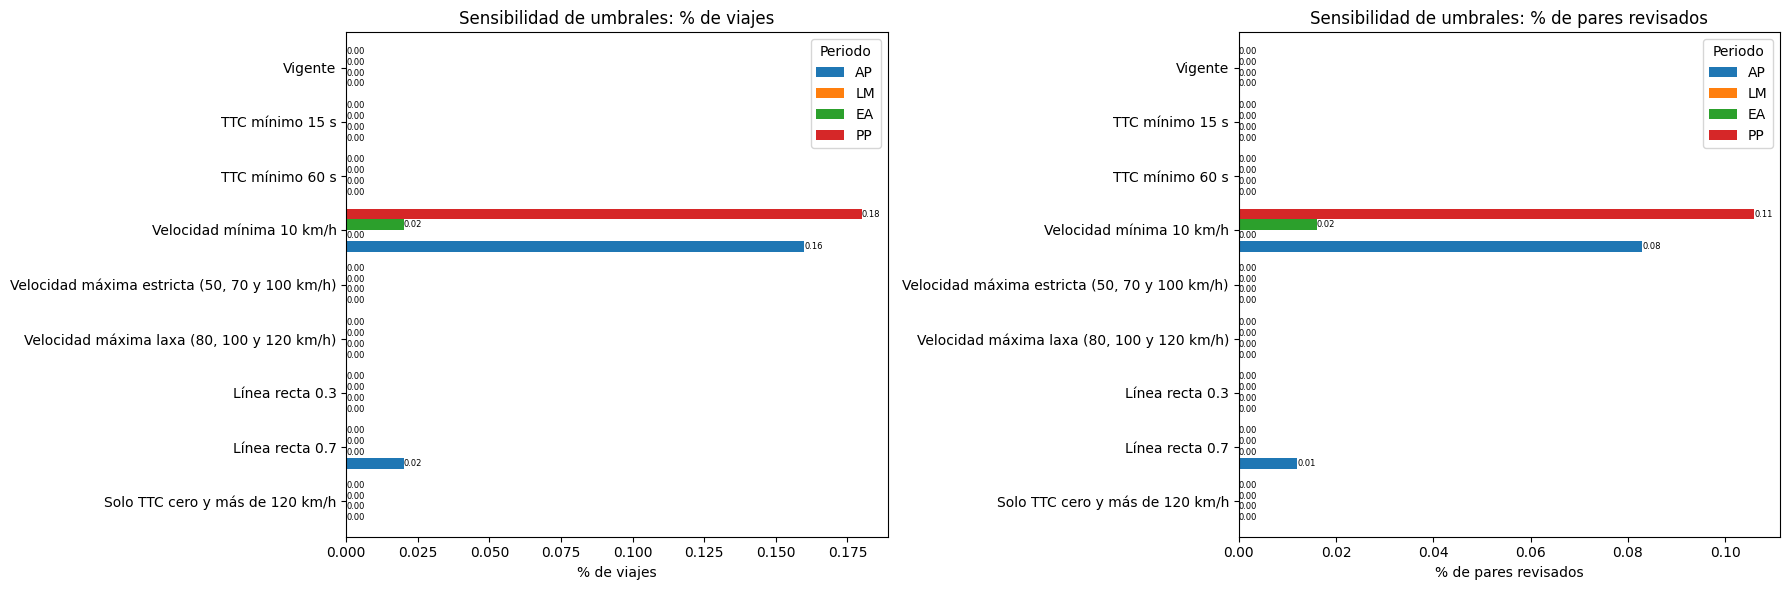

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for ax, columna in zip(axes, ["% de viajes", "% de pares revisados"]):
    t = sensibilidad_umbrales.pivot(index="Escenario", columns="Periodo", values=columna) \
        .reindex(index=orden_escenarios, columns=PERIODOS)
    t.iloc[::-1].plot.barh(ax=ax, width=0.8)
    ax.set_xlabel(columna)
    ax.set_ylabel("")
    ax.set_title(f"Sensibilidad de umbrales: {columna}")
    for contenedor in ax.containers:
        ax.bar_label(contenedor, fmt="%.2f", fontsize=6)
plt.tight_layout()
plt.show()

In [44]:
ruta_imp = os.path.join(R_EXCEL, f"velocidades_imposibles{SUFIJO}.xlsx")
with pd.ExcelWriter(ruta_imp) as xls:
    REGLAS.to_excel(xls, sheet_name="reglas", index=False)
    imp_resumen_periodo.to_excel(xls, sheet_name="resumen_periodo", index=False)
    imp_resumen_tipo.to_excel(xls, sheet_name="resumen_tipo", index=False)
    pares_imposibles.to_excel(xls, sheet_name="pares_imposibles", index=False)
    pares_imposibles_con_viajes.to_excel(xls, sheet_name="pares_imposibles_con_viajes", index=False)
    zonas_afectadas.to_excel(xls, sheet_name="zonas_afectadas")
    pares_sospechosos.to_excel(xls, sheet_name="pares_sospechosos", index=False)
print("Guardado en", ruta_imp)

Guardado en C:\proyectos\red-vial-guadalajara\skim_matrices\resultados_filtro_2\excel\velocidades_imposibles_filtro_2.xlsx


- Con esta base no hay ningún par imposible en ningún periodo, con ninguna de las 5 reglas.
- Sospechosos: de 60 a 133 pares por periodo, casi todos por rodeo, con 0.8 a 0.9 % de los viajes.
- En la sensibilidad solo salen imposibles con velocidad mínima de 10 km/h (7 pares en AP, 2 en EA y 6 en PP, 0.2 % de los viajes o menos) y con línea recta 0.7 (1 par en AP).
- Por eso la hoja de pares imposibles va vacía y no se genera el mapa HTML de zonas afectadas.

## Cotejo de OD de skims contra OD con viajes
Con esta base la skim solo tiene ruta en los pares con demanda.

In [45]:
filas_cotejo = []
sin_par = cruce_resumen.set_index("Periodo")["Pares sin par en la skim"]
for p in PERIODOS:
    c = cruces_todos[p]
    vp, hf, lf = (c[m] > 0 for m in MODOS)
    carga = hf | lf
    con_viajes = c["Trips"] > 0
    filas_cotejo.append({
        "Periodo": p,
        "Pares de la skim": len(skims_od[p]),
        "Pares con viajes VP": vp.sum(),
        "Pares con viajes carga pesada": hf.sum(),
        "Pares con viajes carga ligera": lf.sum(),
        "Pares con viajes (cualquier tipo)": con_viajes.sum(),
        "% de la skim con viajes": round(con_viajes.sum() / len(skims_od[p]) * 100, 3),
        "Solo autos": (vp & ~carga).sum(),
        "Solo carga": (~vp & carga).sum(),
        "Autos y carga": (vp & carga).sum(),
        "Los tres tipos": (vp & hf & lf).sum(),
        "Pares con viajes intrazonales": (con_viajes & c["diagonal"]).sum(),
        "Pares de demanda sin par en la skim": sin_par[p],
    })

cotejo_od = pd.DataFrame(filas_cotejo)
cotejo_od.set_index("Periodo").T

Periodo,AP,LM,EA,PP
Pares de la skim,4431025.000,4431025.000,4431025.000,4431025.000
Pares con viajes VP,8733.000,4395.000,12573.000,5922.000
Pares con viajes carga pesada,261.000,577.000,887.000,285.000
Pares con viajes carga ligera,329.000,744.000,1147.000,360.000
Pares con viajes (cualquier tipo),9241.000,5521.000,14239.000,6492.000
% de la skim con viajes,0.209,0.125,0.321,0.147
Solo autos,8710.000,4357.000,12488.000,5900.000
Solo carga,508.000,1126.000,1666.000,570.000
Autos y carga,23.000,38.000,85.000,22.000
Los tres tipos,4.000,9.000,19.000,5.000


In [46]:
viajes_zona = pd.DataFrame({
    p: c.groupby("Origin_zona")["Trips"].sum().add(c.groupby("Destination_zona")["Trips"].sum(), fill_value=0)
    for p, c in cruces_todos.items()
}).reindex(zonas).fillna(0)
viajes_zona.index.name = "Zona_visum"

sin_viajes = viajes_zona[PERIODOS] <= 0
zonas_sin_viajes = sin_viajes[sin_viajes.any(axis=1)].copy()
zonas_sin_viajes["Periodos sin viajes"] = zonas_sin_viajes[PERIODOS].sum(axis=1)
zonas_sin_viajes["Sin viajes en ningún periodo"] = zonas_sin_viajes["Periodos sin viajes"] == len(PERIODOS)
zonas_sin_viajes["Viajes en los 4 periodos"] = viajes_zona.loc[zonas_sin_viajes.index, PERIODOS].sum(axis=1).round().astype(int)
zonas_sin_viajes.insert(0, "Municipio", zonas_sin_viajes.index.map(municipio))
guardar_csv(zonas_sin_viajes, "zonas_sin_viajes", index=True)

resumen_sin_viajes = pd.Series({**{p: sin_viajes[p].sum() for p in PERIODOS},
                                "Ningún periodo": sin_viajes.all(axis=1).sum()}, name="Zonas sin viajes").to_frame()
resumen_sin_viajes["% de las zonas"] = (resumen_sin_viajes["Zonas sin viajes"] / N_ZONAS * 100).round(1)
display(resumen_sin_viajes)

print("Zonas sin viajes en ningún periodo, por municipio")
display(zonas_sin_viajes[zonas_sin_viajes["Sin viajes en ningún periodo"]]["Municipio"].value_counts().to_frame("Zonas"))

Guardado en C:\proyectos\red-vial-guadalajara\skim_matrices\resultados_filtro_2\tablas\zonas_sin_viajes_filtro_2.csv


,Zonas sin viajes,% de las zonas
AP,573,27.2
LM,706,33.5
EA,524,24.9
PP,644,30.6
Ningún periodo,453,21.5


Zonas sin viajes en ningún periodo, por municipio


,Zonas
Municipio,
Tlajomulco de Zúñiga,134
Zapopan,101
Tonalá,71
San Pedro Tlaquepaque,55
El Salto,28
Guadalajara,26
Zapotlanejo,22
Juanacatlán,9
Ixtlahuacán de los Membrillos,6


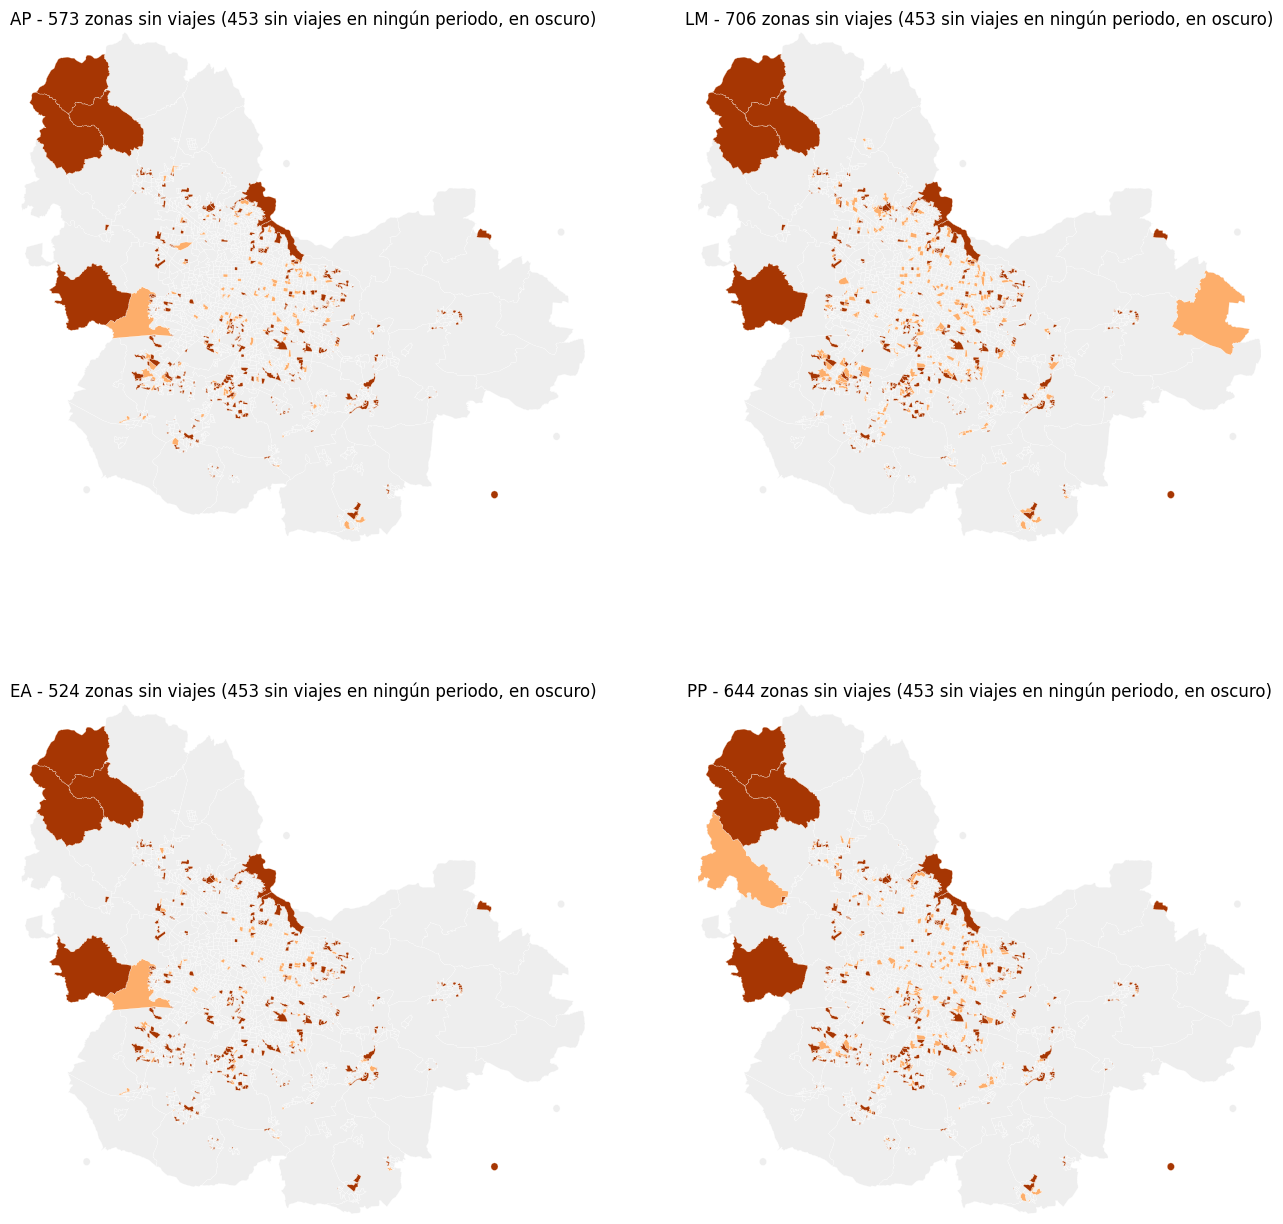

In [47]:
nunca = sin_viajes.index[sin_viajes.all(axis=1)]
fig, axes = plt.subplots(2, 2, figsize=(16, 16))
for ax, p in zip(axes.flat, PERIODOS):
    sin_p = sin_viajes.index[sin_viajes[p]]
    zonas_geo.plot(ax=ax, color="#eeeeee", edgecolor="white", linewidth=0.2)
    zonas_geo[zonas_geo["id_visum"].isin(sin_p)].plot(ax=ax, color="#fdae6b", edgecolor="white", linewidth=0.2)
    zonas_geo[zonas_geo["id_visum"].isin(nunca)].plot(ax=ax, color="#a63603", edgecolor="white", linewidth=0.2)
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_title(f"{p} - {len(sin_p)} zonas sin viajes ({len(nunca)} sin viajes en ningún periodo, en oscuro)")
    ax.set_axis_off()
plt.show()

- Solo de 0.13 a 0.32 % de los pares de la skim tiene viajes (de 5,521 pares en LM a 14,239 en EA).
- Casi todos son solo de autos; muy pocos pares tienen autos y carga.
- Todos los pares de la demanda existen en la skim, pero algunos valen 999999: de 1,116 viajes sin ruta en AP a 2,669 en LM.
- Zonas sin viajes: 573 en AP, 706 en LM, 524 en EA y 644 en PP. 453 no tienen viajes en ningún periodo, sobre todo en Tlajomulco, Zapopan y Tonalá.

## Resultados por viaje: todos y sin imposibles

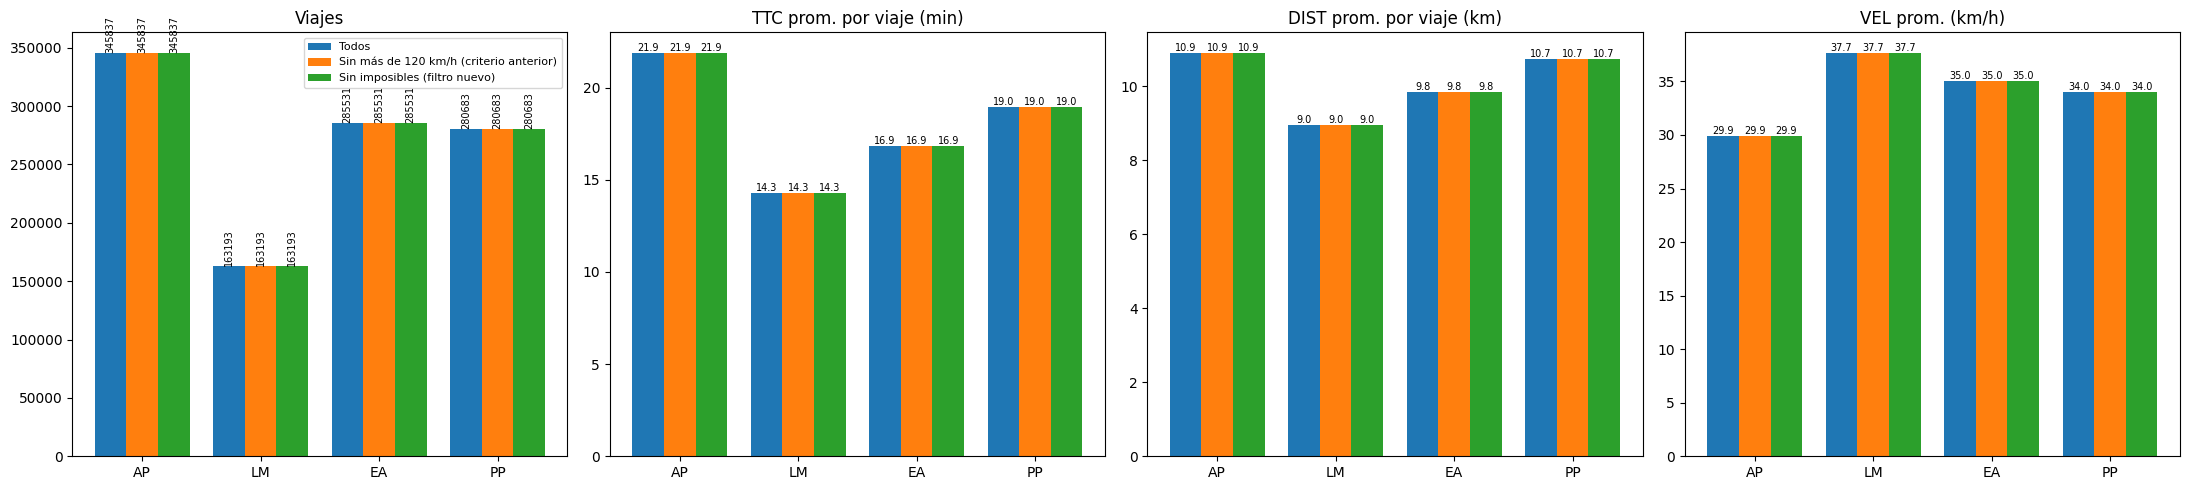

TTC prom. por viaje (min)                                          \
Versión Sin imposibles (filtro nuevo) Sin más de 120 km/h (criterio anterior)   
Periodo                                                                         
AP                              21.91                                   21.91   
LM                              14.28                                   14.28   
EA                              16.86                                   16.86   
PP                              18.96                                   18.96   

                   DIST prom. por viaje (km)  \
Versión  Todos Sin imposibles (filtro nuevo)   
Periodo                                        
AP       21.91                         10.91   
LM       14.28                          8.96   
EA       16.86                          9.85   
PP       18.96                         10.74   

                                                        \
Versión Sin más de 120 km/h (criterio anterior)  Todos   
Periodo                                                  
AP                                        10.91  10.91   
LM                                         8.96   8.96   
EA                                         9.85   9.85   
PP                                        10.74  10.74   

                     VEL prom. (km/h)                                          \
Versión Sin imposibles (filtro nuevo) Sin más de 120 km/h (criterio anterior)   
Periodo                                                                         
AP                               29.9                                    29.9   
LM                               37.7                                    37.7   
EA                               35.0                                    35.0   
PP                               34.0                                    34.0   

               
Versión Todos  
Periodo        
AP       29.9  
LM       37.7  
EA       35.0  
PP       34.0

In [48]:
def promedios_por_viaje(c, columna_viajes="Trips"):
    w = c[columna_viajes]
    ttc = (c["TTC"] * w).sum() / w.sum()
    dist = (c["DIST"] * w).sum() / w.sum()
    return {
        "Viajes": round(w.sum(), 1),
        "TTC prom. por viaje (min)": round(ttc, 2),
        "DIST prom. por viaje (km)": round(dist, 2),
        "VEL prom. (km/h)": round(dist / (ttc / 60), 1),
    }


# Todos, criterio anterior (quitar solo más de 120 km/h) y filtro nuevo
versiones_comparativa = {
    "Todos": cruces,
    "Sin más de 120 km/h (criterio anterior)": {p: c[~(c["VEL_kmh"] > 120)] for p, c in cruces.items()},
    "Sin imposibles (filtro nuevo)": cruces_validos,
}
comparativa_viajes = pd.DataFrame([
    {"Periodo": p, "Versión": version, **promedios_por_viaje(tabla[p])}
    for p in PERIODOS for version, tabla in versiones_comparativa.items()
])

metricas = ["Viajes", "TTC prom. por viaje (min)", "DIST prom. por viaje (km)", "VEL prom. (km/h)"]
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
ancho = 0.8 / len(versiones_comparativa)
for ax, metrica in zip(axes, metricas):
    for k, version in enumerate(versiones_comparativa):
        t = comparativa_viajes[comparativa_viajes["Versión"] == version].set_index("Periodo").reindex(PERIODOS)
        barras = ax.bar(np.arange(len(PERIODOS)) + (k - 1) * ancho, t[metrica], width=ancho, label=version)
        ax.bar_label(barras, fmt="%.0f" if metrica == "Viajes" else "%.1f", fontsize=7, rotation=90 if metrica == "Viajes" else 0)
    ax.set_xticks(np.arange(len(PERIODOS)), PERIODOS)
    ax.set_title(metrica)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

comparativa_viajes.pivot(index="Periodo", columns="Versión", values=metricas[1:]).reindex(PERIODOS)

- Como no hay imposibles, las tres versiones dan lo mismo.
- Tiempo por viaje: 21.9 min en AP, 14.3 en LM, 16.9 en EA y 19.0 en PP. Distancia: de 9.0 a 10.9 km.
- Velocidad promedio: 29.9 km/h en AP, 37.7 en LM, 35.0 en EA y 34.0 en PP. Es más baja que en la base anterior (41 a 52 km/h).

### Histogramas por viajes

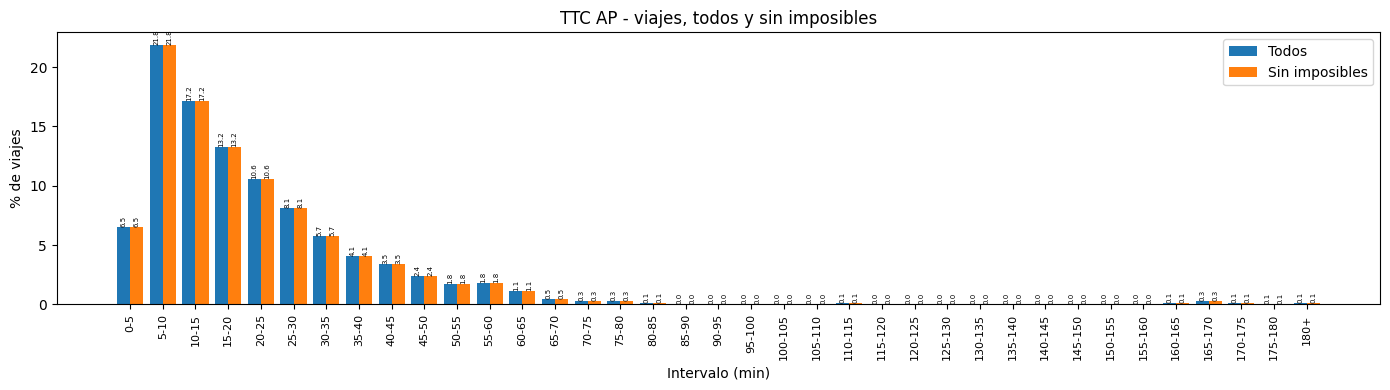

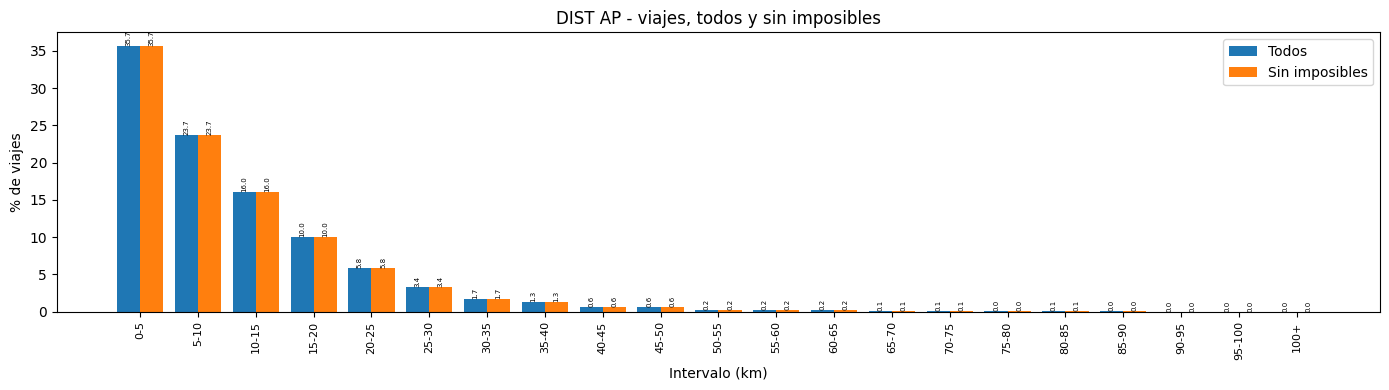

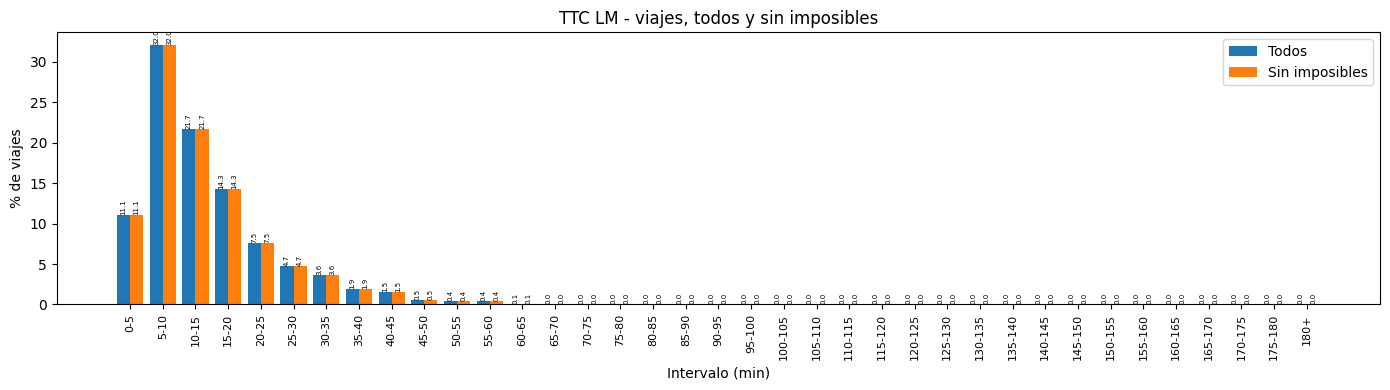

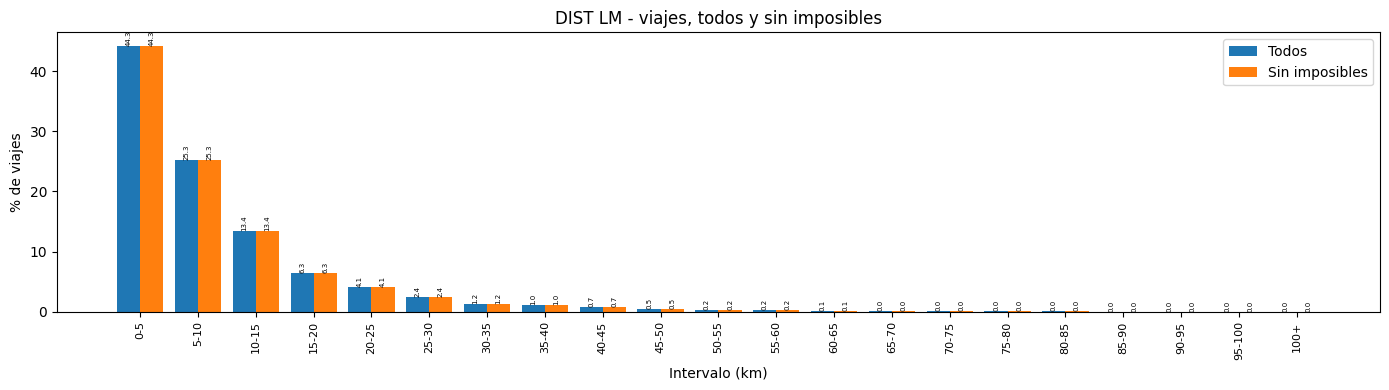

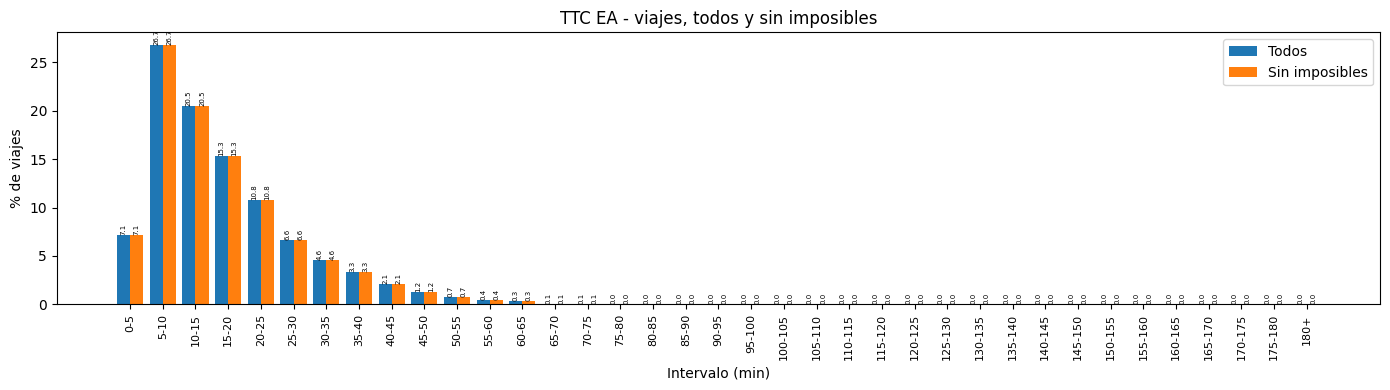

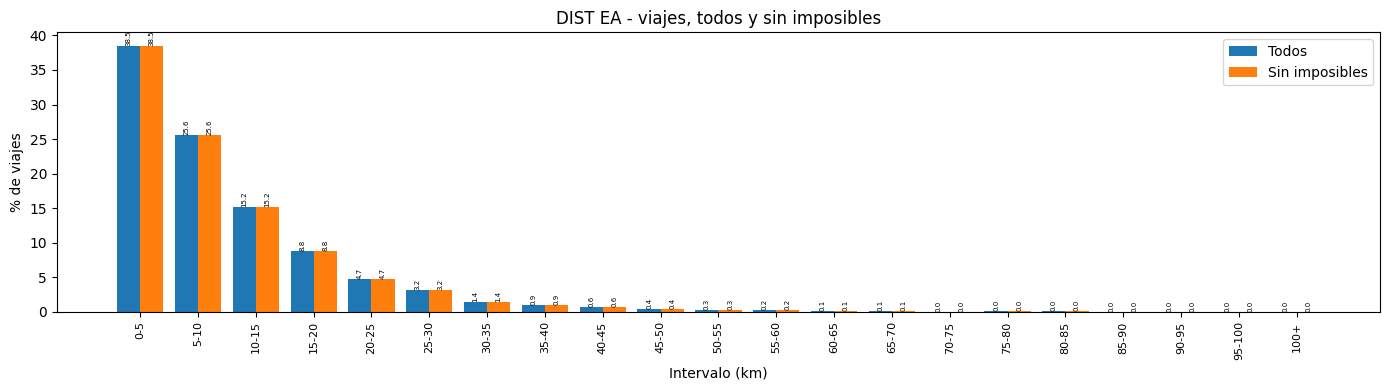

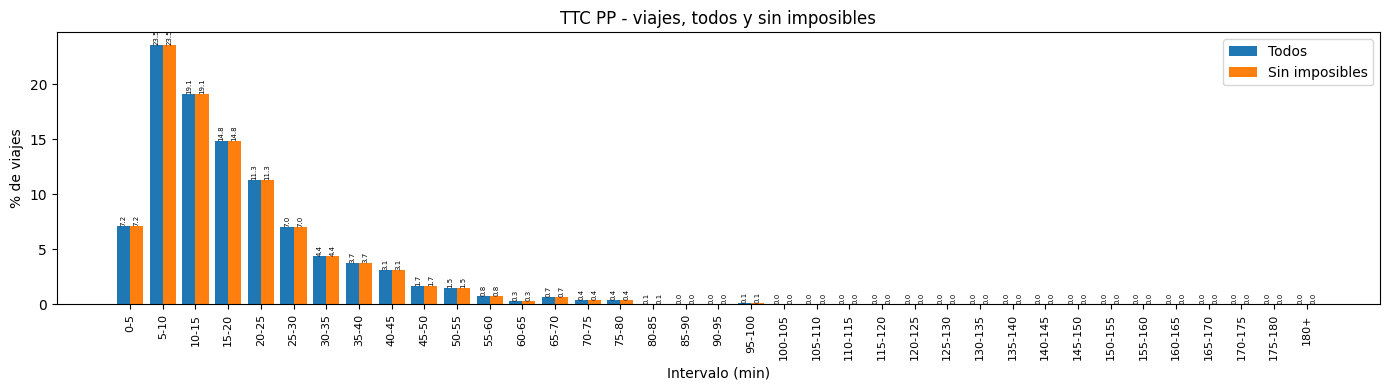

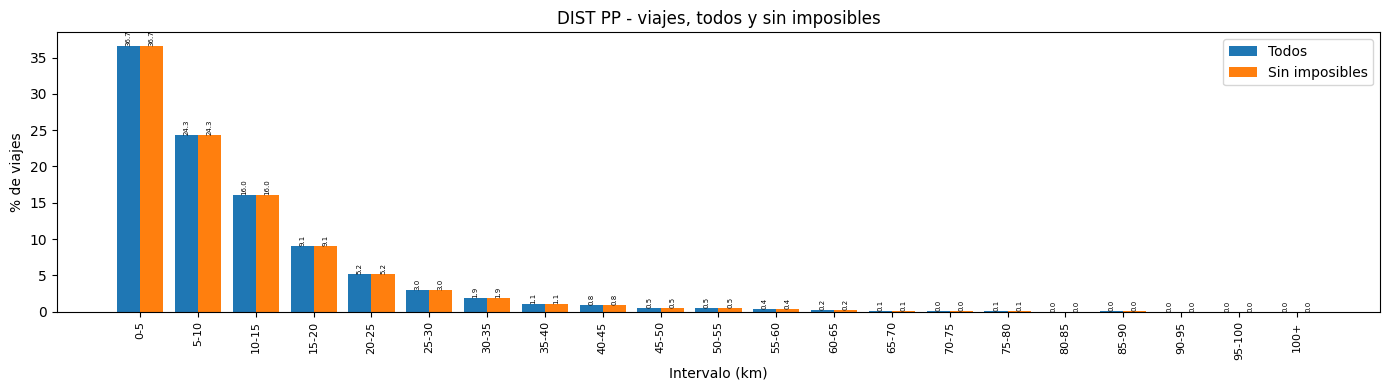

In [49]:
hist_viajes = {version: {} for version in versiones_cruce}
for version, tabla in versiones_cruce.items():
    for p in PERIODOS:
        c = tabla[p]
        for tipo in TIPOS:
            bins, labels, _ = BINS_HIST[tipo]
            intervalos = pd.cut(c[tipo], bins=bins, labels=labels, right=False)
            t = c.groupby(intervalos, observed=False)["Trips"].sum().rename("Viajes").to_frame()
            t["% viajes"] = (t["Viajes"] / t["Viajes"].sum() * 100).round(2)
            hist_viajes[version][f"{tipo}_{p}"] = t

graficar(hist_viajes, "% viajes", "% de viajes", "viajes, todos y sin imposibles")

In [50]:
def pct_viajes(c, condicion):
    return round(c.loc[condicion, "Trips"].sum() / c["Trips"].sum() * 100, 1)


indicadores_viajes = pd.DataFrame([
    {
        "Periodo": p,
        "Viajes incluidos": version,
        "% TTC < 5 min": pct_viajes(c, c["TTC"] < 5),
        "% TTC < 15 min": pct_viajes(c, c["TTC"] < 15),
        "% TTC >= 30 min": pct_viajes(c, c["TTC"] >= 30),
        "% DIST < 5 km": pct_viajes(c, c["DIST"] < 5),
        "% DIST < 10 km": pct_viajes(c, c["DIST"] < 10),
        "Intervalo TTC más frecuente": hist_viajes[version][f"TTC_{p}"]["Viajes"].idxmax(),
        "Intervalo DIST más frecuente": hist_viajes[version][f"DIST_{p}"]["Viajes"].idxmax(),
    }
    for version, tabla in versiones_cruce.items() for p, c in tabla.items()
])

indicadores_viajes.pivot(index="Periodo", columns="Viajes incluidos").reindex(PERIODOS)

% TTC < 5 min       % TTC < 15 min       % TTC >= 30 min  \
Viajes incluidos Sin imposibles Todos Sin imposibles Todos  Sin imposibles   
Periodo                                                                      
AP                          6.5   6.5           45.6  45.6            22.5   
LM                         11.1  11.1           64.9  64.9             8.6   
EA                          7.1   7.1           54.3  54.3            13.0   
PP                          7.1   7.1           49.8  49.8            17.1   

                        % DIST < 5 km       % DIST < 10 km        \
Viajes incluidos Todos Sin imposibles Todos Sin imposibles Todos   
Periodo                                                            
AP                22.5           35.7  35.7           59.4  59.4   
LM                 8.6           44.3  44.3           69.6  69.6   
EA                13.0           38.5  38.5           64.1  64.1   
PP                17.1           36.7  36.7           60.9  60.9   

                 Intervalo TTC más frecuente        \
Viajes incluidos              Sin imposibles Todos   
Periodo                                              
AP                                      5-10  5-10   
LM                                      5-10  5-10   
EA                                      5-10  5-10   
PP                                      5-10  5-10   

                 Intervalo DIST más frecuente        
Viajes incluidos               Sin imposibles Todos  
Periodo                                              
AP                                        0-5   0-5  
LM                                        0-5   0-5  
EA                                        0-5   0-5  
PP                                        0-5   0-5

- Las dos versiones son iguales.
- Los viajes de menos de 5 min son de 6.5 a 11.1 %; antes, sin imposibles, eran de 20 a 28 %.
- El intervalo más frecuente es de 5 a 10 min en TTC y de 0 a 5 km en DIST.

## Mapa de pares con más viajes
- **Grosor:** viajes
- **Color:** velocidad promedio DIST / TTC (rojo es lento, verde es rápido)

Izquierda todos los pares, derecha sin imposibles.

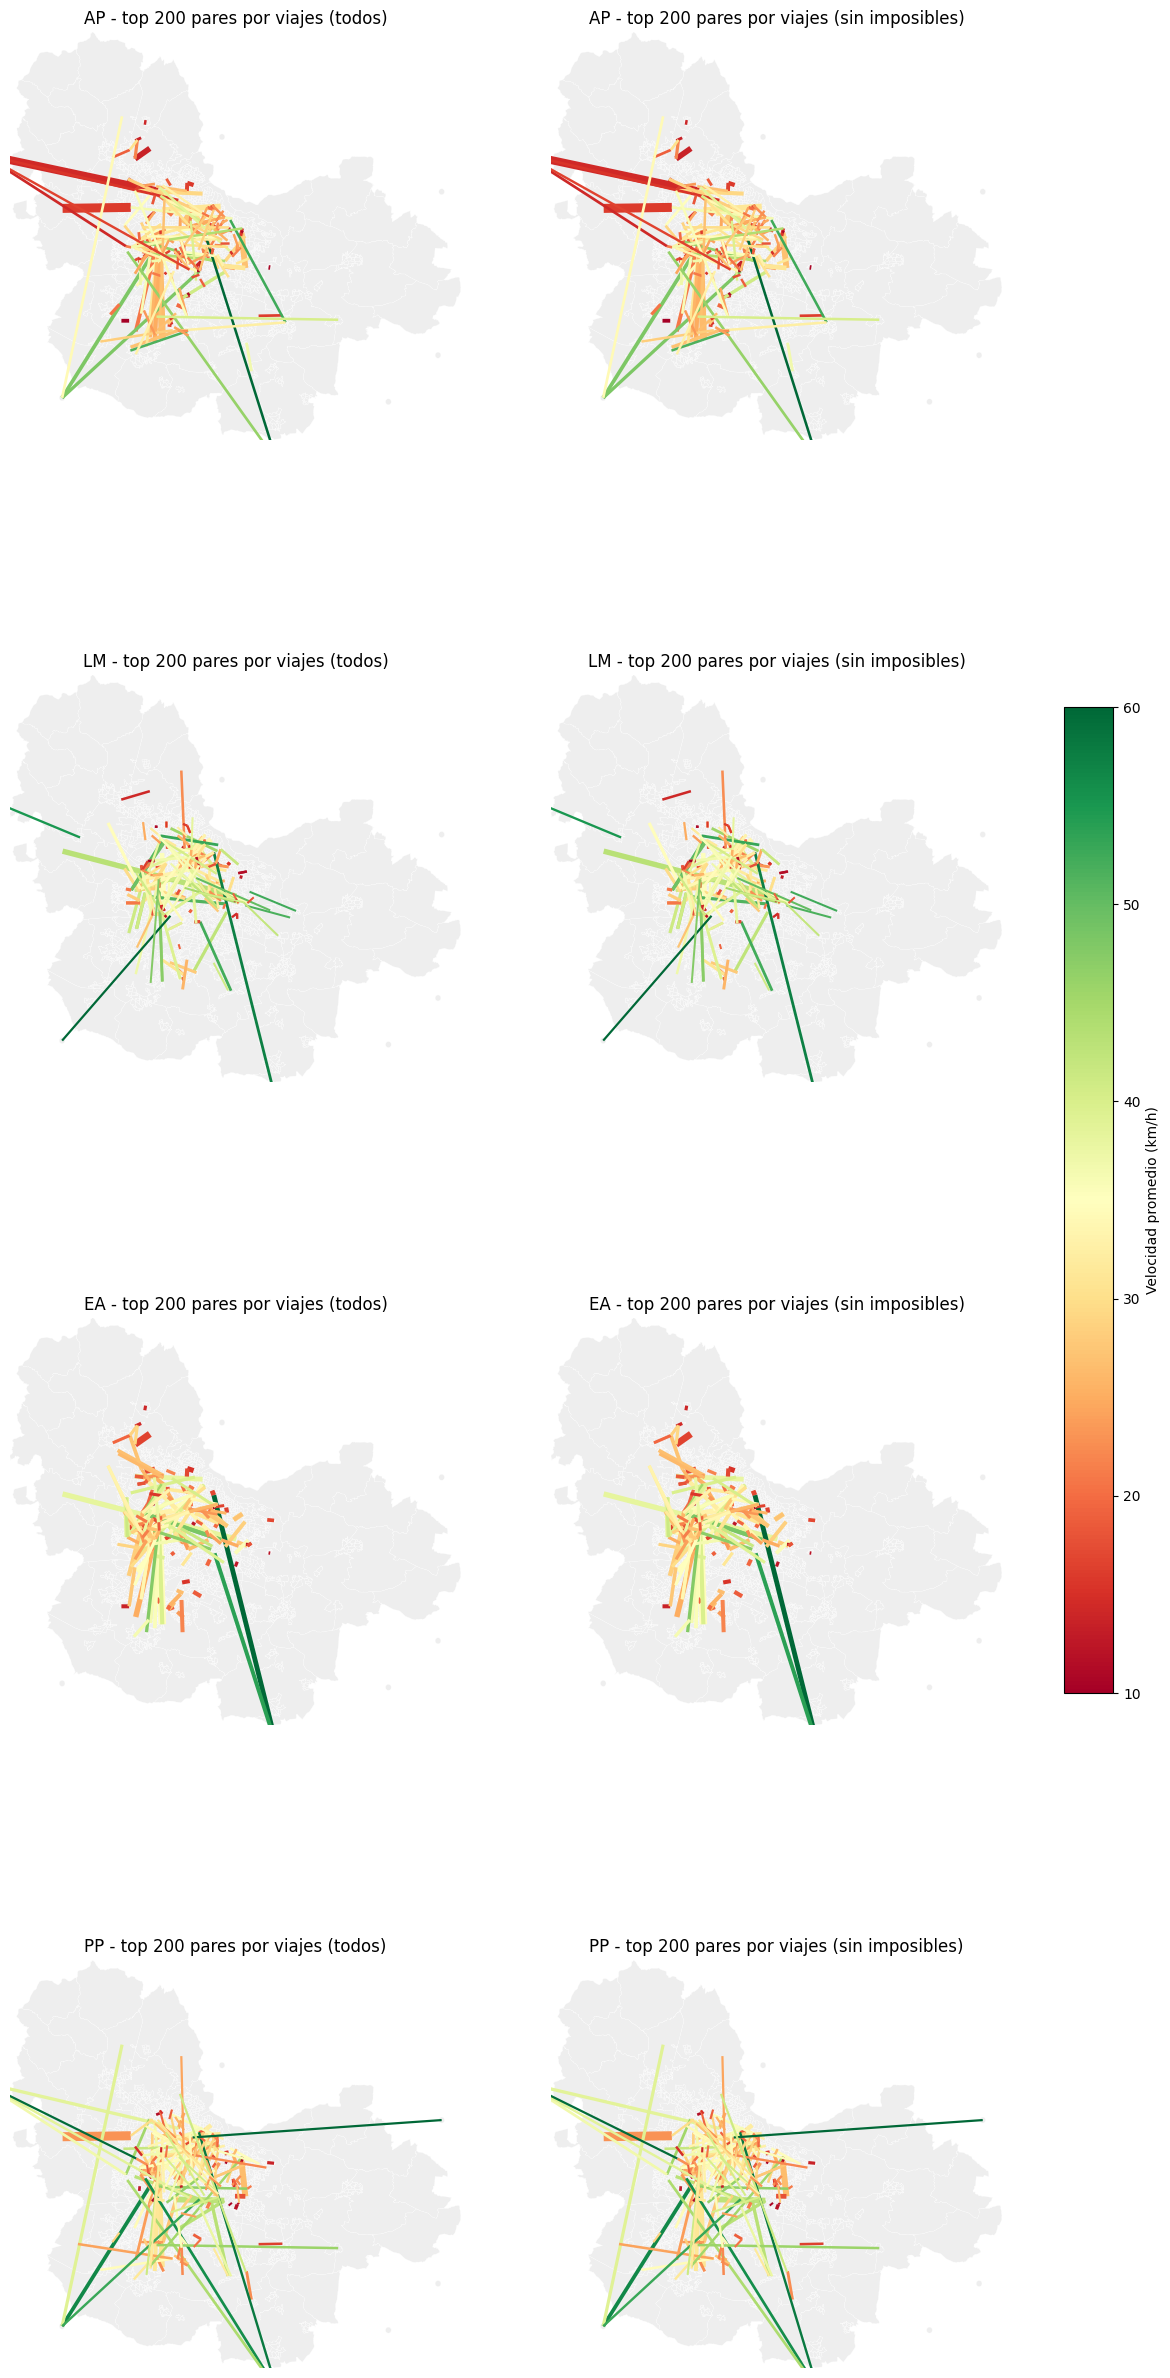

Pares imposibles dentro del top 200 de la versión Todos: {'AP': 0, 'LM': 0, 'EA': 0, 'PP': 0}


In [51]:
mapa_pares = {}
fig, axes = plt.subplots(len(PERIODOS), 2, figsize=(16, 8 * len(PERIODOS)))
for fila, p in enumerate(PERIODOS):
    for col, (version, tabla) in enumerate(versiones_cruce.items()):
        c = tabla[p].nlargest(TOP, "Trips")
        lineas = lineas_de(c)
        mapa_pares[(version, p)] = lineas

        ax = axes[fila, col]
        zonas_geo.plot(ax=ax, color="#eeeeee", edgecolor="white", linewidth=0.2)
        lineas.plot(ax=ax, column="VEL_kmh", cmap="RdYlGn", vmin=VEL_MIN_COLOR, vmax=VEL_MAX_COLOR,
                    linewidth=(0.5 + 6 * c["Trips"] / c["Trips"].max()).values)
        ax.set_xlim(xmin, xmax)
        ax.set_ylim(ymin, ymax)
        ax.set_title(f"{p} - top {TOP} pares por viajes ({version.lower()})")
        ax.set_axis_off()

fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(VEL_MIN_COLOR, VEL_MAX_COLOR), cmap="RdYlGn"),
             ax=axes, shrink=0.4, label="Velocidad promedio (km/h)")
plt.show()

print("Pares imposibles dentro del top", TOP, "de la versión Todos:",
      {p: int(mapa_pares[("Todos", p)]["imposible"].sum()) for p in PERIODOS})

Pares con más viajes y menor velocidad

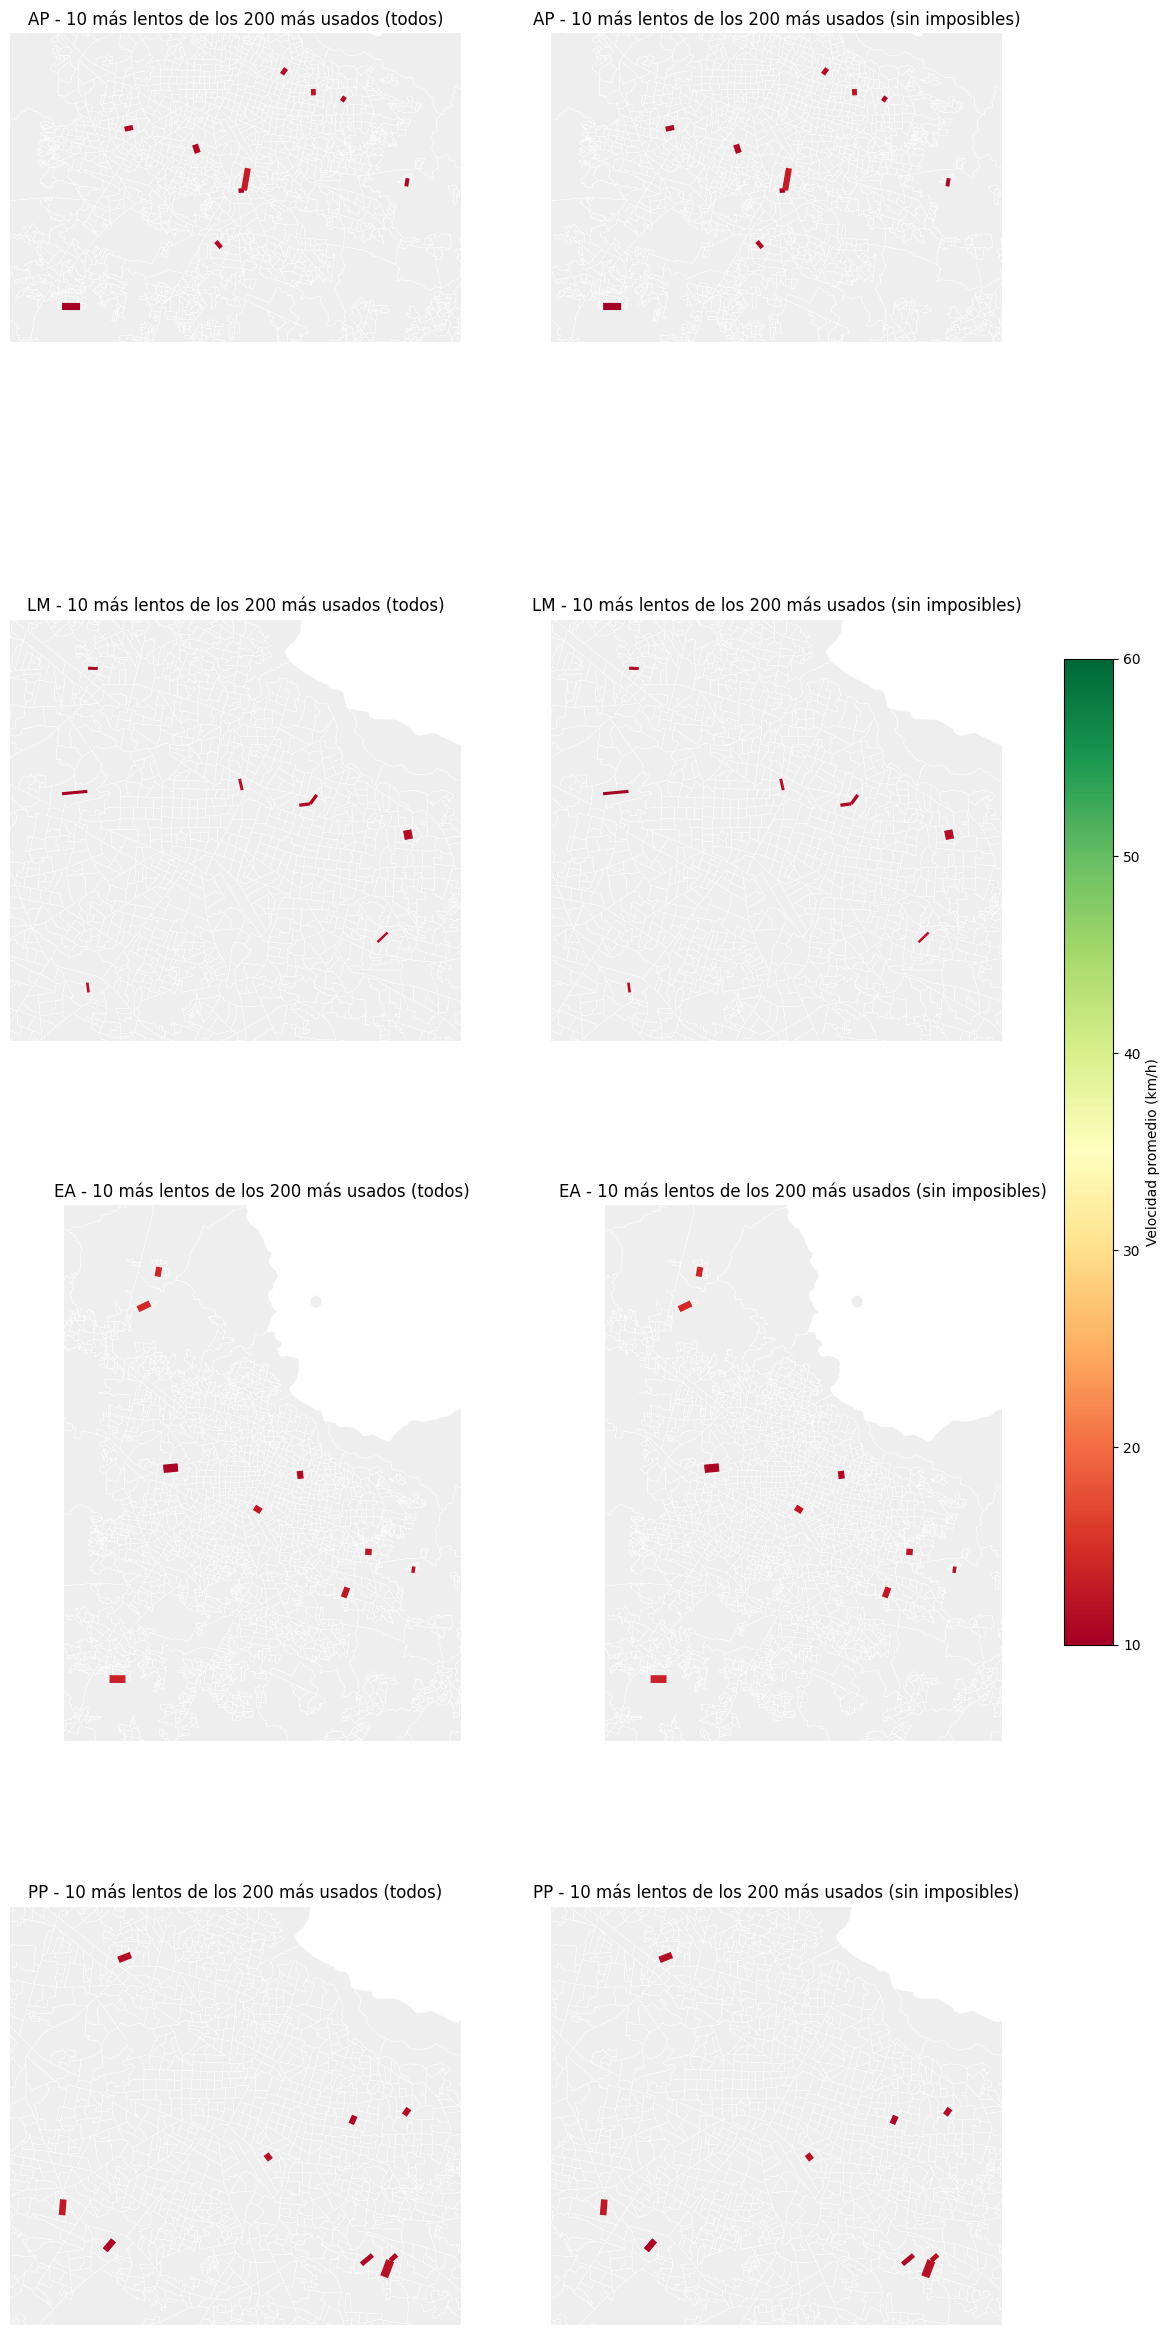

AP | iguales en las dos versiones: True


Todos                                                                 \
  Origin_zona             Mun_origen Destination_zona            Mun_destino   
0        5374   Tlajomulco de Zúñiga             5342   Tlajomulco de Zúñiga   
1        6047  San Pedro Tlaquepaque             6046  San Pedro Tlaquepaque   
2        7021                 Tonalá             7017                 Tonalá   
3        7217                 Tonalá             7215                 Tonalá   
4        8041                Zapopan             8016                Zapopan   
5        6155  San Pedro Tlaquepaque             6159  San Pedro Tlaquepaque   
6         291            Guadalajara              290            Guadalajara   
7          63            Guadalajara               64            Guadalajara   
8         377            Guadalajara              235            Guadalajara   
9        6047  San Pedro Tlaquepaque             6019  San Pedro Tlaquepaque   

                            Sin imposibles                         \
   Trips   TTC DIST VEL_kmh    Origin_zona             Mun_origen   
0  305.9  18.0  2.1     7.0           5374   Tlajomulco de Zúñiga   
1  166.9   3.4  0.6    10.5           6047  San Pedro Tlaquepaque   
2  172.1   2.8  0.5    10.7           7021                 Tonalá   
3  370.6   2.7  0.5    10.7           7217                 Tonalá   
4  196.3   4.5  0.8    10.9           8041                Zapopan   
5  167.3   4.1  0.7    10.9           6155  San Pedro Tlaquepaque   
6  250.4   5.2  1.0    11.1            291            Guadalajara   
7  183.1   4.6  0.9    11.5             63            Guadalajara   
8  183.1   2.8  0.6    12.3            377            Guadalajara   
9  250.4   9.9  2.1    13.0           6047  San Pedro Tlaquepaque   

                                                                     
  Destination_zona            Mun_destino  Trips   TTC DIST VEL_kmh  
0             5342   Tlajomulco de Zúñiga  305.9  18.0  2.1     7.0  
1             6046  San Pedro Tlaquepaque  166.9   3.4  0.6    10.5  
2             7017                 Tonalá  172.1   2.8  0.5    10.7  
3             7215                 Tonalá  370.6   2.7  0.5    10.7  
4             8016                Zapopan  196.3   4.5  0.8    10.9  
5             6159  San Pedro Tlaquepaque  167.3   4.1  0.7    10.9  
6              290            Guadalajara  250.4   5.2  1.0    11.1  
7               64            Guadalajara  183.1   4.6  0.9    11.5  
8              235            Guadalajara  183.1   2.8  0.6    12.3  
9             6019  San Pedro Tlaquepaque  250.4   9.9  2.1    13.0

LM | iguales en las dos versiones: True


Todos                                                                 \
  Origin_zona             Mun_origen Destination_zona            Mun_destino   
0        8137                Zapopan             8033                Zapopan   
1          64            Guadalajara               63            Guadalajara   
2        8059                Zapopan             8409                Zapopan   
3        8409                Zapopan             8059                Zapopan   
4          64            Guadalajara               62            Guadalajara   
5        7017                 Tonalá             7016                 Tonalá   
6        7016                 Tonalá             7017                 Tonalá   
7        6147  San Pedro Tlaquepaque             6099  San Pedro Tlaquepaque   
8          55            Guadalajara               26            Guadalajara   
9        7057                 Tonalá             7043                 Tonalá   

                           Sin imposibles                         \
   Trips  TTC DIST VEL_kmh    Origin_zona             Mun_origen   
0  150.9  7.6  1.3    10.3           8137                Zapopan   
1  170.8  4.0  0.7    10.6             64            Guadalajara   
2  122.1  3.5  0.6    11.0           8059                Zapopan   
3  122.1  3.5  0.6    11.0           8409                Zapopan   
4  170.8  3.6  0.7    11.1             64            Guadalajara   
5  532.3  3.6  0.7    11.5           7017                 Tonalá   
6  612.6  3.6  0.7    11.5           7016                 Tonalá   
7  111.8  2.7  0.5    11.5           6147  San Pedro Tlaquepaque   
8  138.6  3.1  0.6    11.6             55            Guadalajara   
9   98.8  5.8  1.2    11.9           7057                 Tonalá   

                                                                    
  Destination_zona            Mun_destino  Trips  TTC DIST VEL_kmh  
0             8033                Zapopan  150.9  7.6  1.3    10.3  
1               63            Guadalajara  170.8  4.0  0.7    10.6  
2             8409                Zapopan  122.1  3.5  0.6    11.0  
3             8059                Zapopan  122.1  3.5  0.6    11.0  
4               62            Guadalajara  170.8  3.6  0.7    11.1  
5             7016                 Tonalá  532.3  3.6  0.7    11.5  
6             7017                 Tonalá  612.6  3.6  0.7    11.5  
7             6099  San Pedro Tlaquepaque  111.8  2.7  0.5    11.5  
8               26            Guadalajara  138.6  3.1  0.6    11.6  
9             7043                 Tonalá   98.8  5.8  1.2    11.9

EA | iguales en las dos versiones: True


Todos                                                                 \
  Origin_zona             Mun_origen Destination_zona            Mun_destino   
0        8137                Zapopan             8033                Zapopan   
1        8033                Zapopan             8137                Zapopan   
2          62            Guadalajara               64            Guadalajara   
3        7215                 Tonalá             7217                 Tonalá   
4        7050                 Tonalá             7051                 Tonalá   
5         284            Guadalajara              285            Guadalajara   
6        6196  San Pedro Tlaquepaque             6123  San Pedro Tlaquepaque   
7        5342   Tlajomulco de Zúñiga             5374   Tlajomulco de Zúñiga   
8        8520                Zapopan             8526                Zapopan   
9        8506                Zapopan             8508                Zapopan   

                           Sin imposibles                         \
   Trips  TTC DIST VEL_kmh    Origin_zona             Mun_origen   
0  119.4  7.6  1.3    10.3           8137                Zapopan   
1  153.5  8.5  1.5    10.6           8033                Zapopan   
2  144.8  3.6  0.7    11.1             62            Guadalajara   
3  111.6  2.4  0.5    12.1           7215                 Tonalá   
4  111.6  3.0  0.6    12.2           7050                 Tonalá   
5  107.6  3.6  0.7    12.4            284            Guadalajara   
6  103.5  5.4  1.1    12.6           6196  San Pedro Tlaquepaque   
7  141.1  6.8  1.5    13.7           5342   Tlajomulco de Zúñiga   
8  102.9  4.5  1.1    14.0           8520                Zapopan   
9  114.3  6.1  1.5    14.4           8506                Zapopan   

                                                                    
  Destination_zona            Mun_destino  Trips  TTC DIST VEL_kmh  
0             8033                Zapopan  119.4  7.6  1.3    10.3  
1             8137                Zapopan  153.5  8.5  1.5    10.6  
2               64            Guadalajara  144.8  3.6  0.7    11.1  
3             7217                 Tonalá  111.6  2.4  0.5    12.1  
4             7051                 Tonalá  111.6  3.0  0.6    12.2  
5              285            Guadalajara  107.6  3.6  0.7    12.4  
6             6123  San Pedro Tlaquepaque  103.5  5.4  1.1    12.6  
7             5374   Tlajomulco de Zúñiga  141.1  6.8  1.5    13.7  
8             8526                Zapopan  102.9  4.5  1.1    14.0  
9             8508                Zapopan  114.3  6.1  1.5    14.4

PP | iguales en las dos versiones: True


Todos                                                                 \
  Origin_zona             Mun_origen Destination_zona            Mun_destino   
0        6099  San Pedro Tlaquepaque             6146  San Pedro Tlaquepaque   
1        6117  San Pedro Tlaquepaque             6030  San Pedro Tlaquepaque   
2         125            Guadalajara              328            Guadalajara   
3        6146  San Pedro Tlaquepaque             6099  San Pedro Tlaquepaque   
4        7017                 Tonalá             7021                 Tonalá   
5        6123  San Pedro Tlaquepaque             6085  San Pedro Tlaquepaque   
6        8061                Zapopan             8162                Zapopan   
7        6123  San Pedro Tlaquepaque             6196  San Pedro Tlaquepaque   
8         217            Guadalajara              216            Guadalajara   
9        8108                Zapopan             8104                Zapopan   

                           Sin imposibles                         \
   Trips  TTC DIST VEL_kmh    Origin_zona             Mun_origen   
0  217.2  4.5  0.8    10.5           6099  San Pedro Tlaquepaque   
1  158.1  7.6  1.3    10.6           6117  San Pedro Tlaquepaque   
2  207.9  2.7  0.5    10.7            125            Guadalajara   
3  217.2  4.4  0.8    10.9           6146  San Pedro Tlaquepaque   
4  207.9  2.6  0.5    11.3           7017                 Tonalá   
5  158.1  4.6  0.9    11.3           6123  San Pedro Tlaquepaque   
6  237.2  4.4  0.8    11.4           8061                Zapopan   
7  316.3  5.7  1.1    11.8           6123  San Pedro Tlaquepaque   
8  218.5  2.5  0.5    11.9            217            Guadalajara   
9  237.2  4.6  1.0    12.8           8108                Zapopan   

                                                                    
  Destination_zona            Mun_destino  Trips  TTC DIST VEL_kmh  
0             6146  San Pedro Tlaquepaque  217.2  4.5  0.8    10.5  
1             6030  San Pedro Tlaquepaque  158.1  7.6  1.3    10.6  
2              328            Guadalajara  207.9  2.7  0.5    10.7  
3             6099  San Pedro Tlaquepaque  217.2  4.4  0.8    10.9  
4             7021                 Tonalá  207.9  2.6  0.5    11.3  
5             6085  San Pedro Tlaquepaque  158.1  4.6  0.9    11.3  
6             8162                Zapopan  237.2  4.4  0.8    11.4  
7             6196  San Pedro Tlaquepaque  316.3  5.7  1.1    11.8  
8              216            Guadalajara  218.5  2.5  0.5    11.9  
9             8104                Zapopan  237.2  4.6  1.0    12.8

In [52]:
COLUMNAS_LENTOS = ["Origin_zona", "Mun_origen", "Destination_zona", "Mun_destino", "Trips", "TTC", "DIST", "VEL_kmh"]

lentos_usados = {}
fig, axes = plt.subplots(len(PERIODOS), 2, figsize=(16, 8 * len(PERIODOS)))
for fila, p in enumerate(PERIODOS):
    for col, version in enumerate(versiones_cruce):
        lineas = mapa_pares[(version, p)].nsmallest(10, "VEL_kmh").copy()
        lineas["Mun_origen"] = lineas["Origin_zona"].map(municipio)
        lineas["Mun_destino"] = lineas["Destination_zona"].map(municipio)
        lentos_usados[(version, p)] = lineas

        ax = axes[fila, col]
        zonas_geo.plot(ax=ax, color="#eeeeee", edgecolor="white", linewidth=0.3)
        lineas.plot(ax=ax, column="VEL_kmh", cmap="RdYlGn", vmin=VEL_MIN_COLOR, vmax=VEL_MAX_COLOR,
                    linewidth=(1 + 5 * lineas["Trips"] / lineas["Trips"].max()).values)

        x0, y0, x1, y1 = lineas.total_bounds
        margen_x, margen_y = (x1 - x0) * 0.15, (y1 - y0) * 0.15
        ax.set_xlim(x0 - margen_x, x1 + margen_x)
        ax.set_ylim(y0 - margen_y, y1 + margen_y)
        ax.set_title(f"{p} - 10 más lentos de los {TOP} más usados ({version.lower()})")
        ax.set_axis_off()

fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(VEL_MIN_COLOR, VEL_MAX_COLOR), cmap="RdYlGn"),
             ax=axes, shrink=0.4, label="Velocidad promedio (km/h)")
plt.show()

for p in PERIODOS:
    print(p, "| iguales en las dos versiones:",
          lentos_usados[("Todos", p)][COLUMNAS_LENTOS].equals(lentos_usados[("Sin imposibles", p)][COLUMNAS_LENTOS]))
    display(pd.concat({v: lentos_usados[(v, p)][COLUMNAS_LENTOS].reset_index(drop=True) for v in versiones_cruce},
                      axis=1).round(1))

- Ningún par del top 200 es imposible, así que los mapas de las dos versiones son iguales.
- Los más lentos son tramos cortos de 0.5 a 2 km a 7 a 14 km/h. El más lento en AP es de 5374 a 5342 (Tlajomulco), 2.1 km en 18 min (7 km/h).

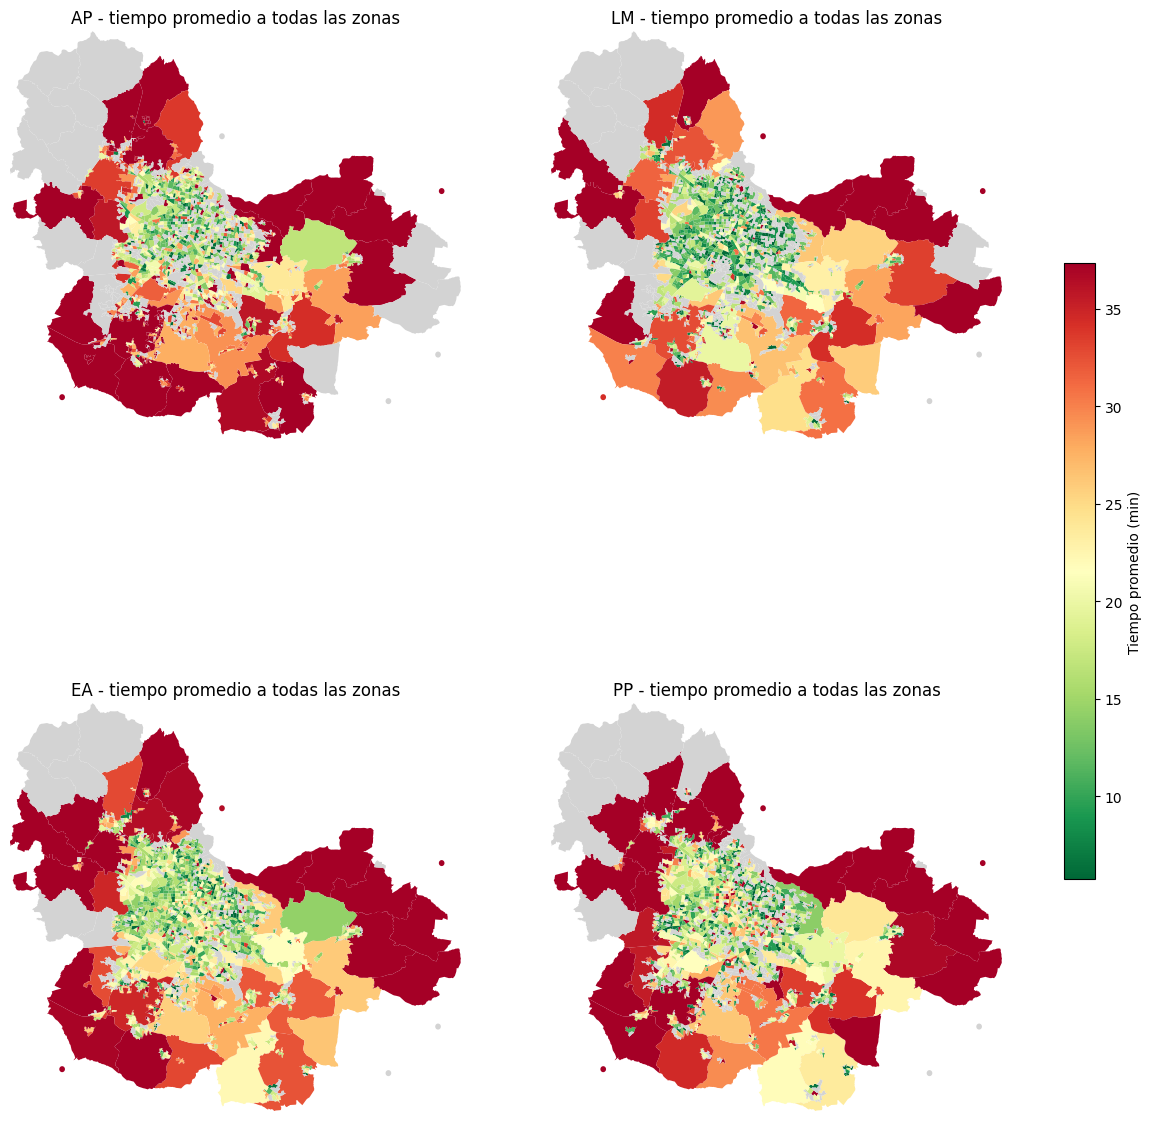

10 zonas mejor conectadas en AP


,AP,LM,EA,PP,Municipio
Zona_visum,,,,,
280,2.6,NaN,NaN,6.1,Guadalajara
347,2.7,23.8,20.4,NaN,Guadalajara
7060,2.9,NaN,NaN,9.5,Tonalá
8050,3.5,15.3,10.9,7.8,Zapopan
3043,3.5,7.8,23.0,10.3,El Salto
319,3.7,3.7,NaN,NaN,Guadalajara
350,4.2,NaN,NaN,NaN,Guadalajara
7170,4.3,NaN,NaN,NaN,Tonalá
161,4.4,14.8,11.7,22.1,Guadalajara


10 zonas peor conectadas en AP


,AP,LM,EA,PP,Municipio
Zona_visum,,,,,
8070,177.0,48.1,8.2,6.7,Zapopan
8346,166.4,NaN,45.9,22.3,Zapopan
8227,95.5,13.7,8.3,NaN,Zapopan
7092,80.9,NaN,5.2,22.3,Tonalá
6185,78.7,10.8,27.9,NaN,San Pedro Tlaquepaque
6180,78.3,27.9,28.1,16.3,San Pedro Tlaquepaque
9900,78.0,81.5,75.2,83.9,Zapotlanejo
5366,69.2,21.4,22.7,9.5,Tlajomulco de Zúñiga
8902,68.8,42.6,58.4,NaN,Zapopan


In [53]:
accesibilidad = {}
for p in PERIODOS:
    od = skims_od[p]
    prom = od[od["con_valor_TTC"]].groupby("Origin")["TTC"].mean()
    prom.index = [zonas[fila] for fila in prom.index]
    accesibilidad[p] = prom

tabla_acc = pd.DataFrame(accesibilidad)
tabla_acc.index.name = "Zona_visum"
tabla_acc["Municipio"] = tabla_acc.index.map(municipio)

escala_acc = pd.concat(accesibilidad.values())
vmin_acc, vmax_acc = escala_acc.quantile(0.05), escala_acc.quantile(0.95)

fig, axes = plt.subplots(2, 2, figsize=(16, 16))
for ax, p in zip(axes.flat, PERIODOS):
    zonas_geo.assign(TTC_prom=zonas_geo["id_visum"].map(accesibilidad[p])).plot(
        ax=ax, column="TTC_prom", cmap="RdYlGn_r", vmin=vmin_acc, vmax=vmax_acc, missing_kwds={"color": "lightgrey"})
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_title(f"{p} - tiempo promedio a todas las zonas")
    ax.set_axis_off()

fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(vmin_acc, vmax_acc), cmap="RdYlGn_r"),
             ax=axes, shrink=0.5, label="Tiempo promedio (min)")
plt.show()

print("10 zonas mejor conectadas en AP")
display(tabla_acc.sort_values("AP").head(10).round(1))
print("10 zonas peor conectadas en AP")
display(tabla_acc.sort_values("AP", ascending=False).head(10).round(1))

### Accesibilidad por zona

- Con esta base el promedio de cada zona solo incluye los destinos con demanda, así que no es comparable con la base anterior.
- Hay zonas con promedios muy distintos entre periodos (por ejemplo 8070 en Zapopan: 177 min en AP y 7 min en PP) porque cambian los destinos que tienen viajes.
- Muchas zonas quedan sin dato en algún periodo porque no tienen viajes en él.

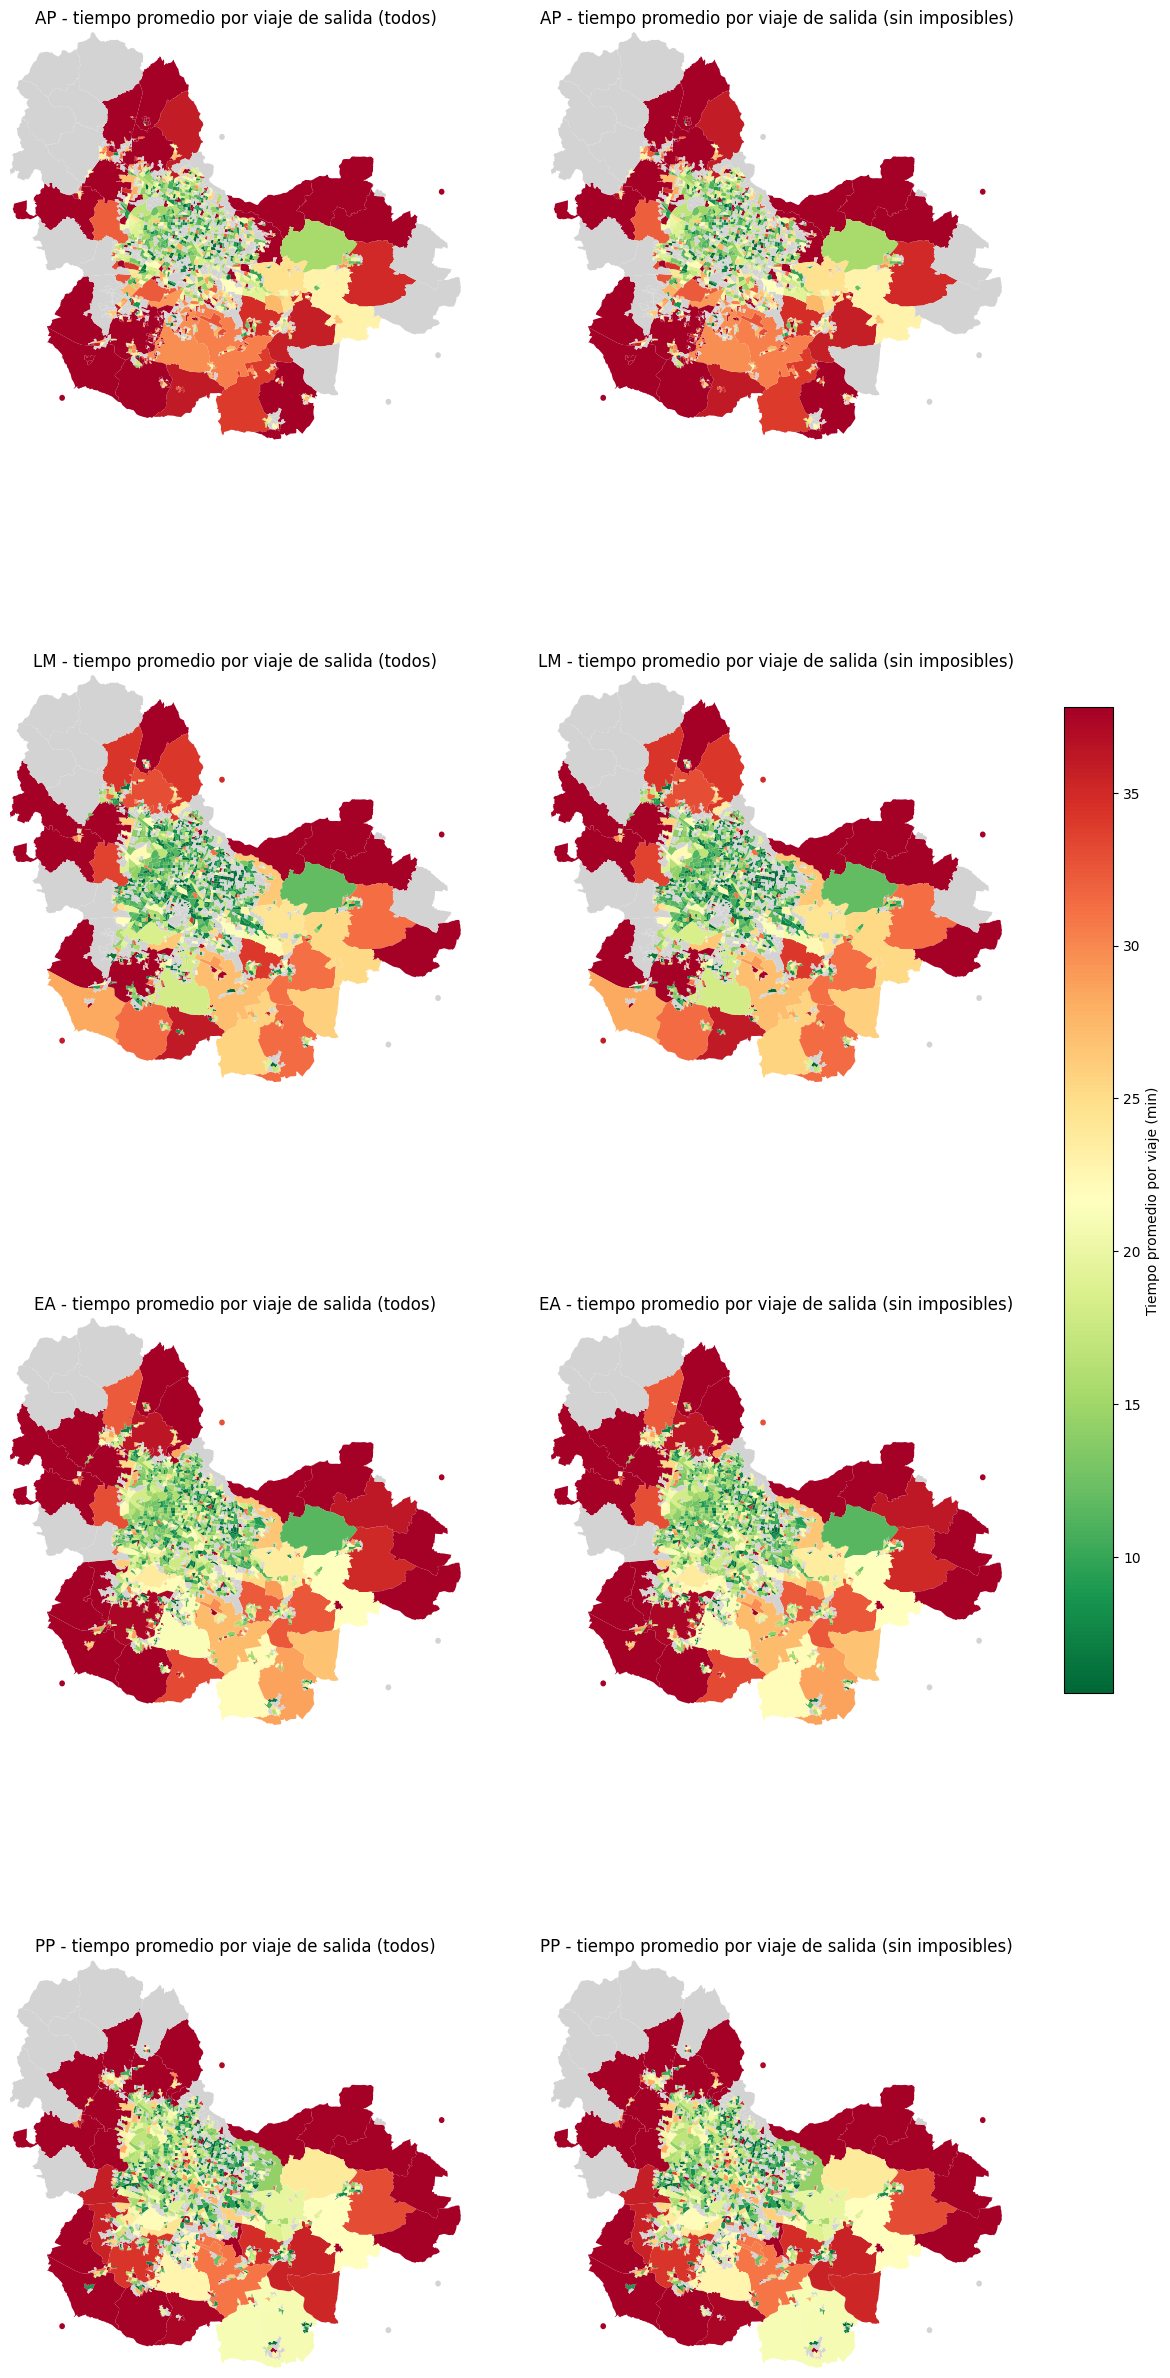

AP: 10 zonas con viajes más lentos sin imposibles (mínimo 100 viajes)


,Periodo,"TTC prom. por viaje, todos (min)","Viajes, todos","TTC prom. por viaje, sin imposibles (min)","Viajes, sin imposibles",Diferencia (min),Municipio
Zona_visum,,,,,,,
8113,AP,120.7,1055.9,120.7,1055.9,0.0,Zapopan
7092,AP,80.9,158.8,80.9,158.8,0.0,Tonalá
8521,AP,73.8,260.3,73.8,260.3,0.0,Zapopan
8227,AP,72.5,196.3,72.5,196.3,0.0,Zapopan
8519,AP,65.2,260.3,65.2,260.3,0.0,Zapopan
8905,AP,62.9,901.5,62.9,901.5,0.0,Zapopan
5359,AP,61.8,103.7,61.8,103.7,0.0,Tlajomulco de Zúñiga
8166,AP,61.1,634.6,61.1,634.6,0.0,Zapopan
5316,AP,60.8,266.9,60.8,266.9,0.0,Tlajomulco de Zúñiga


LM: 10 zonas con viajes más lentos sin imposibles (mínimo 100 viajes)


,Periodo,"TTC prom. por viaje, todos (min)","Viajes, todos","TTC prom. por viaje, sin imposibles (min)","Viajes, sin imposibles",Diferencia (min),Municipio
Zona_visum,,,,,,,
7045,LM,55.2,345.7,55.2,345.7,0.0,Tonalá
10005,LM,47.5,408.3,47.5,408.3,0.0,Acceso_Chapala
10001,LM,47.3,340.3,47.3,340.3,0.0,Acceso_Vallarta
10004,LM,44.7,241.9,44.7,241.9,0.0,Acceso_Zapotlanejo_Cuota
5909,LM,40.9,170.1,40.9,170.1,0.0,Tlajomulco de Zúñiga
8911,LM,38.8,199.6,38.8,199.6,0.0,Zapopan
8047,LM,38.5,110.4,38.5,110.4,0.0,Zapopan
8916,LM,37.8,173.6,37.8,173.6,0.0,Zapopan
5902,LM,36.0,102.2,36.0,102.2,0.0,Tlajomulco de Zúñiga


EA: 10 zonas con viajes más lentos sin imposibles (mínimo 100 viajes)


,Periodo,"TTC prom. por viaje, todos (min)","Viajes, todos","TTC prom. por viaje, sin imposibles (min)","Viajes, sin imposibles",Diferencia (min),Municipio
Zona_visum,,,,,,,
9043,EA,53.3,196.7,53.3,196.7,0.0,Zapotlanejo
10001,EA,51.7,776.2,51.7,776.2,0.0,Acceso_Vallarta
8911,EA,51.0,492.7,51.0,492.7,0.0,Zapopan
10005,EA,47.0,1195.1,47.0,1195.1,0.0,Acceso_Chapala
10004,EA,45.8,426.4,45.8,426.4,0.0,Acceso_Zapotlanejo_Cuota
5900,EA,45.6,140.5,45.6,140.5,0.0,Tlajomulco de Zúñiga
10006,EA,42.4,291.9,42.4,291.9,0.0,Acceso_Lopez_Mateos
5912,EA,39.4,175.2,39.4,175.2,0.0,Tlajomulco de Zúñiga
5286,EA,38.8,145.7,38.8,145.7,0.0,Tlajomulco de Zúñiga


PP: 10 zonas con viajes más lentos sin imposibles (mínimo 100 viajes)


,Periodo,"TTC prom. por viaje, todos (min)","Viajes, todos","TTC prom. por viaje, sin imposibles (min)","Viajes, sin imposibles",Diferencia (min),Municipio
Zona_visum,,,,,,,
10001,PP,67.8,1712.4,67.8,1712.4,0.0,Acceso_Vallarta
10005,PP,67.2,2665.6,67.2,2665.6,0.0,Acceso_Chapala
8317,PP,59.8,237.2,59.8,237.2,0.0,Zapopan
9043,PP,59.8,295.4,59.8,295.4,0.0,Zapotlanejo
8381,PP,59.1,390.5,59.1,390.5,0.0,Zapopan
5900,PP,53.0,331.8,53.0,331.8,0.0,Tlajomulco de Zúñiga
10006,PP,51.5,1684.0,51.5,1684.0,0.0,Acceso_Lopez_Mateos
5084,PP,51.3,110.6,51.3,110.6,0.0,Tlajomulco de Zúñiga
8908,PP,49.4,139.9,49.4,139.9,0.0,Zapopan


Zonas con mayor cambio del tiempo promedio por viaje al quitar los pares imposibles (mínimo 100 viajes)


,Periodo,"TTC prom. por viaje, todos (min)","Viajes, todos","TTC prom. por viaje, sin imposibles (min)","Viajes, sin imposibles",Diferencia (min),Municipio
Zona_visum,,,,,,,
1,AP,15.2,313.6,15.2,313.6,0.0,Guadalajara
2,AP,16.4,937.5,16.4,937.5,0.0,Guadalajara
3,AP,11.1,330.9,11.1,330.9,0.0,Guadalajara
4,AP,10.6,445.6,10.6,445.6,0.0,Guadalajara
6,AP,38.6,943.8,38.6,943.8,0.0,Guadalajara
8,AP,42.6,751.5,42.6,751.5,0.0,Guadalajara
9,AP,10.5,240.4,10.5,240.4,0.0,Guadalajara
11,AP,10.6,747.8,10.6,747.8,0.0,Guadalajara
13,AP,14.1,498.5,14.1,498.5,0.0,Guadalajara


In [54]:
tiempo_viajes = {}
viajes_origen = {}
for version, tabla in versiones_cruce.items():
    for p in PERIODOS:
        c = tabla[p]
        g = c.assign(TTC_x_Trips=c["TTC"] * c["Trips"]).groupby("Origin_zona")[["TTC_x_Trips", "Trips"]].sum()
        tiempo_viajes[(version, p)] = g["TTC_x_Trips"] / g["Trips"]
        viajes_origen[(version, p)] = g["Trips"]

escala_tv = pd.concat(tiempo_viajes.values())
vmin_tv, vmax_tv = escala_tv.quantile(0.05), escala_tv.quantile(0.95)

fig, axes = plt.subplots(len(PERIODOS), 2, figsize=(16, 8 * len(PERIODOS)))
for fila, p in enumerate(PERIODOS):
    for col, version in enumerate(versiones_cruce):
        ax = axes[fila, col]
        zonas_geo.assign(TTC_viaje=zonas_geo["id_visum"].map(tiempo_viajes[(version, p)])).plot(
            ax=ax, column="TTC_viaje", cmap="RdYlGn_r", vmin=vmin_tv, vmax=vmax_tv, missing_kwds={"color": "lightgrey"})
        ax.set_xlim(xmin, xmax)
        ax.set_ylim(ymin, ymax)
        ax.set_title(f"{p} - tiempo promedio por viaje de salida ({version.lower()})")
        ax.set_axis_off()

fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(vmin_tv, vmax_tv), cmap="RdYlGn_r"),
             ax=axes, shrink=0.4, label="Tiempo promedio por viaje (min)")
plt.show()

tiempo_por_viaje = pd.concat([
    pd.DataFrame({
        "Periodo": p,
        "TTC prom. por viaje, todos (min)": tiempo_viajes[("Todos", p)],
        "Viajes, todos": viajes_origen[("Todos", p)],
        "TTC prom. por viaje, sin imposibles (min)": tiempo_viajes[("Sin imposibles", p)],
        "Viajes, sin imposibles": viajes_origen[("Sin imposibles", p)],
    })
    for p in PERIODOS
])
tiempo_por_viaje.index.name = "Zona_visum"
tiempo_por_viaje["Diferencia (min)"] = (tiempo_por_viaje["TTC prom. por viaje, sin imposibles (min)"]
                                        - tiempo_por_viaje["TTC prom. por viaje, todos (min)"])
tiempo_por_viaje["Municipio"] = tiempo_por_viaje.index.map(municipio)

for p in PERIODOS:
    t = tiempo_por_viaje[(tiempo_por_viaje["Periodo"] == p) & (tiempo_por_viaje["Viajes, sin imposibles"] >= MIN_VIAJES)]
    print(f"{p}: 10 zonas con viajes más lentos sin imposibles (mínimo {MIN_VIAJES} viajes)")
    display(t.sort_values("TTC prom. por viaje, sin imposibles (min)", ascending=False).head(10).round(1))

print("Zonas con mayor cambio del tiempo promedio por viaje al quitar los pares imposibles (mínimo", MIN_VIAJES, "viajes)")
display(tiempo_por_viaje[tiempo_por_viaje["Viajes, todos"] >= MIN_VIAJES]
        .sort_values("Diferencia (min)", ascending=False).head(10).round(1))

- Las zonas más lentas por viaje son los accesos carreteros (10001 Vallarta, 10005 Chapala, 10004 y 10006) y zonas de Zapopan y Tlajomulco. La 8113 (Zapopan) llega a 121 min en AP.
- No hay diferencia entre todos y sin imposibles.

## Mapas por tipo de vehículo
Top 50 pares por tipo, sin imposibles.

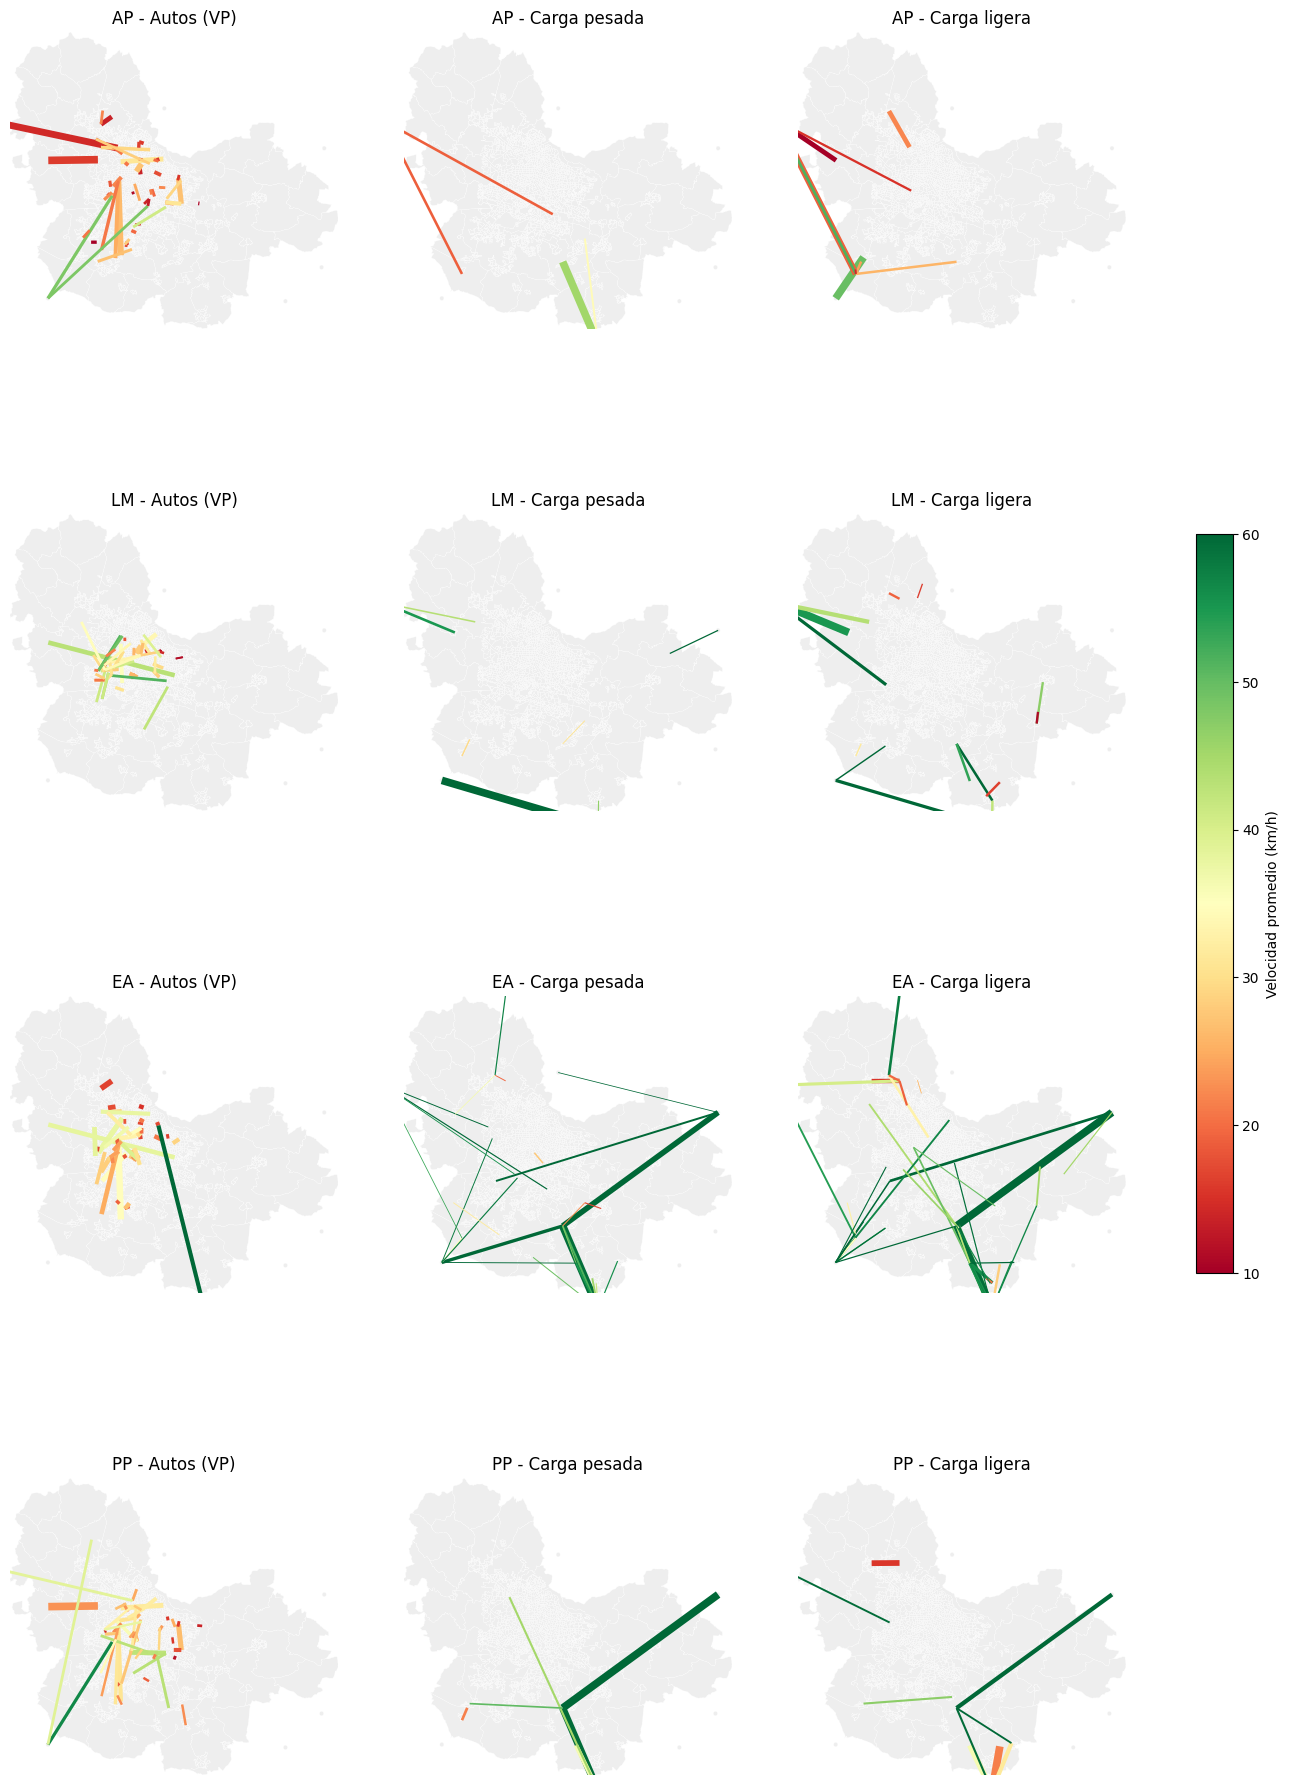

In [55]:
tablas_modo = []
fig, axes = plt.subplots(4, 3, figsize=(18, 24))
for fila, p in enumerate(PERIODOS):
    for col, modo in enumerate(MODOS):
        c = cruces_validos[p]
        c = c[c[modo] > 0].nlargest(TOP_MODO, modo)
        lineas = lineas_de(c)
        tablas_modo.append(c.assign(Periodo=p, Modo=NOMBRES_MODO[modo], Viajes=c[modo]))

        ax = axes[fila, col]
        zonas_geo.plot(ax=ax, color="#eeeeee", edgecolor="white", linewidth=0.2)
        lineas.plot(ax=ax, column="VEL_kmh", cmap="RdYlGn", vmin=VEL_MIN_COLOR, vmax=VEL_MAX_COLOR,
                    linewidth=(0.5 + 5 * c[modo] / c[modo].max()).values)
        ax.set_xlim(xmin, xmax)
        ax.set_ylim(ymin, ymax)
        ax.set_title(f"{p} - {NOMBRES_MODO[modo]}")
        ax.set_axis_off()

fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(VEL_MIN_COLOR, VEL_MAX_COLOR), cmap="RdYlGn"),
             ax=axes, shrink=0.4, label="Velocidad promedio (km/h)")
plt.show()

tabla_modo = pd.concat(tablas_modo)[["Periodo", "Modo", "Origin_zona", "Destination_zona", "Viajes", "TTC", "DIST", "VEL_kmh"]].round(2)

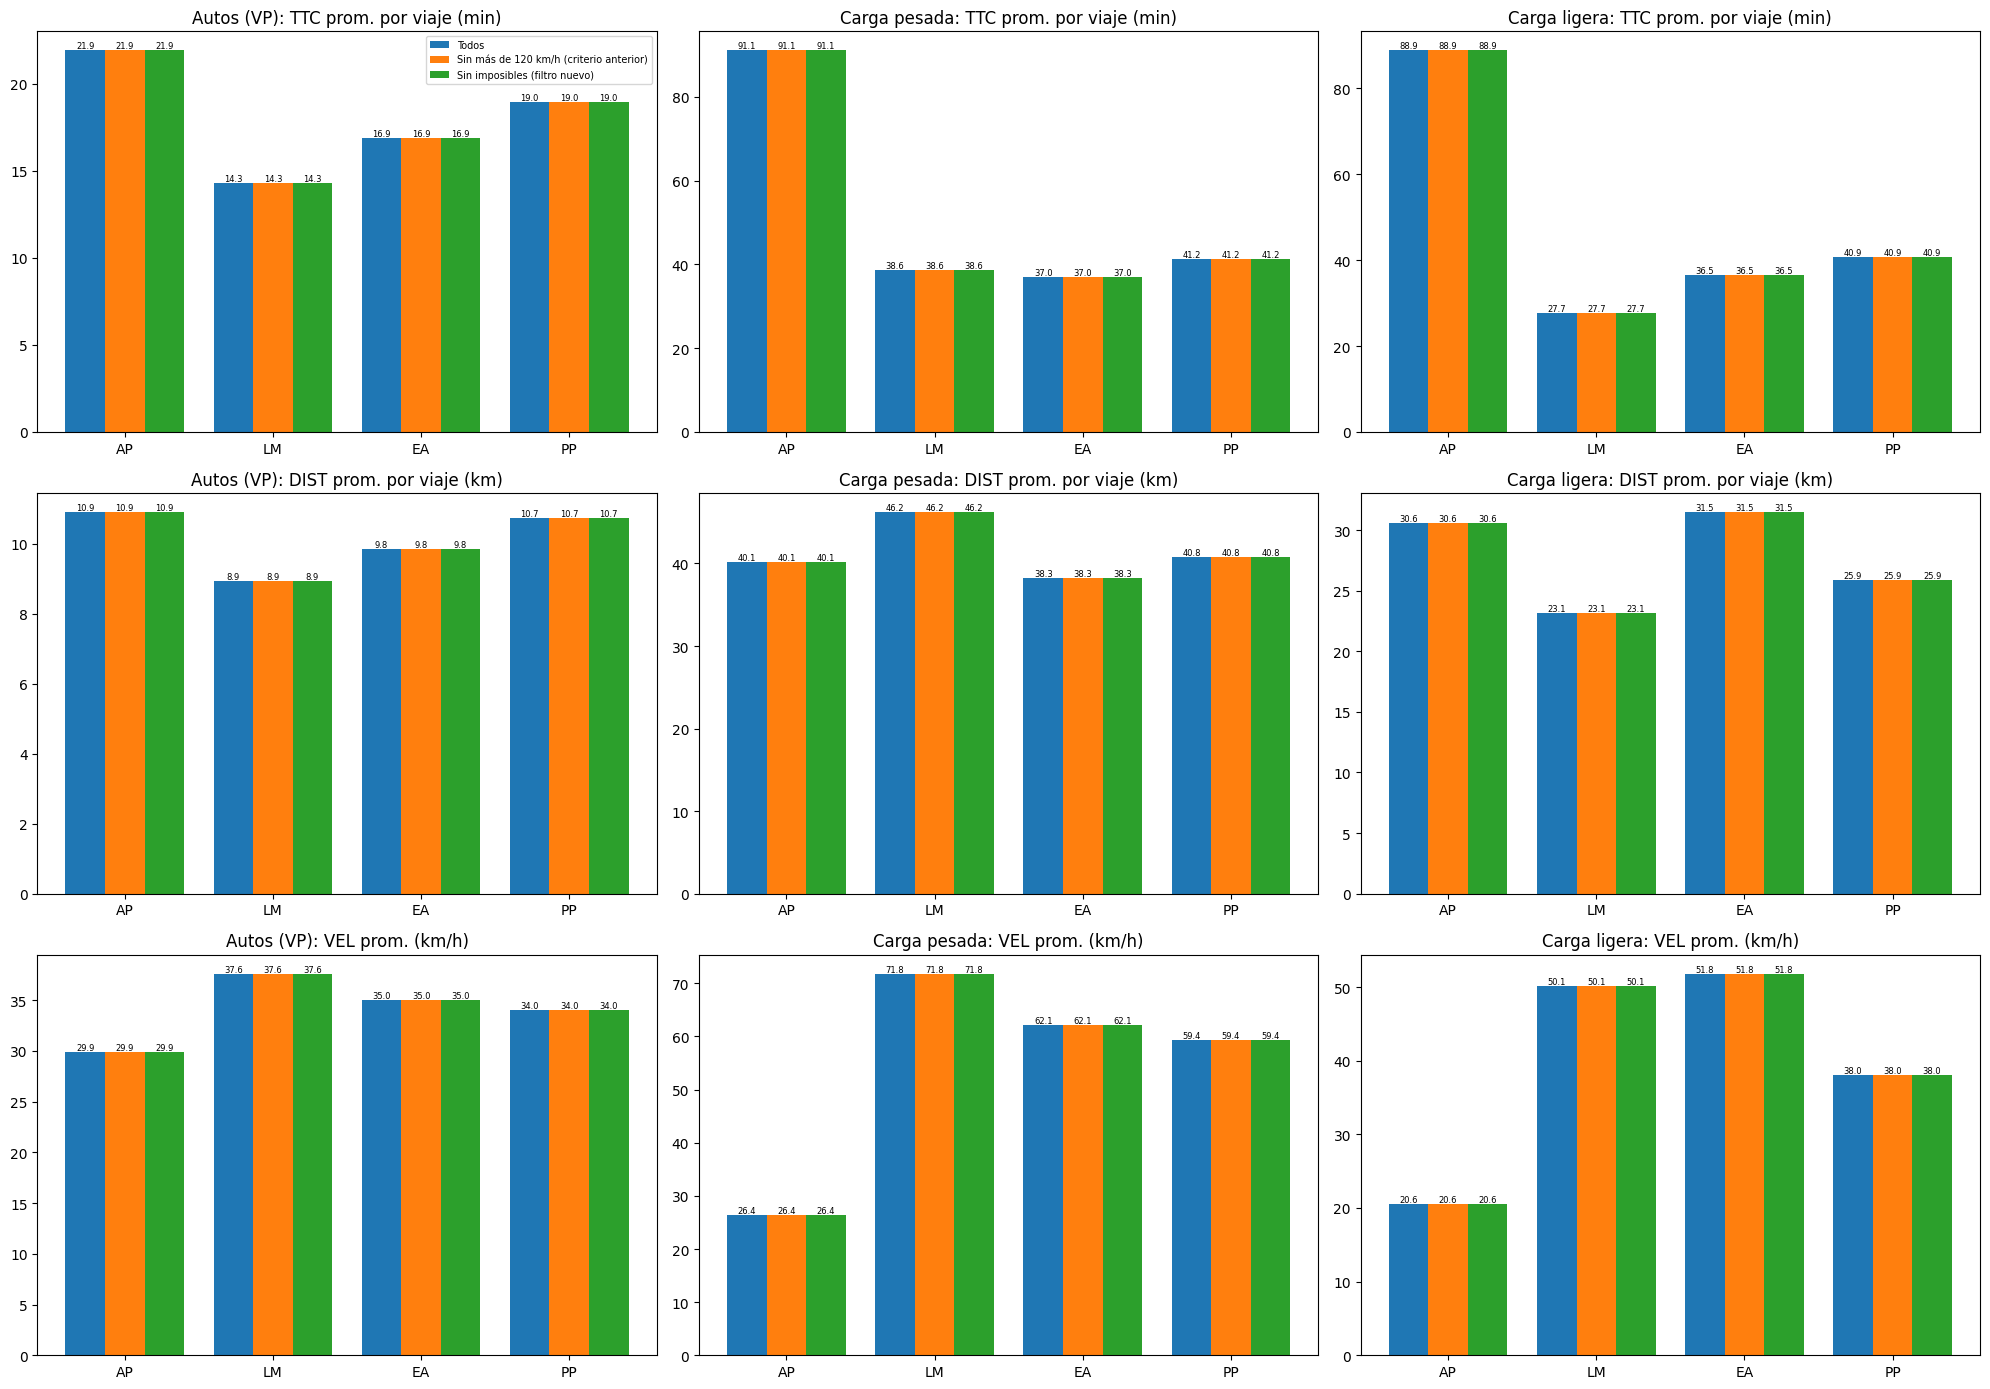

In [56]:
comparativa_modo = pd.DataFrame([
    {"Periodo": p, "Modo": NOMBRES_MODO[modo], "Versión": version, **promedios_por_viaje(tabla[p], modo)}
    for p in PERIODOS for modo in MODOS for version, tabla in versiones_comparativa.items()
])

fig, axes = plt.subplots(3, len(MODOS), figsize=(20, 14))
for col, modo in enumerate(NOMBRES_MODO.values()):
    for fila, metrica in enumerate(metricas[1:]):
        ax = axes[fila, col]
        for k, version in enumerate(versiones_comparativa):
            t = comparativa_modo[(comparativa_modo["Modo"] == modo) & (comparativa_modo["Versión"] == version)] \
                .set_index("Periodo").reindex(PERIODOS)
            barras = ax.bar(np.arange(len(PERIODOS)) + (k - 1) * ancho, t[metrica], width=ancho, label=version)
            ax.bar_label(barras, fmt="%.1f", fontsize=6)
        ax.set_xticks(np.arange(len(PERIODOS)), PERIODOS)
        ax.set_title(f"{modo}: {metrica}")
axes[0, 0].legend(fontsize=7)
plt.tight_layout()
plt.show()

- Autos: 21.9 min por viaje en AP y 14.3 min en LM.
- Carga: casi no queda. De unos 1,300 a 3,000 viajes de carga por periodo, solo de 29 a 122 caen en pares con ruta; el resto queda en pares sin ruta o intrazonales, sobre todo con accesos carreteros. Los promedios de carga son poco confiables.

## Mapas HTML
Se guardan en resultados_filtro_2\mapas_html con un index_filtro_2.html.

In [57]:
mapas_html = []   # (archivo, título, descripción) para el índice


def mapa_base(datos_4326):
    """Mapa sin calles, con las zonas en gris de fondo y acercamiento inicial a datos_4326."""
    mapa = folium.Map(tiles=None, control_scale=True)
    mapa.get_root().header.add_child(folium.Element("<style>.leaflet-container {background: #ffffff;}</style>"))
    folium.GeoJson(
        zonas_4326, name="Zonas", control=False,
        style_function=lambda f: {"fillColor": "#d9d9d9", "color": "#ffffff", "weight": 0.5, "fillOpacity": 1},
        tooltip=folium.GeoJsonTooltip(["id_visum", "nombre_mun"], aliases=["Zona", "Municipio"]),
    ).add_to(mapa)
    x0, y0, x1, y1 = datos_4326.total_bounds
    mapa.fit_bounds([[y0, x0], [y1, x1]])
    return mapa


def para_tooltip(gdf, columnas):
    """Redondea y deja como texto las columnas del tooltip (los valores faltantes se muestran como 'sin dato')."""
    gdf = gdf.copy()
    for col in columnas:
        if pd.api.types.is_numeric_dtype(gdf[col]) and not pd.api.types.is_integer_dtype(gdf[col]):
            gdf[col] = gdf[col].round(2)
        gdf[col] = gdf[col].astype(object).where(gdf[col].notna(), "sin dato").astype(str)
    return gdf


def agregar_lineas(capa, lineas_4326, campos, alias, color, flechas):
    folium.GeoJson(
        para_tooltip(lineas_4326[campos + ["geometry"]], campos),
        style_function=lambda f: {"color": color, "weight": 2},
        tooltip=folium.GeoJsonTooltip(campos, aliases=alias),
    ).add_to(capa)
    if flechas:
        for geom in lineas_4326.geometry:
            linea = folium.PolyLine([(y, x) for x, y in geom.coords], weight=0, opacity=0).add_to(capa)
            PolyLineTextPath(linea, "►", center=True, offset=6, attributes={"fill": color, "font-size": "16"}).add_to(capa)


def guardar_mapa(mapa, archivo, titulo, descripcion):
    archivo = archivo.replace(".html", f"{SUFIJO}.html")
    ruta = os.path.join(R_MAPAS, archivo)
    mapa.save(ruta)
    mapas_html.append((archivo, titulo, descripcion))
    print("Guardado en", ruta)


CAMPOS_PAR = ["Zona_origen", "Mun_origen", "Zona_destino", "Mun_destino", "Viajes", "TTC", "DIST", "VEL_kmh"]
ALIAS_PAR = ["Zona origen", "Municipio origen", "Zona destino", "Municipio destino", "Viajes", "TTC (min)",
             "DIST (km)", "Velocidad (km/h)"]

In [58]:
# Pares de 5 a 20 km/h, con flecha de origen a destino
for p in con_pares:
    l = lentos[lentos["Periodo"] == p].merge(
        cruces_todos[p][["Origin_zona", "Destination_zona", "Trips"]],
        left_on=["Zona_origen", "Zona_destino"], right_on=["Origin_zona", "Destination_zona"], how="left")
    l["Viajes"] = l["Trips"].fillna(0)
    l["Mun_origen"] = l["Zona_origen"].map(municipio)
    l["Mun_destino"] = l["Zona_destino"].map(municipio)
    lineas = lineas_de(l, "Zona_origen", "Zona_destino").to_crs(4326)

    mapa = mapa_base(lineas)
    agregar_lineas(mapa, lineas, CAMPOS_PAR, ALIAS_PAR, "red", flechas=True)
    guardar_mapa(mapa, f"pares_5_20_kmh_{p}.html", f"Pares de 5 a 20 km/h, {p}",
                 f"{len(lineas)} pares válidos con velocidad de {VEL_MIN} a {VEL_LENTO} km/h; "
                 f"{int((l['Viajes'] > 0).sum())} con viajes")

print("Periodos sin pares de 5 a 20 km/h:", [p for p in PERIODOS if p not in con_pares])

Guardado en C:\proyectos\red-vial-guadalajara\skim_matrices\resultados_filtro_2\mapas_html\pares_5_20_kmh_AP_filtro_2.html
Guardado en C:\proyectos\red-vial-guadalajara\skim_matrices\resultados_filtro_2\mapas_html\pares_5_20_kmh_LM_filtro_2.html
Guardado en C:\proyectos\red-vial-guadalajara\skim_matrices\resultados_filtro_2\mapas_html\pares_5_20_kmh_EA_filtro_2.html
Guardado en C:\proyectos\red-vial-guadalajara\skim_matrices\resultados_filtro_2\mapas_html\pares_5_20_kmh_PP_filtro_2.html
Periodos sin pares de 5 a 20 km/h: []


In [59]:
# Zonas con viajes afectados por pares imposibles y pares imposibles con viajes, una capa por periodo
CAMPOS_ZONA_IMP = ["Zona", "Municipio", "Viajes_origen", "Viajes_destino", "Pares", "TTC_mediano", "DIST_mediano",
                   "VEL_mediana"]
ALIAS_ZONA_IMP = ["Zona", "Municipio", "Viajes afectados como origen", "Viajes afectados como destino",
                  "Pares imposibles con viajes", "TTC mediano (min)", "DIST mediano (km)", "Velocidad mediana (km/h)"]

if pares_imposibles_con_viajes.empty:
    print("No hay pares imposibles con viajes; no se genera el mapa de zonas afectadas")
else:
    ext_imp = pd.concat([
        pares_imposibles_con_viajes.assign(Zona=pares_imposibles_con_viajes["Zona_origen"], Viajes_origen=pares_imposibles_con_viajes["Trips"], Viajes_destino=0.0),
        pares_imposibles_con_viajes.assign(Zona=pares_imposibles_con_viajes["Zona_destino"], Viajes_origen=0.0, Viajes_destino=pares_imposibles_con_viajes["Trips"]),
    ])
    zona_imp = ext_imp.groupby(["Periodo", "Zona"]).agg(
        Viajes_origen=("Viajes_origen", "sum"), Viajes_destino=("Viajes_destino", "sum"), Pares=("Trips", "size"),
        TTC_mediano=("TTC", "median"), DIST_mediano=("DIST", "median"), VEL_mediana=("VEL_kmh", "median"),
    ).reset_index()
    zona_imp["Municipio"] = zona_imp["Zona"].map(municipio)
    zona_imp["Viajes"] = zona_imp["Viajes_origen"] + zona_imp["Viajes_destino"]

    escala_imp = LinearColormap(["#fee5d9", "#fb6a4a", "#a50f15"], vmin=0, vmax=float(zona_imp["Viajes"].quantile(0.95)),
                                caption="Viajes en pares imposibles (origen + destino)")
    geo_imp = zonas_4326.merge(zona_imp, left_on="id_visum", right_on="Zona")
    mapa = mapa_base(geo_imp)
    for k, p in enumerate(PERIODOS):
        capa = folium.FeatureGroup(name=f"{p}: {int((zona_imp['Periodo'] == p).sum())} zonas", overlay=False, show=k == 0)
        zp = geo_imp[geo_imp["Periodo"] == p]
        folium.GeoJson(
            para_tooltip(zp[CAMPOS_ZONA_IMP + ["Viajes", "geometry"]], CAMPOS_ZONA_IMP),
            style_function=lambda f: {"fillColor": escala_imp(min(f["properties"]["Viajes"], escala_imp.vmax)),
                                      "color": "#444444", "weight": 0.5, "fillOpacity": 0.85},
            tooltip=folium.GeoJsonTooltip(CAMPOS_ZONA_IMP, aliases=ALIAS_ZONA_IMP),
        ).add_to(capa)
        pp = pares_imposibles_con_viajes[pares_imposibles_con_viajes["Periodo"] == p].assign(
            Viajes=lambda x: x["Trips"])
        agregar_lineas(capa, lineas_de(pp, "Zona_origen", "Zona_destino").to_crs(4326),
                       CAMPOS_PAR + ["Reglas"], ALIAS_PAR + ["Reglas"], "#08306b", flechas=False)
        capa.add_to(mapa)
    escala_imp.add_to(mapa)
    folium.LayerControl(collapsed=False).add_to(mapa)
    guardar_mapa(mapa, "zonas_afectadas_imposibles.html", "Zonas con viajes afectados por pares imposibles",
                 "Una capa por periodo; zonas coloreadas por viajes afectados y líneas de los pares imposibles con viajes")

No hay pares imposibles con viajes; no se genera el mapa de zonas afectadas


In [60]:
# Zonas sin viajes, una capa por periodo y una de zonas sin viajes en ningún periodo
CAMPOS_SIN = ["Zona", "Municipio", "Viajes", "Viajes_4_periodos", "TTC_prom", "DIST_prom", "VEL_prom"]
ALIAS_SIN = ["Zona", "Municipio", "Viajes en el periodo", "Viajes en los 4 periodos", "TTC prom. a las demás zonas (min)",
             "DIST prom. a las demás zonas (km)", "Velocidad prom. (km/h)"]

prom_valido = {}
for p in PERIODOS:
    od = skims_od[p]
    g = od[od["valido"]].groupby("Origin")[["TTC", "DIST"]].mean()
    g.index = [zonas[fila] for fila in g.index]
    prom_valido[p] = g
prom_valido["Ningún periodo"] = pd.concat(prom_valido.values()).groupby(level=0).mean()

geo_sin = zonas_4326.rename(columns={"id_visum": "Zona", "nombre_mun": "Municipio"})
mapa = mapa_base(zonas_4326[zonas_4326["id_visum"].isin(zonas_sin_viajes.index)])
for k, (capa_nombre, ids) in enumerate(
        [(p, sin_viajes.index[sin_viajes[p]]) for p in PERIODOS] + [("Ningún periodo", nunca)]):
    g = geo_sin[geo_sin["Zona"].isin(ids)].copy()
    g["Viajes"] = 0.0 if capa_nombre == "Ningún periodo" else g["Zona"].map(viajes_zona[capa_nombre])
    g["Viajes_4_periodos"] = g["Zona"].map(viajes_zona[PERIODOS].sum(axis=1))
    g["TTC_prom"] = g["Zona"].map(prom_valido[capa_nombre]["TTC"])
    g["DIST_prom"] = g["Zona"].map(prom_valido[capa_nombre]["DIST"])
    g["VEL_prom"] = g["DIST_prom"] / (g["TTC_prom"] / 60)
    capa = folium.FeatureGroup(name=f"{capa_nombre}: {len(g)} zonas sin viajes", overlay=False, show=k == 0)
    folium.GeoJson(
        para_tooltip(g[CAMPOS_SIN + ["geometry"]], CAMPOS_SIN),
        style_function=lambda f, color=("#a63603" if capa_nombre == "Ningún periodo" else "#fd8d3c"):
            {"fillColor": color, "color": "#444444", "weight": 0.5, "fillOpacity": 0.85},
        tooltip=folium.GeoJsonTooltip(CAMPOS_SIN, aliases=ALIAS_SIN),
    ).add_to(capa)
    capa.add_to(mapa)
folium.LayerControl(collapsed=False).add_to(mapa)
guardar_mapa(mapa, "zonas_sin_viajes.html", "Zonas sin viajes",
             "Zonas sin viajes como origen ni como destino; una capa por periodo y una de zonas sin viajes en ningún periodo")

Guardado en C:\proyectos\red-vial-guadalajara\skim_matrices\resultados_filtro_2\mapas_html\zonas_sin_viajes_filtro_2.html


In [61]:
enlaces = "\n".join(
    f'    <li><a href="{archivo}">{titulo}</a><br><span>{descripcion}</span></li>' for archivo, titulo, descripcion in mapas_html
)
indice = f"""<!doctype html>
<html lang="es">
<head>
  <meta charset="utf-8">
  <title>Mapas de skims (filtro 2)</title>
  <style>
    body {{font-family: Arial, sans-serif; margin: 32px; max-width: 900px;}}
    li {{margin-bottom: 14px;}}
    span {{color: #555555; font-size: 0.9em;}}
  </style>
</head>
<body>
  <h1>Mapas de skims de transporte privado</h1>
  <p>Mapas interactivos del análisis de skims con filtro de pares imposibles, base de skims del 27/10/26.</p>
  <ul>
{enlaces}
  </ul>
</body>
</html>
"""
ruta_indice = os.path.join(R_MAPAS, f"index{SUFIJO}.html")
with open(ruta_indice, "w", encoding="utf-8") as f:
    f.write(indice)
print("Guardado en", ruta_indice)

Guardado en C:\proyectos\red-vial-guadalajara\skim_matrices\resultados_filtro_2\mapas_html\index_filtro_2.html


## Exportar tablas resumen

In [62]:
desconectadas = sorted({zonas[f] for f in todas_inalcanzables | todas_aisladas})

ruta_excel = os.path.join(R_EXCEL, f"resumen_skims{SUFIJO}.xlsx")
with pd.ExcelWriter(ruta_excel) as xls:
    # Skims por pares
    resumen_pares.to_excel(xls, sheet_name="pares", index=False)
    pd.DataFrame({"Zona_visum": desconectadas}).to_excel(xls, sheet_name="zonas_desconectadas", index=False)
    estadisticos.to_excel(xls, sheet_name="estadisticos")
    pares_umbral.to_excel(xls, sheet_name="umbrales", index=False)
    velocidades.to_excel(xls, sheet_name="velocidades", index=False)
    rangos_vel.to_excel(xls, sheet_name="rangos_vel")
    rangos_vel_pct.to_excel(xls, sheet_name="rangos_vel_pct")
    lentos.to_excel(xls, sheet_name="pares_5_20_kmh", index=False)
    pd.concat(hist_pares, names=["Matriz", "Intervalo"]).to_excel(xls, sheet_name="hist_pares")

    # Demanda, cruce y cotejo
    viajes_modo.to_excel(xls, sheet_name="demanda_modo", index=False)
    totales.to_excel(xls, sheet_name="totales_viajes")
    cruce_resumen.to_excel(xls, sheet_name="cruce_resumen", index=False)
    cotejo_od.to_excel(xls, sheet_name="cotejo_od", index=False)
    zonas_sin_viajes.to_excel(xls, sheet_name="zonas_sin_viajes")

    # Imposibles (el detalle está en velocidades_imposibles.xlsx)
    sensibilidad_umbrales.to_excel(xls, sheet_name="sensibilidad_umbrales", index=False)

    # Resultados por viaje: todos, criterio anterior y sin imposibles
    comparativa_viajes.to_excel(xls, sheet_name="comparativa_viajes", index=False)
    comparativa_modo.to_excel(xls, sheet_name="comparativa_modo", index=False)
    pd.concat({(v, n): t for v, d in hist_viajes.items() for n, t in d.items()},
              names=["Version", "Matriz", "Intervalo"]).to_excel(xls, sheet_name="hist_viajes")
    pd.concat([l.drop(columns="geometry").assign(Periodo=p, Version=v) for (v, p), l in mapa_pares.items()]) \
        [["Version", "Periodo", "Origin_zona", "Destination_zona", "Trips"] + MODOS + ["TTC", "DIST", "VEL_kmh", "Categoria"]] \
        .to_excel(xls, sheet_name="top200_pares", index=False)
    pd.concat([l.drop(columns="geometry").assign(Periodo=p, Version=v) for (v, p), l in lentos_usados.items()]) \
        [["Version", "Periodo"] + COLUMNAS_LENTOS].to_excel(xls, sheet_name="lentos_mas_usados", index=False)
    tabla_acc.to_excel(xls, sheet_name="accesibilidad")
    tiempo_por_viaje.to_excel(xls, sheet_name="tiempo_por_viaje_origen")
    tabla_modo.to_excel(xls, sheet_name="top_pares_modo", index=False)

print("Guardado en", ruta_excel)

Guardado en C:\proyectos\red-vial-guadalajara\skim_matrices\resultados_filtro_2\excel\resumen_skims_filtro_2.xlsx


## Conclusiones
- Las skims están bien formadas (2,105 zonas), pero solo tienen ruta en los pares con demanda (0.09 a 0.28 % de la skim). El resto vale 999999.
- No hay ningún par imposible en ningún periodo; los sospechosos son de 60 a 133 pares por periodo con menos de 1 % de los viajes.
- Los viajes son más lentos que con la base anterior: de 29.9 km/h en AP a 37.7 km/h en LM, y de 13 a 17 % de los pares está entre 5 y 20 km/h.
- La carga casi desaparece del cruce porque sus pares con accesos carreteros no tienen ruta; conviene revisarlo con quien exportó las skims.
- La zona 3903 (El Salto) y el acceso Vallarta (10001) aparecen en varios periodos entre los pares lentos.